# F1 Podium Prediction — MS1
**Task:** predict whether a driver finishes on the podium (top 3) in a Formula 1 race.
**Prediction cut-off:** only information known **after qualifying and before the race starts** may be used.
**Dataset:** Formula 1 World Championship 1950–2024 (Kaggle, rohanrao) — 14 CSV tables.

## 0. Environment check
Why: the labs use TensorFlow/Keras, missingno, shap and lime. We check they import before building anything.

In [1]:
!pip install -q shap lime

In [2]:
import importlib
for lib in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'missingno', 'sklearn', 'tensorflow', 'shap', 'lime']:
    try:
        m = importlib.import_module(lib)
        print(f'{lib:12s} OK   version {getattr(m, "__version__", "?")}')
    except Exception as e:
        print(f'{lib:12s} FAIL {e}')

pandas       OK   version 2.3.3
numpy        OK   version 2.1.3
matplotlib   OK   version 3.10.0
seaborn      OK   version 0.13.2
missingno    OK   version 0.5.2
sklearn      OK   version 1.6.1
tensorflow   OK   version 2.20.0
shap         OK   version 0.52.0
lime         OK   version ?


## 1. Setup & load
Why: one place for all imports and the random seed (42, as in the labs), so every run gives the same result.
The dataset writes missing values as `\N`, so we read every CSV with `na_values='\N'` to turn them into real NaN.

In [3]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

import tensorflow as tf
from tensorflow import keras

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
tf.random.set_seed(42)
# make TensorFlow give exactly the same numbers on every run (otherwise the networks can differ slightly between runs)
tf.config.experimental.enable_op_determinism()
print('Libraries loaded')

Libraries loaded


In [4]:
# find the folder that holds the dataset CSVs: Kaggle input, or a local "data" folder next to the notebook
found = glob.glob('/kaggle/input/**/races.csv', recursive=True) + glob.glob('data/races.csv')
DATA = os.path.dirname(os.path.abspath(found[0]))
print('Data folder:', DATA)
print(sorted(os.listdir(DATA)))

Data folder: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
['circuits.csv', 'constructor_results.csv', 'constructor_standings.csv', 'constructors.csv', 'driver_standings.csv', 'drivers.csv', 'lap_times.csv', 'pit_stops.csv', 'qualifying.csv', 'races.csv', 'results.csv', 'seasons.csv', 'sprint_results.csv', 'status.csv']


In [5]:
# read all 14 tables; '\\N' becomes NaN
tables = {}
for f in sorted(glob.glob(os.path.join(DATA, '*.csv'))):
    name = os.path.basename(f).replace('.csv', '')
    tables[name] = pd.read_csv(f, na_values='\\N')
print(len(tables), 'tables loaded')

14 tables loaded


### The 14 tables and which ones we use
We use the tables that describe a race **before it starts** (races, circuits, drivers, constructors, qualifying,
standings from earlier rounds) plus `results` and `status` for the target and the form features.
Tables that only exist for recent seasons or describe what happens *during* the race are not used.

In [6]:
used = {
    'results': 'yes - target (podium) + past-race form',
    'races': 'yes - season, round, date, circuit',
    'circuits': 'yes - country (home race), Q1',
    'drivers': 'yes - nationality (home race)',
    'constructors': 'yes - team id / name',
    'qualifying': 'yes - qualifying gap, quali position',
    'driver_standings': 'yes - rank before the race (previous round)',
    'constructor_standings': 'yes - rank before the race (previous round)',
    'status': 'yes - mechanical retirements (Q3, con_mech_10)',
    'seasons': 'no - only URLs',
    'lap_times': 'no - during the race, only 1996+',
    'pit_stops': 'no - during the race, only 2011+',
    'sprint_results': 'no - only 2021+, no training seasons',
    'constructor_results': 'no - same information as results',
}
rows = []
for name, table in tables.items():
    rows.append({'table': name, 'rows': len(table), 'columns': table.shape[1], 'used': used[name]})
overview = pd.DataFrame(rows)
overview

,table,rows,columns,used
0,circuits,77,9,"yes - country (home race), Q1"
1,constructor_results,12625,5,no - same information as results
2,constructor_standings,13391,7,yes - rank before the race (previous round)
3,constructors,212,5,yes - team id / name
4,driver_standings,34863,7,yes - rank before the race (previous round)
5,drivers,861,9,yes - nationality (home race)
6,lap_times,589081,6,"no - during the race, only 1996+"
7,pit_stops,11371,7,"no - during the race, only 2011+"
8,qualifying,10494,9,"yes - qualifying gap, quali position"
9,races,1125,18,"yes - season, round, date, circuit"


In [7]:
# short names for the tables we use
# .copy(): we clean copies, so the loaded raw tables stay unchanged (the CSV files in /kaggle/input are read-only)
results = tables['results'].copy()
races = tables['races'].copy()
circuits = tables['circuits'].copy()
drivers = tables['drivers'].copy()
constructors = tables['constructors'].copy()
qualifying = tables['qualifying'].copy()
status = tables['status'].copy()
driver_standings = tables['driver_standings'].copy()
constructor_standings = tables['constructor_standings'].copy()
print('results:', results.shape, '| races:', races.shape, '| seasons', races['year'].min(), '-', races['year'].max())

results: (26759, 18) | races: (1125, 18) | seasons 1950 - 2024


## 2. EDA before cleaning — where are the gaps?
Why: before changing anything we look at the raw tables the same way as Lab 1
(`info`, `describe`, `isnull().sum()`, `value_counts`, `msno.matrix`), so every later cleaning step has a reason.

### 2.1 Inspect the main tables

In [8]:
results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId    

In [9]:
results.describe()

,resultId,raceId,driverId,constructorId,number,grid,position,positionOrder,points,laps,milliseconds,fastestLap,rank,fastestLapSpeed,statusId
count,26759.000000,26759.000000,26759.000000,26759.000000,26753.000000,26759.000000,15806.000000,26759.000000,26759.000000,26759.000000,7.680000e+03,8252.000000,8510.000000,8252.000000,26759.000000
mean,13380.977391,551.687283,278.673530,50.180537,18.153927,11.134796,8.020499,12.794051,1.987632,46.301768,6.185833e+06,42.732913,10.334313,204.116330,17.224971
std,7726.134642,313.265036,282.703039,61.551498,15.581135,7.202860,4.840796,7.665951,4.351209,29.496557,1.669306e+06,16.603460,6.140957,21.377265,26.026104
min,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,5.260000e+02,1.000000,0.000000,89.540000,1.000000
25%,6690.500000,300.000000,57.000000,6.000000,7.000000,5.000000,4.000000,6.000000,0.000000,23.000000,5.378454e+06,33.000000,5.000000,193.322500,1.000000
50%,13380.000000,531.000000,172.000000,25.000000,16.000000,11.000000,8.000000,12.000000,0.000000,53.000000,5.788194e+06,46.000000,10.000000,204.894000,10.000000
75%,20069.500000,811.000000,399.500000,63.000000,24.000000,17.000000,11.000000,18.000000,2.000000,66.000000,6.402676e+06,54.000000,15.000000,217.324000,14.000000
max,26764.000000,1144.000000,862.000000,215.000000,208.000000,34.000000,33.000000,39.000000,50.000000,200.000000,1.509054e+07,85.000000,24.000000,257.320000,141.000000


In [10]:
qualifying.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   qualifyId      10494 non-null  int64 
 1   raceId         10494 non-null  int64 
 2   driverId       10494 non-null  int64 
 3   constructorId  10494 non-null  int64 
 4   number         10494 non-null  int64 
 5   position       10494 non-null  int64 
 6   q1             10338 non-null  object
 7   q2             5847 non-null   object
 8   q3             3629 non-null   object
dtypes: int64(6), object(3)
memory usage: 738.0+ KB


In [11]:
races.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   raceId       1125 non-null   int64 
 1   year         1125 non-null   int64 
 2   round        1125 non-null   int64 
 3   circuitId    1125 non-null   int64 
 4   name         1125 non-null   object
 5   date         1125 non-null   object
 6   time         394 non-null    object
 7   url          1125 non-null   object
 8   fp1_date     90 non-null     object
 9   fp1_time     68 non-null     object
 10  fp2_date     90 non-null     object
 11  fp2_time     68 non-null     object
 12  fp3_date     72 non-null     object
 13  fp3_time     53 non-null     object
 14  quali_date   90 non-null     object
 15  quali_time   68 non-null     object
 16  sprint_date  18 non-null     object
 17  sprint_time  15 non-null     object
dtypes: int64(4), object(14)
memory usage: 158.3+ KB


### 2.2 Missing values per column (`isnull().sum()`)

In [12]:
print('results\n', results.isnull().sum(), '\n')
print('qualifying\n', qualifying.isnull().sum(), '\n')
print('races\n', races.isnull().sum())

results
 resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64 

qualifying
 qualifyId           0
raceId              0
driverId            0
constructorId       0
number              0
position            0
q1                156
q2               4647
q3               6865
dtype: int64 

races
 raceId            0
year              0
round             0
circuitId         0
name              0
date              0
time            731
url               0
fp1_date       1035
fp1_time       1057
fp2_date       1035
fp2_time       1057
fp3_date       1053
fp3_time       1072
quali_date    

In [13]:
# every column with gaps, as % of its table
rows = []
for name, df in tables.items():
    miss = df.isnull().sum()
    for col, n in miss[miss > 0].items():
        rows.append({'table': name, 'column': col, 'missing': n, 'pct_missing': round(100 * n / len(df), 1)})
missing = pd.DataFrame(rows).sort_values('pct_missing', ascending=False)
missing

,table,column,missing,pct_missing
0,constructor_results,status,12608,99.9
16,races,sprint_time,1110,98.7
15,races,sprint_date,1107,98.4
12,races,fp3_time,1072,95.3
8,races,fp1_time,1057,94.0
10,races,fp2_time,1057,94.0
14,races,quali_time,1057,94.0
11,races,fp3_date,1053,93.6
1,drivers,number,802,93.1
7,races,fp1_date,1035,92.0


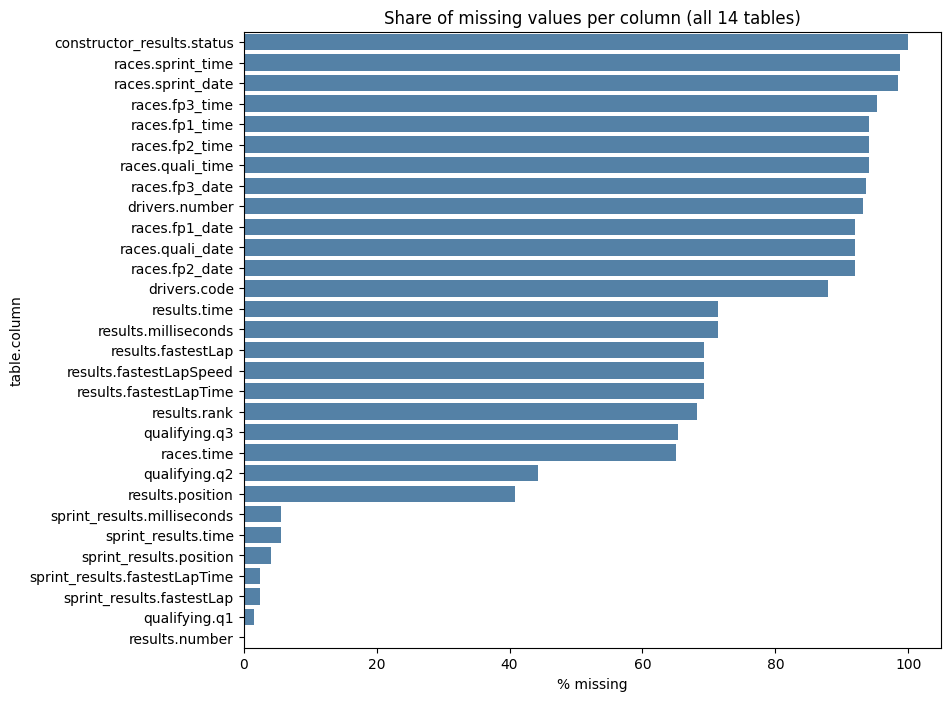

In [14]:
plt.figure(figsize=(9, 8))
sns.barplot(data=missing, y=missing['table'] + '.' + missing['column'], x='pct_missing', color='steelblue')
plt.title('Share of missing values per column (all 14 tables)')
plt.xlabel('% missing'); plt.ylabel('table.column')
plt.show()

**What we see:** the mostly-empty columns are practice/sprint dates (only filled from 2021), driver number/code,
fastest-lap columns (only from 2004), race `time`/`position` (empty for drivers who did not finish — a post-race
result, not a gap) and qualifying `q2`/`q3` (empty for drivers knocked out in Q1/Q2). None of these is a feature
we need before the race, except the qualifying times, where we will use each driver's best time.

### 2.3 Missing pattern over time (`msno.matrix`, rows sorted by season)

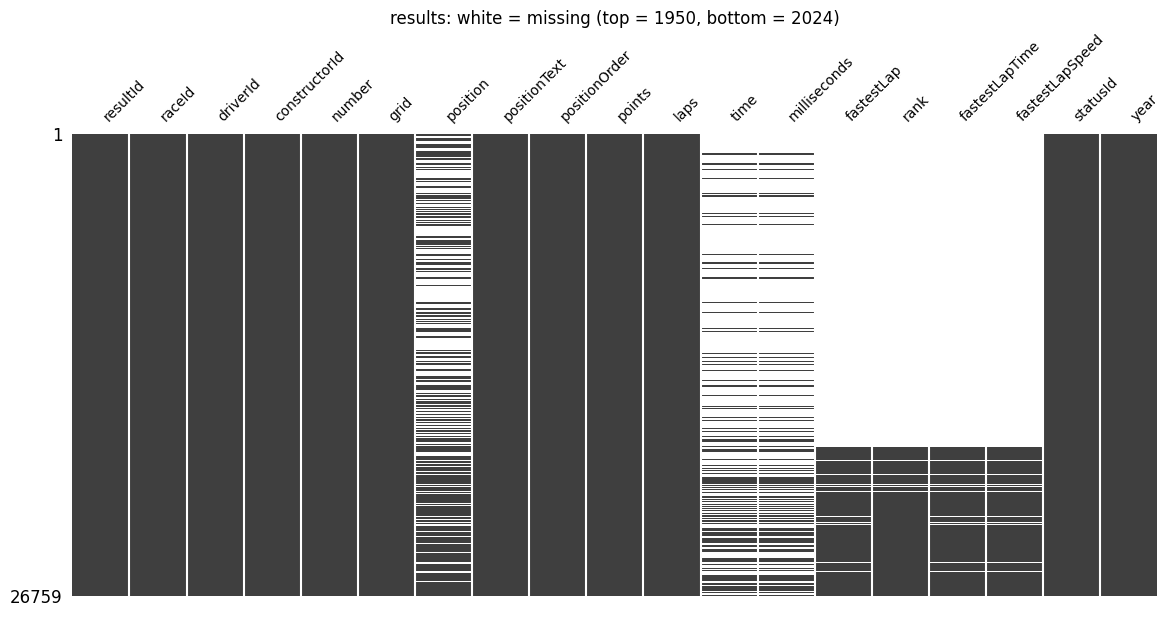

In [15]:
res_y = results.merge(races[['raceId', 'year']], on='raceId').sort_values(['year', 'raceId'])
msno.matrix(res_y, figsize=(14, 6), fontsize=10, sparkline=False)
plt.title('results: white = missing (top = 1950, bottom = 2024)')
plt.show()

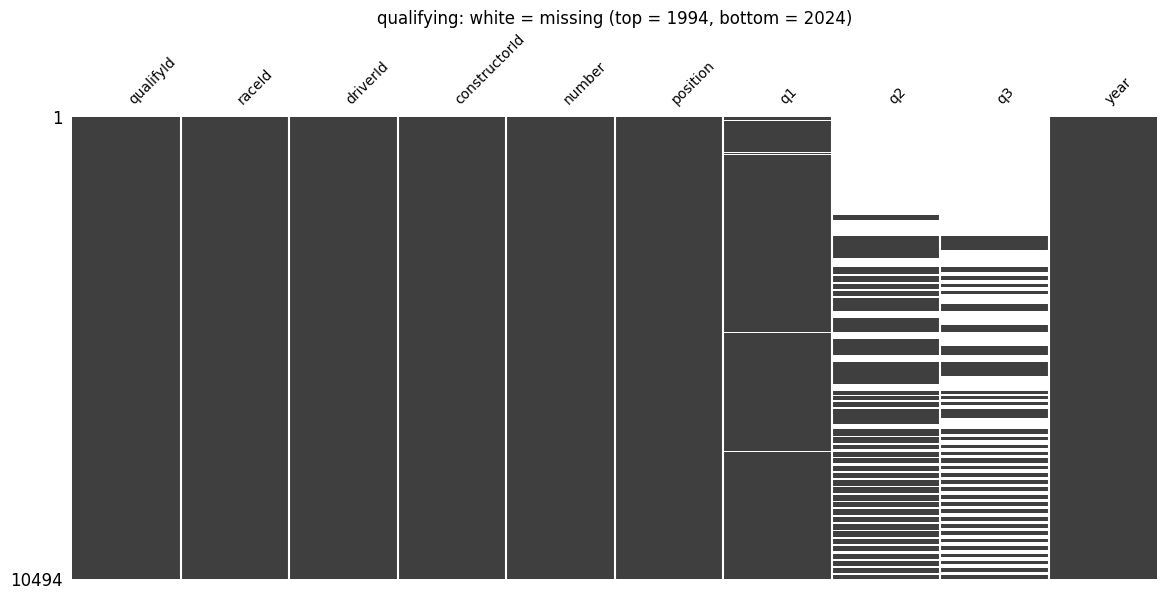

In [16]:
q_y = qualifying.merge(races[['raceId', 'year']], on='raceId').sort_values(['year', 'raceId'])
msno.matrix(q_y, figsize=(14, 6), fontsize=10, sparkline=False)
plt.title('qualifying: white = missing (top = 1994, bottom = 2024)')
plt.show()

**What we see:** in `results` the fastest-lap block only starts in 2004; `grid`, `positionOrder` and `statusId`
have no gaps. `qualifying` has **no rows before 1994**, and `q2`/`q3` only start in 2006.

### 2.4 Qualifying coverage per season

In [17]:
# mark every race that has at least one qualifying row, then count per season
races_q = races.copy()
races_q['has_quali'] = races_q['raceId'].isin(qualifying['raceId'])
coverage = races_q.groupby('year').agg(races=('raceId', 'count'), with_quali=('has_quali', 'sum'))
coverage['pct'] = (100 * coverage['with_quali'] / coverage['races']).round(0)
print(coverage.loc[1992:2005])

      races  with_quali    pct
year                          
1992     16           0    0.0
1993     16           0    0.0
1994     16          15   94.0
1995     17          17  100.0
1996     16           7   44.0
1997     17          10   59.0
1998     16           7   44.0
1999     16           3   19.0
2000     17           4   24.0
2001     17           1    6.0
2002     17           2   12.0
2003     16          16  100.0
2004     18          18  100.0
2005     19          19  100.0


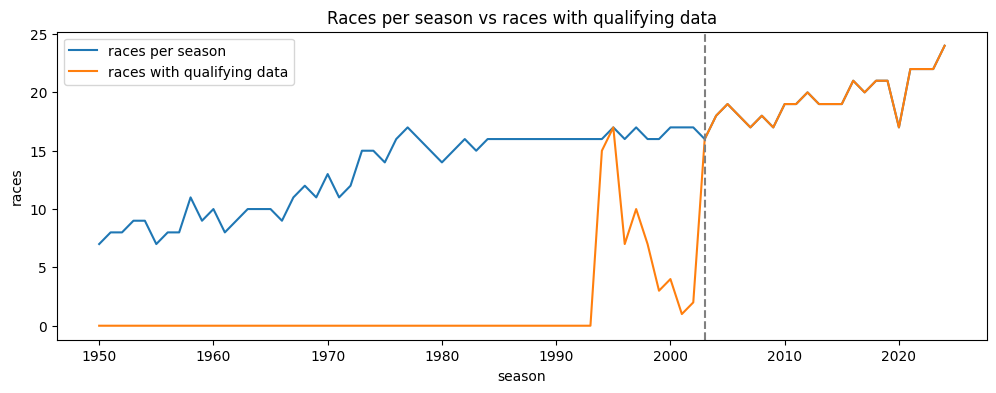

In [18]:
plt.figure(figsize=(12, 4))
plt.plot(coverage.index, coverage['races'], label='races per season')
plt.plot(coverage.index, coverage['with_quali'], label='races with qualifying data')
plt.axvline(2003, color='grey', linestyle='--')
plt.title('Races per season vs races with qualifying data')
plt.xlabel('season'); plt.ylabel('races'); plt.legend()
plt.show()

**What we see:** qualifying is missing for every race before 1994 and for most races in 1996–2002;
it is complete from **2003**. That is why the model is trained on 2003–2019 only.

### 2.5 How each entry ended (`positionText` codes)

positionText
R    8897
F    1368
3    1135
4    1135
2    1133
5    1131
1    1128
6    1124
7    1104
8    1076
Name: count, dtype: int64


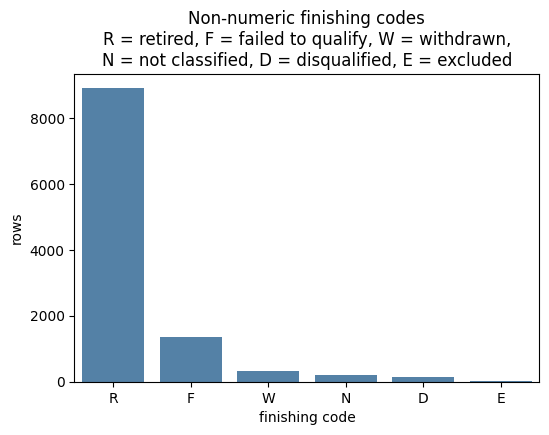

In [19]:
print(results['positionText'].value_counts().head(10))
codes = results.loc[~results['positionText'].str.isdigit(), 'positionText'].value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=codes.index, y=codes.values, color='steelblue')
plt.title('Non-numeric finishing codes\nR = retired, F = failed to qualify, W = withdrawn,\nN = not classified, D = disqualified, E = excluded')
plt.xlabel('finishing code')
plt.ylabel('rows')
plt.show()

**What we see:** F (failed to qualify) and W (withdrawn) rows never started the race, so they are removed in cleaning.

### 2.6 Podium share per season (raw data)

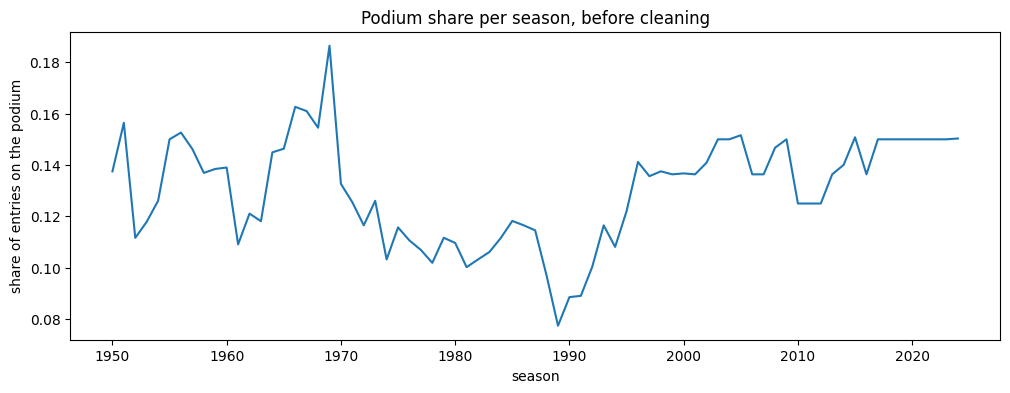

In [20]:
raw = results.merge(races[['raceId', 'year']], on='raceId')
raw['podium'] = (raw['positionOrder'] <= 3).astype(int)
plt.figure(figsize=(12, 4))
raw.groupby('year')['podium'].mean().plot()
plt.title('Podium share per season, before cleaning')
plt.xlabel('season'); plt.ylabel('share of entries on the podium')
plt.show()

**What we see:** the share is low in the late 1980s because up to ~39 cars entered for 26 places; after removing
non-starters it becomes comparable across seasons (shown again after cleaning).

## 3. Cleaning
Why: the raw tables mix real starters with entries that never raced, contain one race that is not really F1
(Indianapolis 500), have a few drivers with two rows in the same race, and store standings *after* each race.
We fix this with 10 rules, each with a short reason and a cell that prints the numbers before and after.
The result is one table `df` with **one row per (raceId, driverId)** and the target `podium`.
The raw CSV files are never changed: `/kaggle/input` is read-only and every rule works on in-memory copies of the tables.

### 3.1 Rule 1 — missing values, dates and lap times
`\N` was already turned into NaN when loading. Dates are stored as text, so we convert them with `pd.to_datetime`.
Qualifying times are strings like `1:27.452`; we convert them to seconds so we can compute gaps later.
One qualifying time (`16:42.640`, about 1,000 s) is impossible for one lap, so it becomes missing.

In [21]:
print('before:', races['date'].dtype, '|', drivers['dob'].dtype, '|', qualifying['q1'].dtype)
races['date'] = pd.to_datetime(races['date'])
drivers['dob'] = pd.to_datetime(drivers['dob'])

def to_seconds(t):
    # '1:27.452' -> 87.452 ; missing or unreadable -> NaN
    try:
        parts = str(t).split(':')
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])
        return float(parts[0])
    except ValueError:
        return np.nan

for q in ['q1', 'q2', 'q3']:
    qualifying[q + '_s'] = qualifying[q].apply(to_seconds)
print('after: ', races['date'].dtype, '|', drivers['dob'].dtype, '|', qualifying['q1_s'].dtype)
print(qualifying[['q1', 'q1_s', 'q2', 'q2_s']].head(3))

# a qualifying lap longer than 300 s is a typing error
bad = qualifying[['q1_s', 'q2_s', 'q3_s']] > 300
print('\nimpossible qualifying times:')
print(qualifying.loc[bad.any(axis=1), ['raceId', 'driverId', 'q1', 'q1_s']])
for q in ['q1_s', 'q2_s', 'q3_s']:
    qualifying.loc[qualifying[q] > 300, q] = np.nan
print('set to missing:', int(bad.values.sum()))

before: object | object | object
after:  datetime64[ns] | datetime64[ns] | float64
         q1    q1_s        q2    q2_s
0  1:26.572  86.572  1:25.187  85.187
1  1:26.103  86.103  1:25.315  85.315
2  1:25.664  85.664  1:25.452  85.452

impossible qualifying times:
      raceId  driverId         q1     q1_s
2567     255        87  16:42.640  1002.64
set to missing: 1


### 3.2 Rule 2 — primary-key and foreign-key checks
Why: before joining tables we check that every id is unique in its own table (primary key) and that every id used
in another table exists (foreign key). A broken key would silently drop or duplicate rows in a merge.
The last row checks our grain, one row per (raceId, driverId), in the raw `results`.

In [22]:
# primary key of every table (lap_times and pit_stops need several columns together)
primary_keys = {'races': ['raceId'], 'drivers': ['driverId'], 'constructors': ['constructorId'],
                'circuits': ['circuitId'], 'status': ['statusId'], 'seasons': ['year'],
                'results': ['resultId'], 'sprint_results': ['resultId'], 'qualifying': ['qualifyId'],
                'driver_standings': ['driverStandingsId'], 'constructor_standings': ['constructorStandingsId'],
                'constructor_results': ['constructorResultsId'],
                'lap_times': ['raceId', 'driverId', 'lap'], 'pit_stops': ['raceId', 'driverId', 'stop']}
# (child table, column, parent table): every value in the child must exist in the parent
foreign_keys = [('results', 'raceId', 'races'), ('results', 'driverId', 'drivers'),
                ('results', 'constructorId', 'constructors'), ('results', 'statusId', 'status'),
                ('races', 'circuitId', 'circuits'), ('races', 'year', 'seasons'),
                ('qualifying', 'raceId', 'races'), ('qualifying', 'driverId', 'drivers'),
                ('qualifying', 'constructorId', 'constructors'),
                ('driver_standings', 'raceId', 'races'), ('driver_standings', 'driverId', 'drivers'),
                ('constructor_standings', 'raceId', 'races'), ('constructor_standings', 'constructorId', 'constructors'),
                ('constructor_results', 'raceId', 'races'), ('constructor_results', 'constructorId', 'constructors'),
                ('lap_times', 'raceId', 'races'), ('lap_times', 'driverId', 'drivers'),
                ('pit_stops', 'raceId', 'races'), ('pit_stops', 'driverId', 'drivers'),
                ('sprint_results', 'raceId', 'races'), ('sprint_results', 'driverId', 'drivers'),
                ('sprint_results', 'constructorId', 'constructors'), ('sprint_results', 'statusId', 'status')]

rows = []
for t, cols in primary_keys.items():
    duplicates = tables[t].duplicated(cols).sum()
    missing = tables[t][cols].isnull().any(axis=1).sum()
    rows.append({'check': 'primary key', 'table': t, 'key': ', '.join(cols), 'problems': int(duplicates + missing)})
for child, col, parent in foreign_keys:
    orphans = ~tables[child][col].isin(tables[parent][col])
    rows.append({'check': 'foreign key', 'table': child, 'key': col + ' -> ' + parent, 'problems': int(orphans.sum())})
rows.append({'check': 'grain', 'table': 'results', 'key': '(raceId, driverId)',
             'problems': int(results.duplicated(['raceId', 'driverId']).sum())})
key_checks = pd.DataFrame(rows)
print('tables checked:', len(primary_keys), '| foreign keys checked:', len(foreign_keys))
key_checks

tables checked: 14 | foreign keys checked: 23


,check,table,key,problems
0,primary key,races,raceId,0
1,primary key,drivers,driverId,0
2,primary key,constructors,constructorId,0
3,primary key,circuits,circuitId,0
4,primary key,status,statusId,0
5,primary key,seasons,year,0
6,primary key,results,resultId,0
7,primary key,sprint_results,resultId,0
8,primary key,qualifying,qualifyId,0
9,primary key,driver_standings,driverStandingsId,0


**What we see:** the primary keys of all 14 tables are unique and not missing (lap_times and pit_stops use
composite keys), and all 23 foreign keys exist in their parent table. The only problem is the grain: some
drivers have two rows in the same race (shared drives, 1950–1964), which Rule 5 fixes.

We now build the working table `df` = `results` + race information, and count its rows after every rule that
removes rows (`funnel`).

In [23]:
df = results.merge(races[['raceId', 'year', 'round', 'circuitId', 'name', 'date']], on='raceId', how='left')
df = df.merge(status, on='statusId', how='left')
funnel = [('raw results', len(df))]
print(df.shape)

(26759, 24)


### 3.3 Rule 3 — remove the Indianapolis 500
Why: the Indy 500 counted for the championship in 1950–1960, but almost no F1 drivers entered it and it is an oval
race with its own rules. It also shares its `circuitId` with the later US Grand Prix, which would mix two different
tracks in circuit statistics. We remove it by race name.

In [24]:
indy = df['name'] == 'Indianapolis 500'
indy_circuit = df.loc[indy, 'circuitId'].unique()
other = races[races['circuitId'].isin(indy_circuit) & (races['name'] != 'Indianapolis 500')]
print('Indy 500 races:', df.loc[indy, 'raceId'].nunique(), '| rows:', int(indy.sum()),
      '| seasons', df.loc[indy, 'year'].min(), '-', df.loc[indy, 'year'].max())
print('circuitId', indy_circuit, 'is also used by', len(other), 'other races:', sorted(other['year']))

before = len(df)
df = df[~indy].copy()
print('rows before:', before, '| after:', len(df))
funnel.append(('minus Indy 500', len(df)))

Indy 500 races: 11 | rows: 405 | seasons 1950 - 1960
circuitId [19] is also used by 8 other races: [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007]
rows before: 26759 | after: 26354


### 3.4 Rule 4 — remove entries that never started the race
Why: we predict *after qualifying*, so we already know who failed to qualify or withdrew. Those rows can never be
on the podium and are not real prediction cases. A row is a non-starter if `positionText` is **F** (failed to
qualify) or **W** (withdrawn), or its status says it did not start **and** it completed 0 laps.
Some rows with status "Withdrew" did complete laps (they withdrew *during* the race), so they are kept.

In [25]:
not_started = ['Did not qualify', 'Did not prequalify', 'Withdrew', '107% Rule']
fw = df['positionText'].isin(['F', 'W'])
status_0laps = df['status'].isin(not_started) & (df['laps'] == 0)
raced = df['status'].isin(not_started) & (df['laps'] > 0)

print('F/W rows in raw results:', int(results['positionText'].isin(['F', 'W']).sum()))
print('F/W rows after Indy removal:', int(fw.sum()))
print('extra rows: not-started status with 0 laps:', int((status_0laps & ~fw).sum()))
print('not-started status but laps > 0 (raced -> kept):', int(raced.sum()))
print('podium rows among removed rows:', int((df.loc[fw | status_0laps, 'positionOrder'] <= 3).sum()))

before = len(df)
df = df[~(fw | status_0laps)].copy()
print('rows before:', before, '| after:', len(df))
funnel.append(('minus non-starters', len(df)))

F/W rows in raw results: 1704
F/W rows after Indy removal: 1704
extra rows: not-started status with 0 laps: 2
not-started status but laps > 0 (raced -> kept): 24
podium rows among removed rows: 0
rows before: 26354 | after: 24648


### 3.5 Rule 5 — shared drives: one row per (raceId, driverId)
Why: until the early 1960s (duplicates exist from 1950 to 1964) a driver could take over a team-mate's car during the race, so he has two rows in one
race. We keep the car the driver **started** in (the row with the best non-zero grid slot). Keeping the row with the
best *finish* instead would choose the row using the race result — a form of leakage. We also count how many podium
labels would differ under that alternative rule.

In [26]:
raw_dup = results.duplicated(['raceId', 'driverId'], keep=False)
print('duplicate keys in raw results:', results[raw_dup].groupby(['raceId', 'driverId']).ngroups)

dup = df.duplicated(['raceId', 'driverId'], keep=False)
print('duplicate keys now:', df[dup].groupby(['raceId', 'driverId']).ngroups, '| rows in them:', int(dup.sum()),
      '| seasons', df.loc[dup, 'year'].min(), '-', df.loc[dup, 'year'].max())

# alternative rule (for comparison only): podium if ANY of the driver's cars finished top 3
best_finish = df[dup].groupby(['raceId', 'driverId'])['positionOrder'].min() <= 3

# our rule: best non-zero grid slot first (grid 0 goes last), then the original entry
df['grid_rank'] = df['grid'].replace(0, 999)
df = df.sort_values(['raceId', 'driverId', 'grid_rank', 'resultId'])
before = len(df)
df = df.drop_duplicates(['raceId', 'driverId'], keep='first').drop(columns='grid_rank')

kept = df.set_index(['raceId', 'driverId']).loc[best_finish.index, 'positionOrder'] <= 3
print('podium labels that differ from the "best finish" rule:', int((kept != best_finish).sum()))
print('rows before:', before, '| after:', len(df))
funnel.append(('minus shared-drive duplicates', len(df)))

duplicate keys in raw results: 85
duplicate keys now: 61 | rows in them: 125 | seasons 1950 - 1964
podium labels that differ from the "best finish" rule: 17
rows before: 24648 | after: 24584


### 3.6 Rule 6 — grid = 0
Why: for a starter, `grid = 0` means the car did not start from a grid slot (pit-lane start, or not recorded in early
years). Left as 0 it would look *better* than pole position. We put these cars at the back of the grid
(`grid_pos` = number of starters in that race) and keep a flag `pitlane_start = 1`.

In [27]:
g0 = df['grid'] == 0
print('starters with grid 0:', int(g0.sum()), '| of them in 2010+:', int((g0 & (df['year'] >= 2010)).sum()))

df['field'] = df.groupby('raceId')['driverId'].transform('count')
df['pitlane_start'] = g0.astype(int)
df['grid_pos'] = df['grid'].where(~g0, df['field'])
print(df.loc[g0, ['year', 'name', 'grid', 'grid_pos', 'field']].tail())
print('grid_pos min / max:', df['grid_pos'].min(), '/', df['grid_pos'].max())

starters with grid 0: 87 | of them in 2010+: 73
       year                    name  grid  grid_pos  field
26607  2024   Azerbaijan Grand Prix     0        20     20
26613  2024   Azerbaijan Grand Prix     0        20     20
26671  2024  Mexico City Grand Prix     0        20     20
26694  2024    São Paulo Grand Prix     0        18     18
26712  2024    Las Vegas Grand Prix     0        20     20
grid_pos min / max: 1 / 34


### 3.7 Rule 7 — the target `podium`
`podium = 1` if `positionOrder <= 3`. `positionOrder` is filled for every row (unlike `position`, which is empty
for drivers who did not finish) and already includes disqualifications after the race.
A normal race has exactly 3 podium rows. A few 1950s races differ because of shared cars: some credit one car's
result to several drivers (more than 3 podium rows), and in others the podium car's result stays with the driver who
started it after Rule 5 (fewer than 3). We keep the labels as recorded.

In [28]:
df['podium'] = (df['positionOrder'] <= 3).astype(int)
per_race = df.groupby('raceId')['podium'].sum()
print('races:', len(per_race), '| with exactly 3 podium rows:', int((per_race == 3).sum()),
      '| more than 3:', int((per_race > 3).sum()), '| fewer than 3:', int((per_race < 3).sum()))
odd = df[df['raceId'].isin(per_race[per_race != 3].index)]
print(odd.groupby('raceId').agg(year=('year', 'first'), race=('name', 'first'), podium_rows=('podium', 'sum')))
print('\npodium share:', round(df['podium'].mean(), 3))

races: 1114 | with exactly 3 podium rows: 1109 | more than 3: 2 | fewer than 3: 3
        year                  race  podium_rows
raceId                                         
780     1957    British Grand Prix            2
789     1956    British Grand Prix            2
792     1955  Argentine Grand Prix            5
793     1955     Monaco Grand Prix            4
828     1951     French Grand Prix            2

podium share: 0.136


### 3.8 Rule 8 — championship standings *before* the race
Why: the standings tables are stored **after** each race, so they already contain the result we want to predict
(leakage). We take the standings of the **previous round** of the same season instead: standings after round *r*
are the standings before round *r + 1*. At round 1 (and for a driver's first race) there is no earlier row, so
points become 0 and the rank stays missing (filled later with the training median).

In [29]:
# proof of the leak: the standings of 2023 round 1 already include that race
r1 = races.loc[(races['year'] == 2023) & (races['round'] == 1), 'raceId'].iloc[0]
print('2023 round 1, standings stored for that race (top 3):')
print(driver_standings[driver_standings['raceId'] == r1].sort_values('position')[['driverId', 'points', 'position']].head(3))

same_race = df.merge(driver_standings[['raceId', 'driverId']], on=['raceId', 'driverId'], how='left', indicator=True)
print('\nrows with no standings row for their own race:', int((same_race['_merge'] == 'left_only').sum()))

# standings after round r -> standings before round r + 1
ds = driver_standings.merge(races[['raceId', 'year', 'round']], on='raceId')
ds['round'] = ds['round'] + 1
ds = ds.rename(columns={'points': 'drv_pts_before', 'position': 'drv_rank_before'})
cs = constructor_standings.merge(races[['raceId', 'year', 'round']], on='raceId')
cs['round'] = cs['round'] + 1
cs = cs.rename(columns={'points': 'con_pts_before', 'position': 'con_rank_before'})

before = len(df)
df = df.merge(ds[['year', 'round', 'driverId', 'drv_pts_before', 'drv_rank_before']],
              on=['year', 'round', 'driverId'], how='left')
df = df.merge(cs[['year', 'round', 'constructorId', 'con_pts_before', 'con_rank_before']],
              on=['year', 'round', 'constructorId'], how='left')
print('rows before merge:', before, '| after:', len(df))
print('missing before filling:\n', df[['drv_pts_before', 'drv_rank_before', 'con_pts_before', 'con_rank_before']].isnull().sum())
df['drv_pts_before'] = df['drv_pts_before'].fillna(0)
df['con_pts_before'] = df['con_pts_before'].fillna(0)
print('\ncheck - 2023 round 1, points before the race (should all be 0):', df.loc[df['raceId'] == r1, 'drv_pts_before'].max())

2023 round 1, standings stored for that race (top 3):
       driverId  points  position
33901       830    25.0         1
33900       815    18.0         2
33899         4    15.0         3

rows with no standings row for their own race: 420
rows before merge: 24584 | after: 24584
missing before filling:
 drv_pts_before     2892
drv_rank_before    2892
con_pts_before     2893
con_rank_before    2893
dtype: int64

check - 2023 round 1, points before the race (should all be 0): 0.0


### 3.9 Rule 9 — nationality and country (home race)
Why: Q2 and the `home_race` feature compare the driver's nationality ("British") with the circuit's country ("UK").
First we fix two spelling problems: circuits use both `USA` and `United States`, and drivers use both `Argentine`
and `Argentinian ` (with a trailing space). Then a small dictionary maps every nationality to its country
(dual nationalities to both countries).

In [30]:
print('circuit countries before:', circuits['country'].nunique(), '| nationality strings before:', drivers['nationality'].nunique())
circuits['country'] = circuits['country'].replace({'United States': 'USA'})
drivers['nationality'] = drivers['nationality'].str.strip().replace({'Argentinian': 'Argentine'})
print('circuit countries after: ', circuits['country'].nunique(), '| nationality strings after: ', drivers['nationality'].nunique())

home_country = {
    'American': ['USA'], 'American-Italian': ['USA', 'Italy'], 'Argentine': ['Argentina'],
    'Argentine-Italian': ['Argentina', 'Italy'], 'Australian': ['Australia'], 'Austrian': ['Austria'],
    'Belgian': ['Belgium'], 'Brazilian': ['Brazil'], 'British': ['UK'], 'Canadian': ['Canada'],
    'Chilean': ['Chile'], 'Chinese': ['China'], 'Colombian': ['Colombia'], 'Czech': ['Czech Republic'],
    'Danish': ['Denmark'], 'Dutch': ['Netherlands'], 'East German': ['Germany'], 'Finnish': ['Finland'],
    'French': ['France'], 'German': ['Germany'], 'Hungarian': ['Hungary'], 'Indian': ['India'],
    'Indonesian': ['Indonesia'], 'Irish': ['Ireland'], 'Italian': ['Italy'], 'Japanese': ['Japan'],
    'Liechtensteiner': ['Liechtenstein'], 'Malaysian': ['Malaysia'], 'Mexican': ['Mexico'],
    'Monegasque': ['Monaco'], 'New Zealander': ['New Zealand'], 'Polish': ['Poland'],
    'Portuguese': ['Portugal'], 'Rhodesian': ['Rhodesia'], 'Russian': ['Russia'],
    'South African': ['South Africa'], 'Spanish': ['Spain'], 'Swedish': ['Sweden'], 'Swiss': ['Switzerland'],
    'Thai': ['Thailand'], 'Uruguayan': ['Uruguay'], 'Venezuelan': ['Venezuela']}
print('nationalities without a mapping:', set(drivers['nationality']) - set(home_country))

df = df.merge(drivers[['driverId', 'nationality']], on='driverId', how='left')
df = df.merge(circuits[['circuitId', 'country']], on='circuitId', how='left')

# home race = the circuit is in (one of) the driver's home countries
home = []
for nationality, country in zip(df['nationality'], df['country']):
    home.append(int(country in home_country[nationality]))
df['home_race'] = home

print('home-race starts:', int(df['home_race'].sum()), '| since 2003:', int(df.loc[df['year'] >= 2003, 'home_race'].sum()))
print('podium share  home:', round(df.loc[df['home_race'] == 1, 'podium'].mean(), 3),
      '| away:', round(df.loc[df['home_race'] == 0, 'podium'].mean(), 3))

circuit countries before: 35 | nationality strings before: 43
circuit countries after:  34 | nationality strings after:  42
nationalities without a mapping: set()
home-race starts: 1932 | since 2003: 364
podium share  home: 0.116 | away: 0.138


### 3.10 Rule 10 — group the status values
Why: `status` has 139 values (Engine, Gearbox, Collision, +1 Lap, …). Q3 and the reliability feature need to know
whether a race ended because **a part of the car failed**. We map every status to one group:
`finished` (incl. lapped cars), `mechanical` (a clear component failure), `ambiguous` (could be a failure or contact,
e.g. Wheel, Tyre, Front wing), `accident`, `retired` (the generic "Retired", kept separate because it says nothing
about the cause) and `other` (disqualified, illness, out of fuel, …).

In [31]:
mechanical = ['Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Radiator',
              'Suspension', 'Brakes', 'Differential', 'Overheating', 'Mechanical', 'Driveshaft',
              'Fuel pressure', 'Water pressure', 'Throttle', 'Steering', 'Technical', 'Electronics',
              'Heat shield fire', 'Exhaust', 'Oil leak', 'Water leak', 'Fuel pump', 'Track rod',
              'Oil pressure', 'Engine fire', 'Wheel rim', 'Pneumatics', 'Wheel bearing', 'Fuel system',
              'Oil line', 'Launch control', 'Power loss', 'Vibrations', 'Drivetrain', 'Ignition',
              'Chassis', 'Battery', 'Halfshaft', 'Crankshaft', 'Alternator', 'Oil pump', 'Fuel leak',
              'Injection', 'Distributor', 'Turbo', 'CV joint', 'Water pump', 'Spark plugs', 'Fuel pipe',
              'Oil pipe', 'Axle', 'Water pipe', 'Magneto', 'Supercharger', 'Engine misfire', 'Power Unit',
              'ERS', 'Brake duct', 'Cooling system']
ambiguous = ['Wheel', 'Wheel nut', 'Tyre', 'Front wing', 'Rear wing', 'Broken wing', 'Handling', 'Fire',
             'Stalled', 'Fuel', 'Seat', 'Driver Seat', 'Safety belt', 'Undertray']
accident = ['Accident', 'Collision', 'Spun off', 'Collision damage', 'Fatal accident', 'Damage', 'Debris',
            'Puncture', 'Tyre puncture']

def status_group(s):
    if s == 'Finished' or s.startswith('+'):
        return 'finished'
    if s in mechanical:
        return 'mechanical'
    if s in ambiguous:
        return 'ambiguous'
    if s in accident:
        return 'accident'
    if s == 'Retired':
        return 'retired'
    return 'other'

status['status_group'] = status['status'].apply(status_group)
print('status values:', len(status), '| used in results:', results['statusId'].nunique())
print(status['status_group'].value_counts(), '\n')

df['status_group'] = df['status'].apply(status_group)
print(df['status_group'].value_counts())
print('\n"Retired" rows in 2014-2024:', int(((df['status'] == 'Retired') & (df['year'] >= 2014)).sum()))

status values: 139 | used in results: 137
status_group
mechanical    61
finished      34
other         20
ambiguous     14
accident       9
retired        1
Name: count, dtype: int64 

status_group
finished      14928
mechanical     6103
accident       2719
other           493
ambiguous       243
retired          98
Name: count, dtype: int64

"Retired" rows in 2014-2024: 49


### 3.11 Cleaning funnel and final checks
We keep only the columns needed later and check the final table: one row per (raceId, driverId), no missing
target, and every id still exists in its parent table.

In [32]:
cols = ['raceId', 'year', 'round', 'date', 'name', 'circuitId', 'country', 'driverId', 'nationality',
        'constructorId', 'grid', 'grid_pos', 'pitlane_start', 'field', 'drv_pts_before', 'drv_rank_before',
        'con_pts_before', 'con_rank_before', 'home_race', 'positionOrder', 'laps', 'status', 'status_group', 'podium']
df = df[cols].sort_values(['year', 'round', 'grid_pos']).reset_index(drop=True)

final_checks = pd.DataFrame([
    {'check': 'one row per (raceId, driverId)', 'problems': int(df.duplicated(['raceId', 'driverId']).sum())},
    {'check': 'podium not missing', 'problems': int(df['podium'].isnull().sum())},
    {'check': 'raceId exists in races', 'problems': int((~df['raceId'].isin(races['raceId'])).sum())},
    {'check': 'driverId exists in drivers', 'problems': int((~df['driverId'].isin(drivers['driverId'])).sum())},
    {'check': 'constructorId exists in constructors', 'problems': int((~df['constructorId'].isin(constructors['constructorId'])).sum())},
    {'check': 'circuit country found', 'problems': int(df['country'].isnull().sum())},
])
print('df shape:', df.shape, '| podium share:', round(df['podium'].mean(), 3))
final_checks

df shape: (24584, 24) | podium share: 0.136


,check,problems
0,"one row per (raceId, driverId)",0
1,podium not missing,0
2,raceId exists in races,0
3,driverId exists in drivers,0
4,constructorId exists in constructors,0
5,circuit country found,0


                            step   rows  removed
0                    raw results  26759        0
1                 minus Indy 500  26354      405
2             minus non-starters  24648     1706
3  minus shared-drive duplicates  24584       64


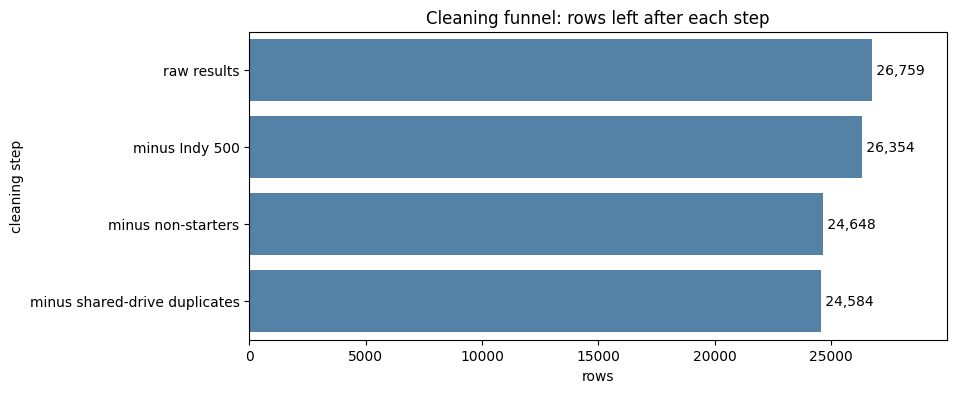

In [33]:
funnel_df = pd.DataFrame(funnel, columns=['step', 'rows'])
funnel_df['removed'] = (-funnel_df['rows'].diff()).fillna(0).astype(int)
print(funnel_df)

plt.figure(figsize=(9, 4))
sns.barplot(data=funnel_df, x='rows', y='step', color='steelblue')
for i, r in enumerate(funnel_df['rows']):
    plt.text(r, i, f' {r:,}', va='center')
plt.title('Cleaning funnel: rows left after each step')
plt.xlabel('rows'); plt.ylabel('cleaning step')
plt.xlim(0, funnel_df['rows'].max() * 1.12)
plt.show()

**What we see:** removing non-starters is by far the biggest step (1,706 rows); the Indy 500 removes 405 rows and
the shared-drive duplicates 64. Rules 6–10 change values, not rows. `df` keeps 24,584 rows, one per
(raceId, driverId), all key checks pass, and it is ready for EDA after cleaning (section 4).

## 4. EDA after cleaning
Why: we look at the cleaned table `df` the same way as before cleaning (Lab 1: `info`, `describe`, `isnull().sum()`),
then plot how the target behaves: over time, by grid slot, by era, and how close drivers are in qualifying.

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24584 entries, 0 to 24583
Data columns (total 24 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   raceId           24584 non-null  int64         
 1   year             24584 non-null  int64         
 2   round            24584 non-null  int64         
 3   date             24584 non-null  datetime64[ns]
 4   name             24584 non-null  object        
 5   circuitId        24584 non-null  int64         
 6   country          24584 non-null  object        
 7   driverId         24584 non-null  int64         
 8   nationality      24584 non-null  object        
 9   constructorId    24584 non-null  int64         
 10  grid             24584 non-null  int64         
 11  grid_pos         24584 non-null  int64         
 12  pitlane_start    24584 non-null  int64         
 13  field            24584 non-null  int64         
 14  drv_pts_before   24584 non-null  float

In [35]:
df.describe()

,raceId,year,round,date,circuitId,driverId,constructorId,grid,grid_pos,pitlane_start,field,drv_pts_before,drv_rank_before,con_pts_before,con_rank_before,home_race,positionOrder,laps,podium
count,24584.000000,24584.000000,24584.000000,24584,24584.000000,24584.000000,24584.000000,24584.000000,24584.000000,24584.000000,24584.000000,24584.000000,21692.000000,24584.000000,21691.000000,24584.000000,24584.000000,24584.000000,24584.000000
mean,551.466808,1992.780467,8.683575,1993-04-23 13:28:33.895216512,23.926578,276.291450,48.495322,11.718231,11.792670,0.003539,22.499756,18.171632,12.847409,36.685995,6.101839,0.078588,11.743004,47.885739,0.135942
min,1.000000,1950.000000,1.000000,1950-05-13 00:00:00,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000
25%,285.000000,1978.000000,4.000000,1978-05-07 00:00:00,9.000000,52.000000,6.000000,6.000000,6.000000,0.000000,20.000000,0.000000,6.000000,0.000000,3.000000,0.000000,6.000000,30.000000,0.000000
50%,530.000000,1993.000000,8.000000,1993-09-26 00:00:00,18.000000,163.000000,22.000000,11.000000,12.000000,0.000000,22.000000,3.000000,12.000000,8.000000,6.000000,0.000000,12.000000,53.000000,0.000000
75%,828.000000,2010.000000,13.000000,2010-07-25 00:00:00,34.000000,383.000000,57.250000,17.000000,17.000000,0.000000,25.000000,16.000000,18.000000,33.000000,9.000000,0.000000,17.000000,67.000000,0.000000
max,1144.000000,2024.000000,24.000000,2024-12-08 00:00:00,80.000000,862.000000,215.000000,34.000000,34.000000,1.000000,34.000000,549.000000,102.000000,822.000000,20.000000,1.000000,34.000000,110.000000,1.000000
std,321.237888,19.697718,5.088732,NaN,19.421083,288.329371,62.370841,6.764617,6.752516,0.059384,3.014035,42.115766,8.944398,81.438489,3.633904,0.269100,6.718315,23.959122,0.342734


In [36]:
print(df.isnull().sum())

raceId                0
year                  0
round                 0
date                  0
name                  0
circuitId             0
country               0
driverId              0
nationality           0
constructorId         0
grid                  0
grid_pos              0
pitlane_start         0
field                 0
drv_pts_before        0
drv_rank_before    2892
con_pts_before        0
con_rank_before    2893
home_race             0
positionOrder         0
laps                  0
status                0
status_group          0
podium                0
dtype: int64


**What we see:** `df` has 24,584 rows and no missing values except the rank before the race: `drv_rank_before`
(2,892) and `con_rank_before` (2,893) are empty at round 1, for a driver's first race, and before the constructors'
championship started (1958). Grid positions now run from 1 to 34 (no more 0), and 0.35 % of starts are pit-lane starts.

### 4.1 Podium share per season, before vs after cleaning

1980-1995 mean share  before: 0.105 | after: 0.119
2003-2024 mean share  before: 0.144 | after: 0.145


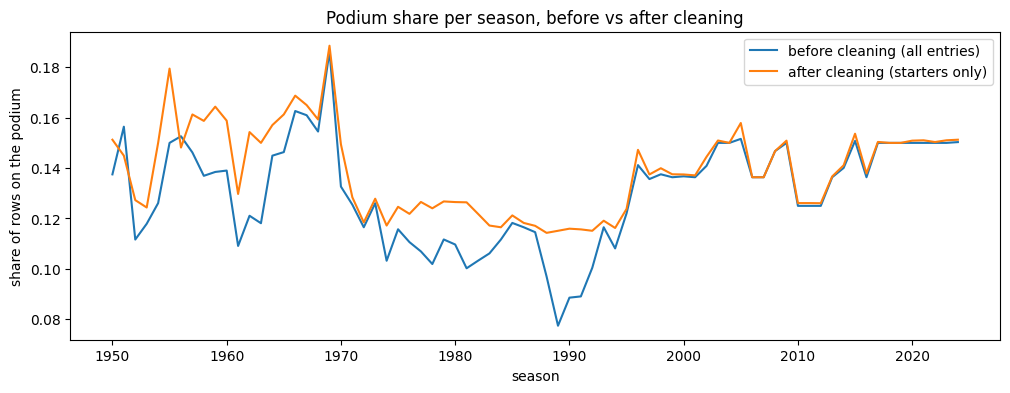

In [37]:
share_before = raw.groupby('year')['podium'].mean()
share_after = df.groupby('year')['podium'].mean()
print('1980-1995 mean share  before:', round(share_before.loc[1980:1995].mean(), 3),
      '| after:', round(share_after.loc[1980:1995].mean(), 3))
print('2003-2024 mean share  before:', round(share_before.loc[2003:].mean(), 3),
      '| after:', round(share_after.loc[2003:].mean(), 3))

plt.figure(figsize=(12, 4))
plt.plot(share_before.index, share_before.values, label='before cleaning (all entries)')
plt.plot(share_after.index, share_after.values, label='after cleaning (starters only)')
plt.title('Podium share per season, before vs after cleaning')
plt.xlabel('season'); plt.ylabel('share of rows on the podium'); plt.legend()
plt.show()

**What we see:** cleaning changes the share mainly in the non-qualifier era: in 1980–1995 it rises from 0.105 to
0.119 because non-starters are gone, while 2003–2024 barely moves (0.144 → 0.145). The target is now comparable across
seasons, at about 14–15 % in the modelling years.

### 4.2 Podium rate by grid slot (1–20)

grid
1    0.641
2    0.561
3    0.463
4    0.346
5    0.250
6    0.186
Name: podium, dtype: float64


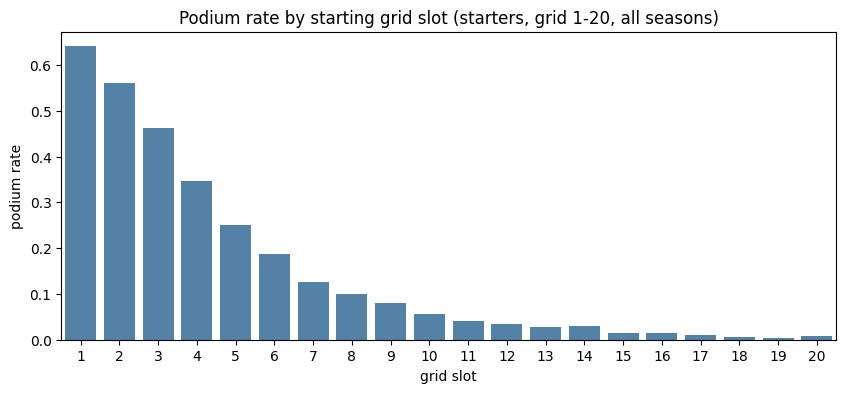

In [38]:
by_grid = df[df['grid'].between(1, 20)].groupby('grid')['podium'].mean()
print(by_grid.head(6).round(3))

plt.figure(figsize=(10, 4))
sns.barplot(x=by_grid.index, y=by_grid.values, color='steelblue')
plt.title('Podium rate by starting grid slot (starters, grid 1-20, all seasons)')
plt.xlabel('grid slot'); plt.ylabel('podium rate')
plt.show()

**What we see:** the podium rate falls steeply with the starting slot: P1 64 %, P2 56 %, P3 46 %, P4 35 %, P5 25 %,
P6 19 %, about 6 % at P10 and only a few percent further back. Grid position is the single strongest pre-race signal.

### 4.3 Podium rate by era and grid group (pivot heatmap)
Eras follow the big rule changes: 1950–93, 1994–2013 (refuelling / modern qualifying), 2014–24 (hybrid engines).
Pit-lane starters count as starting from the back (`grid_pos`).

grid_group      1    2-3    4-6   7-10    11+
era                                          
1950-93     0.525  0.446  0.288  0.120  0.019
1994-2013   0.712  0.537  0.248  0.078  0.014
2014-24     0.811  0.631  0.218  0.042  0.012

starts per era: {'1950-93': 12364, '1994-2013': 7622, '2014-24': 4598}


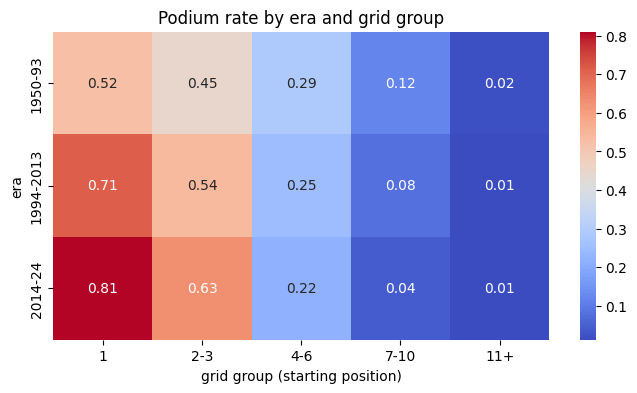

In [39]:
era_bins, era_labels = [1949, 1993, 2013, 2024], ['1950-93', '1994-2013', '2014-24']
grid_bins, grid_labels = [0, 1, 3, 6, 10, 100], ['1', '2-3', '4-6', '7-10', '11+']
h = df.assign(era=pd.cut(df['year'], bins=era_bins, labels=era_labels),
              grid_group=pd.cut(df['grid_pos'], bins=grid_bins, labels=grid_labels))
pivot = pd.pivot_table(h, values='podium', index='era', columns='grid_group', aggfunc='mean', observed=False)
print(pivot.round(3))
print('\nstarts per era:', h['era'].value_counts().sort_index().to_dict())

plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Podium rate by era and grid group')
plt.xlabel('grid group (starting position)'); plt.ylabel('era')
plt.show()

**What we see:** the front of the grid has become more decisive over time. Pole converts to a podium 52 % of the time
in 1950–93, 71 % in 1994–2013 and 81 % in 2014–24 (slots 2–3: 45 % → 54 % → 63 %), while slots 7–10 fall from 12 % to
4 %. Because of this drift we train on recent seasons only (2003+) and treat the era as a limitation.

### 4.4 Qualifying gap to pole (2003+)
For each driver we take the best time of Q1/Q2/Q3 and compare it with the fastest time of that race:
`gap % = 100 × (best − pole) / pole`. Only 2003+ seasons, where qualifying is complete.

rows: 24584 -> 24584
2003+ starts: 8910 | without a qualifying time: 144
count    8766.00
mean        2.27
std         2.58
min         0.00
25%         0.83
50%         1.72
75%         2.87
max        45.60
Name: gap_pct, dtype: float64
share of gaps above 10 %: 0.013
median gap  podium: 0.33 | no podium: 1.99


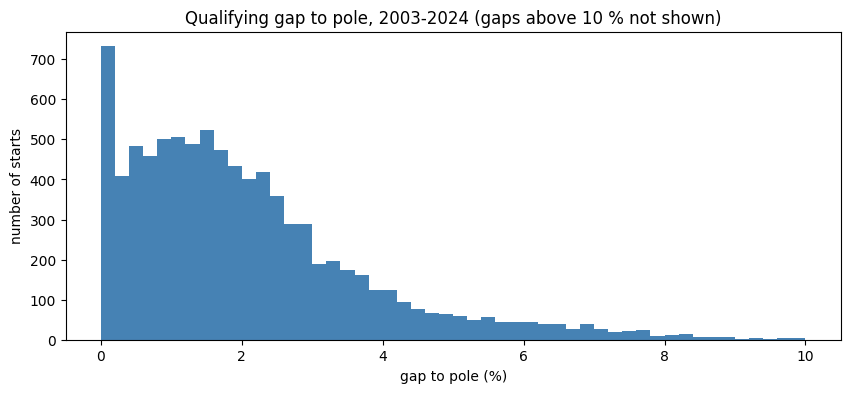

In [40]:
q = qualifying[['raceId', 'driverId', 'q1_s', 'q2_s', 'q3_s']].copy()
q['best_s'] = q[['q1_s', 'q2_s', 'q3_s']].min(axis=1)
q['pole_s'] = q.groupby('raceId')['best_s'].transform('min')
q['gap_pct'] = 100 * (q['best_s'] - q['pole_s']) / q['pole_s']

quali = df.merge(q[['raceId', 'driverId', 'best_s', 'gap_pct']], on=['raceId', 'driverId'], how='left')
print('rows:', len(df), '->', len(quali))
modern = quali[quali['year'] >= 2003]
print('2003+ starts:', len(modern), '| without a qualifying time:', int(modern['gap_pct'].isnull().sum()))
print(modern['gap_pct'].describe().round(2))
print('share of gaps above 10 %:', round((modern['gap_pct'] > 10).mean(), 3))
print('median gap  podium:', round(modern.loc[modern['podium'] == 1, 'gap_pct'].median(), 2),
      '| no podium:', round(modern.loc[modern['podium'] == 0, 'gap_pct'].median(), 2))

plt.figure(figsize=(10, 4))
plt.hist(modern['gap_pct'].dropna(), bins=50, range=(0, 10), color='steelblue')
plt.title('Qualifying gap to pole, 2003-2024 (gaps above 10 % not shown)')
plt.xlabel('gap to pole (%)'); plt.ylabel('number of starts')
plt.show()

**What we see:** among 8,910 starts since 2003 (144 without a qualifying time), half are within 1.7 % of pole and
75 % within 2.9 %; only 1.3 % are more than 10 % off (wet sessions or problems). Podium finishers qualified a median
0.33 % behind pole, everyone else 1.99 % — a strong signal, as expected.

### 4.5 Qualifying lap time by era
Each driver's best qualifying lap (seconds), grouped by era. Qualifying data starts in 1994, so 1950–93 has no times.
Lap times also depend on the circuit mix of each era, so this shows the spread and outliers rather than pure car speed.

            count  mean   std   min   25%   50%   75%    max
era                                                         
1994-2013  5733.0  88.6  11.6  69.2  80.0  86.6  95.6  153.9
2014-24    4533.0  86.9  13.0  53.4  76.9  86.8  95.0  141.6


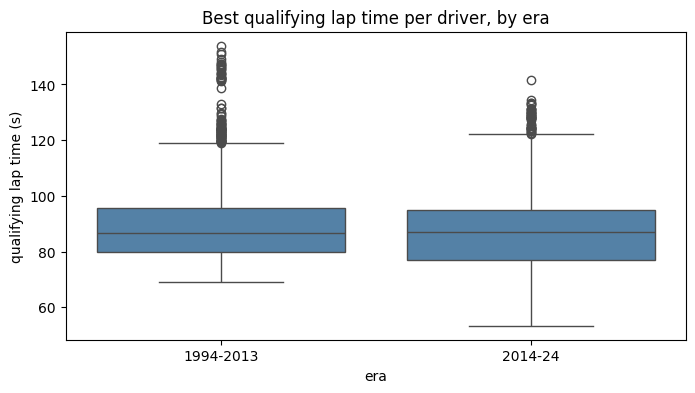

In [41]:
qe = quali[quali['year'] >= 1994].copy()
qe['era'] = pd.cut(qe['year'], bins=[1993, 2013, 2024], labels=['1994-2013', '2014-24'])
print(qe.groupby('era', observed=True)['best_s'].describe().round(1))

plt.figure(figsize=(8, 4))
sns.boxplot(data=qe, x='era', y='best_s', color='steelblue')
plt.title('Best qualifying lap time per driver, by era')
plt.xlabel('era'); plt.ylabel('qualifying lap time (s)')
plt.show()

**What we see:** the median qualifying lap is almost the same in both eras (86.6 s vs 86.8 s), because circuit length
dominates lap time. The long upper tails (up to 154 s) are wet or very long laps, and the 53 s minimum in 2014–24 is the
short Bahrain outer loop (2020). Raw lap times therefore say little about the podium; the gap to pole (4.4) is the
useful, comparable version.

## 5. Q1 — front row → podium by circuit
> *"Which circuits convert a front-row start into a podium most often, and does that ranking change after the 2014
> hybrid era? Distinguish qualifying position from grid (which can differ due to penalties)."*

Joins: `results` → `races` (season, circuit) → `circuits` (circuit name) → `qualifying` (qualifying position).
A **front-row start** is grid slot 1 or 2. We compare 1994–2013 with 2014–24 (qualifying data starts in 1994) and
keep only circuits with **at least 10 front-row starts in both eras**, so a rate is not based on a handful of races.

In [42]:
# add the qualifying position and the circuit name to every start since 1994
quali_pos = qualifying[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'})
circuit_names = circuits[['circuitId', 'name']].rename(columns={'name': 'circuit'})
fr = df[df['year'] >= 1994].merge(quali_pos, on=['raceId', 'driverId'], how='left')
fr = fr.merge(circuit_names, on='circuitId', how='left')
fr['era'] = np.where(fr['year'] >= 2014, '2014-24', '1994-2013')
print('starts 1994+:', len(fr), '| without a qualifying row:', int(fr['quali_pos'].isnull().sum()))

# front-row starts: number per circuit and era, and podium rate per circuit and era
front = fr[fr['grid'].between(1, 2)]
n_front = pd.pivot_table(front, values='podium', index='circuit', columns='era', aggfunc='count')
rate = pd.pivot_table(front, values='podium', index='circuit', columns='era', aggfunc='mean')
enough = (n_front['1994-2013'] >= 10) & (n_front['2014-24'] >= 10)
both = n_front[enough].index
print('circuits with front-row starts:', len(n_front), '| with >= 10 in both eras:', len(both))

q1 = rate.loc[both].round(3)
q1['starts 1994-2013'] = n_front.loc[both, '1994-2013']
q1['starts 2014-24'] = n_front.loc[both, '2014-24']
q1['rank 1994-2013'] = q1['1994-2013'].rank(ascending=False, method='min').astype(int)
q1['rank 2014-24'] = q1['2014-24'].rank(ascending=False, method='min').astype(int)

print('\nTop 10 circuits, 1994-2013:')
top_old = q1.sort_values('1994-2013', ascending=False).head(10)
print(top_old[['1994-2013', 'starts 1994-2013', 'rank 2014-24']])
print('\nTop 10 circuits, 2014-24:')
top_new = q1.sort_values('2014-24', ascending=False).head(10)
print(top_new[['2014-24', 'starts 2014-24', 'rank 1994-2013']])

spearman_q1 = q1['1994-2013'].corr(q1['2014-24'], method='spearman')
print('\nrank correlation between the eras (Spearman):', round(spearman_q1, 2))
print('circuits where conversion rose after 2014:', int((q1['2014-24'] > q1['1994-2013']).sum()), 'of', len(q1))
rate_old = front.loc[front['era'] == '1994-2013', 'podium'].mean()
rate_new = front.loc[front['era'] == '2014-24', 'podium'].mean()
print('all front-row starts  1994-2013:', round(rate_old, 3), '| 2014-24:', round(rate_new, 3))

starts 1994+: 12220 | without a qualifying row: 1802
circuits with front-row starts: 43 | with >= 10 in both eras: 15

Top 10 circuits, 1994-2013:
era                             1994-2013  starts 1994-2013  rank 2014-24
circuit                                                                  
Suzuka Circuit                      0.750              36.0             2
Hungaroring                         0.725              40.0            15
Bahrain International Circuit       0.667              18.0            14
Circuit de Barcelona-Catalunya      0.667              39.0             4
Shanghai International Circuit      0.650              20.0             7
Circuit de Monaco                   0.650              40.0             1
Autodromo Nazionale di Monza        0.650              40.0            11
Red Bull Ring                       0.643              14.0            10
Silverstone Circuit                 0.625              40.0             9
Yas Marina Circuit                  0.6

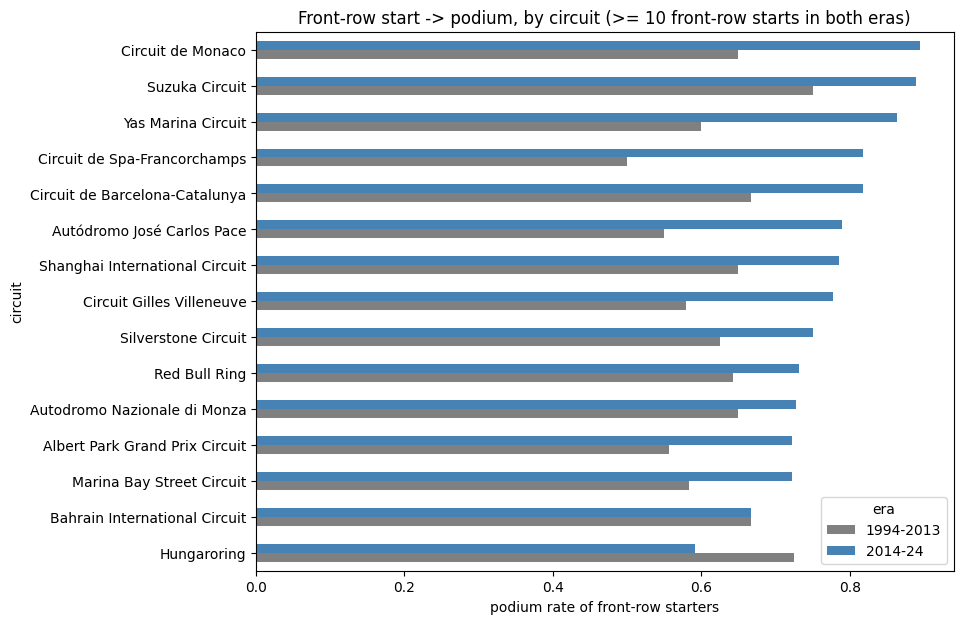

In [43]:
plot_q1 = q1.sort_values('2014-24')[['1994-2013', '2014-24']]
plot_q1.plot(kind='barh', figsize=(9, 7), color=['grey', 'steelblue'])
plt.title('Front-row start -> podium, by circuit (>= 10 front-row starts in both eras)')
plt.xlabel('podium rate of front-row starters'); plt.ylabel('circuit')
plt.legend(title='era')
plt.show()

**What we see:** 15 of 43 circuits have at least 10 front-row starts in both eras. Conversion rose at 13 of the 15
(all front-row starts: 64.6 % → 76.2 %), and the order changed a lot: the rank correlation between the eras is −0.04.
Hungaroring fell from 2nd to 15th, while Spa climbed from 15th to joint 4th (same rate as Barcelona).

### 5.1 Grid front row vs qualifying front row
Grid and qualifying position differ when a driver gets a grid penalty (gearbox/engine changes, impeding) or starts from
the pit lane. We compare the conversion of the two definitions and list the front-row qualifiers who started further back.

In [44]:
has_q = fr[fr['quali_pos'].notnull()]          # races that have qualifying data
grid_front = has_q[has_q['grid'].between(1, 2)]
quali_front = has_q[has_q['quali_pos'].between(1, 2)]
compare = pd.DataFrame({
    'grid front row (grid 1-2)': grid_front.groupby('era')['podium'].mean(),
    'qualifying front row (quali 1-2)': quali_front.groupby('era')['podium'].mean()}).round(3)
print(compare)

# grid_pos puts pit-lane starters (grid 0) at the back, so they count as "started further back"
moved_back = has_q[has_q['quali_pos'].between(1, 2) & (has_q['grid_pos'] > 2)]
moved_up = has_q[has_q['grid'].between(1, 2) & (has_q['quali_pos'] > 2)]
print('\nfront-row qualifiers who started further back:', len(moved_back),
      '| podium rate:', round(moved_back['podium'].mean(), 3))
print('drivers promoted onto the front row:', len(moved_up), '| podium rate:', round(moved_up['podium'].mean(), 3))

moved_back = moved_back.merge(drivers[['driverId', 'forename', 'surname']], on='driverId', how='left')
moved_back['driver'] = moved_back['forename'] + ' ' + moved_back['surname']
recent = moved_back.sort_values(['year', 'round']).tail(15)
print('\nmost recent 15 cases:')
print(recent[['year', 'name', 'driver', 'quali_pos', 'grid', 'positionOrder', 'podium']].to_string(index=False))

           grid front row (grid 1-2)  qualifying front row (quali 1-2)
era                                                                   
1994-2013                      0.655                             0.649
2014-24                        0.762                             0.740

front-row qualifiers who started further back: 37 | podium rate: 0.297
drivers promoted onto the front row: 36 | podium rate: 0.639

most recent 15 cases:
 year                      name          driver  quali_pos  grid  positionOrder  podium
 2021        Italian Grand Prix Valtteri Bottas        1.0    19              3       1
 2021        Turkish Grand Prix  Lewis Hamilton        1.0    11              5       0
 2021      São Paulo Grand Prix  Lewis Hamilton        1.0    10              1       1
 2021          Qatar Grand Prix  Max Verstappen        2.0     7              2       1
 2022        Belgian Grand Prix  Max Verstappen        1.0    14              1       1
 2022        Italian Grand Prix 

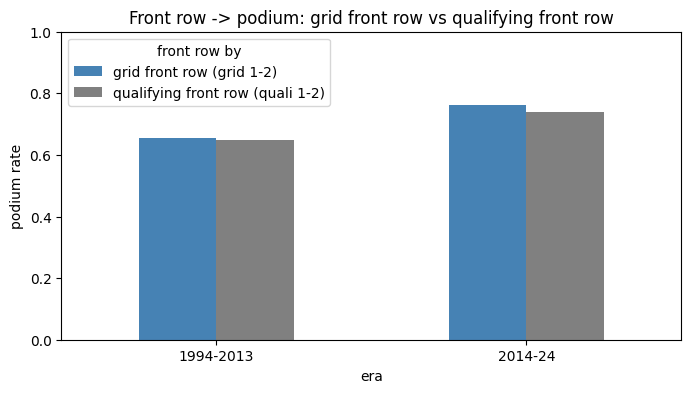

In [45]:
compare.plot(kind='bar', figsize=(8, 4), color=['steelblue', 'grey'], rot=0)
plt.title('Front row -> podium: grid front row vs qualifying front row')
plt.xlabel('era'); plt.ylabel('podium rate')
plt.ylim(0, 1)
plt.legend(title='front row by')
plt.show()

### Q1 answer
- **Most often (1994–2013):** Suzuka (75 %), Hungaroring (73 %), Bahrain and Barcelona (67 %), Shanghai, Monaco and Monza (65 %).
- **Most often (2014–24):** Monaco (90 %), Suzuka (89 %), Yas Marina (86 %), Barcelona and Spa (82 %).
- **Does the ranking change?** Yes. Conversion rose almost everywhere (13 of 15 circuits), but the order is close to
  unrelated between the eras (Spearman −0.04): Suzuka and Barcelona stay near the top, Monaco moves from joint 5th to 1st,
  Hungaroring drops from 2nd to last.
- **Grid vs qualifying:** a grid front-row start converts slightly better than a qualifying front row (65.5 % vs 64.9 %
  in 1994–2013, 76.2 % vs 74.0 % in 2014–24). The 37 front-row qualifiers who started further back (penalties,
  pit-lane starts) reached the podium only 29.7 % of the time, while the 36 drivers promoted onto the front row converted 63.9 %
  — **the grid slot, not the qualifying slot, is what counts**.

*Grain:* one row per (raceId, driverId) starter; a front-row start is grid 1–2. *Missing data:* 1,802 of 12,220
starts since 1994 have no qualifying row (mostly 1996–2002), so the grid-vs-qualifying comparison uses only races with
qualifying; the circuit ranking uses grid, which is always present. Only circuits with ≥ 10 front-row starts in both
eras are ranked, so a few races cannot dominate a rate. *Cut-off:* grid and qualifying are known before the race.

## 6. Q2 — home advantage, controlling for starting position
> *"Do drivers podium more often when racing at a circuit in their home country than elsewhere, after controlling
> for starting position (i.e., comparing drivers who started from similar grid positions, so the effect isn't just
> because home drivers happen to qualify better)?"*

Joins: `results` → `races` → `circuits` (country) and `results` → `drivers` (nationality), with the nationality →
country map from Rule 9 (`home_race`). We compare home and away starts **inside the same grid group**
(1, 2–3, 4–6, 7–10, 11+), using all seasons to have as many home starts as possible.

home starts: 1932 | away starts: 22652
raw podium rate (no control)  home: 0.116 | away: 0.138

podium rate within grid groups:
home_race    away   home  home starts  home - away
grid_group                                        
1           0.645  0.590           83       -0.054
2-3         0.511  0.537          147        0.027
4-6         0.261  0.265          226        0.005
7-10        0.093  0.072          335       -0.021
11+         0.017  0.011         1141       -0.006


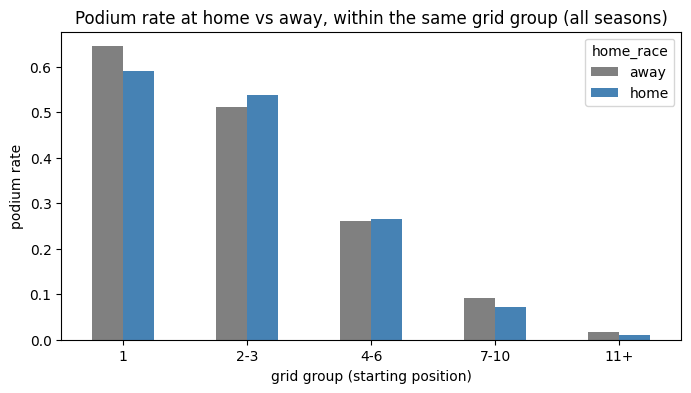

In [46]:
h2 = df.copy()
h2['grid_group'] = pd.cut(h2['grid_pos'], bins=grid_bins, labels=grid_labels)
home_rows = h2[h2['home_race'] == 1]
away_rows = h2[h2['home_race'] == 0]
print('home starts:', len(home_rows), '| away starts:', len(away_rows))
print('raw podium rate (no control)  home:', round(home_rows['podium'].mean(), 3),
      '| away:', round(away_rows['podium'].mean(), 3))

# podium rate and number of starts, per grid group, for home (1) and away (0)
rate_table = pd.pivot_table(h2, values='podium', index='grid_group', columns='home_race', aggfunc='mean', observed=False)
count_table = pd.pivot_table(h2, values='podium', index='grid_group', columns='home_race', aggfunc='count', observed=False)
q2 = rate_table.rename(columns={0: 'away', 1: 'home'})
q2['home starts'] = count_table[1]
q2['home - away'] = q2['home'] - q2['away']
print('\npodium rate within grid groups:')
print(q2.round(3))

q2[['away', 'home']].plot(kind='bar', figsize=(8, 4), color=['grey', 'steelblue'], rot=0)
plt.title('Podium rate at home vs away, within the same grid group (all seasons)')
plt.xlabel('grid group (starting position)'); plt.ylabel('podium rate')
plt.show()

**What we see:** without any control, home drivers podium *less* often (11.6 % vs 13.8 %, 1,932 home starts). Inside
each grid group the differences are small and point both ways: −5.4 points from pole, +2.7 for slots 2–3, +0.5 for 4–6,
−2.1 for 7–10 and −0.6 for 11+.

### 6.1 Logistic regression: podium ~ home + grid group
The same comparison in one number: a logistic regression with `home_race` and the grid-group dummies
(`get_dummies(drop_first=True)`, so grid group 1 is the reference). `exp(coef)` of `home_race` is the **odds ratio**:
above 1 means home drivers podium more often than away drivers who started from the same grid group.
To see how stable it is, we refit on 200 bootstrap samples (rows drawn with replacement) and report the middle 95 %.

In [47]:
def home_odds_ratio(data):
    # logistic regression: podium ~ home_race + grid-group dummies; returns the odds ratio of every input
    X = pd.get_dummies(data[['home_race', 'grid_group']], columns=['grid_group'], drop_first=True).astype(int)
    model = LogisticRegression(max_iter=1000)
    model.fit(X, data['podium'])
    return pd.Series(np.exp(model.coef_[0]), index=X.columns)

for label, data in [('all seasons', h2), ('2003-2024 only', h2[h2['year'] >= 2003])]:
    odds = home_odds_ratio(data)

    # bootstrap: refit on 200 resampled datasets to get a 95 % interval for the home odds ratio
    boot = []
    rng = np.random.RandomState(42)
    for i in range(200):
        sample_rows = rng.randint(0, len(data), len(data))
        sample = data.iloc[sample_rows]
        boot.append(home_odds_ratio(sample)['home_race'])
    low, high = np.percentile(boot, 2.5), np.percentile(boot, 97.5)
    print(f'{label}: home odds ratio = {odds["home_race"]:.3f} '
          f'(bootstrap 95 %: {low:.3f} - {high:.3f}), rows = {len(data)}')

print('\nodds ratios, all seasons (grid group 1 = reference):')
print(home_odds_ratio(h2).round(3))

all seasons: home odds ratio = 0.899 (bootstrap 95 %: 0.755 - 1.069), rows = 24584
2003-2024 only: home odds ratio = 0.818 (bootstrap 95 %: 0.591 - 1.196), rows = 8910

odds ratios, all seasons (grid group 1 = reference):
home_race          0.899
grid_group_2-3     0.612
grid_group_4-6     0.206
grid_group_7-10    0.059
grid_group_11+     0.010
dtype: float64


### Q2 answer
**No — there is no measurable home advantage once starting position is taken into account.** The home odds ratio is
0.90 over all seasons (bootstrap 95 %: 0.76–1.07) and 0.82 for 2003–2024 (0.59–1.20). Both ranges include 1, and the
point estimates are even slightly below 1. Within the grid groups, home and away rates differ by at most 5 points, with no
consistent sign. Starting position explains podiums; nationality does not add anything on top of it.

*Grain:* one row per (raceId, driverId) starter, all seasons (24,584 rows, 1,932 home starts). *Missing data:* none —
every nationality and circuit country is mapped (Rule 9); dual nationalities count as home in both countries.
*Cut-off:* nationality, circuit and grid are known before the race. This is an association, not a causal estimate.

## 7. Q3 — mechanical retirements by constructor
> *"Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?"*
> *(A mechanical retirement is a race start that ended early because a component of the car failed. It excludes
> failures caused by a crash, by the driver, or by a regulation decision.)*

Joins: `results` → `status` (why the race ended, grouped in Rule 10) → `constructors` (team name) → `races` (season).
Rate = mechanical retirements / race starts of that constructor in the period; only constructors with **at least 30
starts** in a period are ranked. A renamed team (e.g. Toro Rosso → AlphaTauri → RB) has a new `constructorId`, so
each name is counted separately — we keep `constructorId` as the unit and do not merge them by hand.

In [48]:
constructor_names = constructors[['constructorId', 'name']].rename(columns={'name': 'constructor'})
m = df[df['year'] >= 2014].merge(constructor_names, on='constructorId', how='left')
m['period'] = np.where(m['year'] <= 2021, '2014-21', '2022-24')
m['mech'] = (m['status_group'] == 'mechanical').astype(int)
m['mech_or_ambiguous'] = m['status_group'].isin(['mechanical', 'ambiguous']).astype(int)
print('starts 2014-24:', len(m), '| missing status:', int(m['status'].isnull().sum()))

# status -> group mapping, for the statuses that occur in 2014-24
mapping = m.groupby(['status_group', 'status']).size().rename('rows').reset_index()
mapping = mapping.sort_values(['status_group', 'rows'], ascending=[True, False])
print(mapping.groupby('status_group')['rows'].sum())
print('\nstatus -> group (finished / lapped rows left out):')
print(mapping[mapping['status_group'] != 'finished'].to_string(index=False))

starts 2014-24: 4598 | missing status: 0
status_group
accident       315
ambiguous       29
finished      3825
mechanical     362
other           18
retired         49
Name: rows, dtype: int64

status -> group (finished / lapped rows left out):
status_group           status  rows
    accident        Collision   150
    accident         Accident    85
    accident Collision damage    59
    accident         Spun off    11
    accident         Puncture     7
    accident           Damage     2
    accident           Debris     1
   ambiguous            Wheel    11
   ambiguous             Tyre     4
   ambiguous        Undertray     4
   ambiguous       Front wing     3
   ambiguous        Rear wing     3
   ambiguous        Wheel nut     3
   ambiguous             Seat     1
  mechanical           Engine    79
  mechanical           Brakes    48
  mechanical          Gearbox    40
  mechanical       Power Unit    39
  mechanical       Suspension    25
  mechanical       Electrical    14

2014-21: 19 constructors with >= 30 starts | overall mechanical rate 0.089
 period    constructor  starts  mech_rate  mech_or_ambiguous_rate
2014-21       Caterham      33      0.212                   0.212
2014-21       Lotus F1      75      0.173                   0.200
2014-21     Toro Rosso     242      0.161                   0.161
2014-21        Renault     199      0.131                   0.141
2014-21        McLaren     316      0.130                   0.136
2014-21       Red Bull     318      0.107                   0.107
2014-21         Sauber     199      0.106                   0.111
2014-21       Marussia      31      0.097                   0.097
2014-21     AlphaTauri      77      0.091                   0.091
2014-21   Racing Point      75      0.080                   0.080
2014-21   Haas F1 Team     241      0.075                   0.095
2014-21       Williams     319      0.072                   0.075
2014-21 Alpine F1 Team      44      0.068                   0.091
2

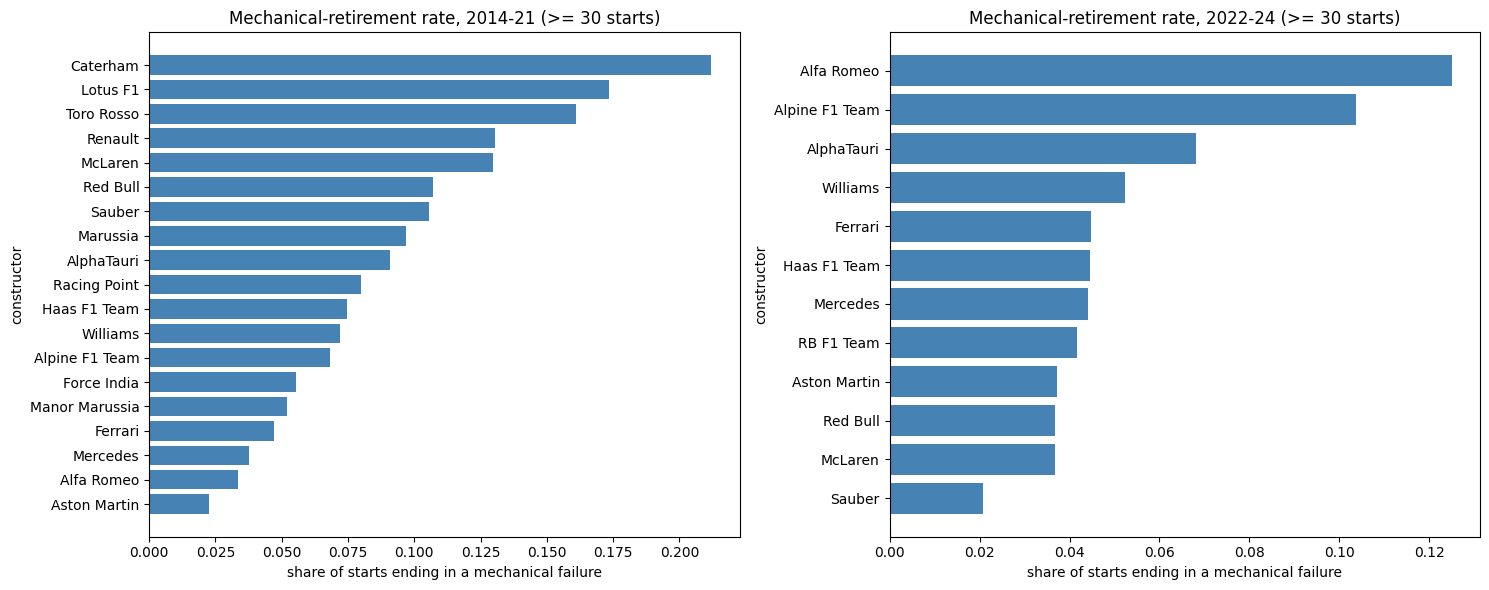

In [49]:
# one row per (period, constructor): number of starts and the two retirement rates
q3 = m.groupby(['period', 'constructor']).agg(starts=('mech', 'size'),
                                              mech_rate=('mech', 'mean'),
                                              mech_or_ambiguous_rate=('mech_or_ambiguous', 'mean')).reset_index()
q3 = q3[q3['starts'] >= 30]
for p in ['2014-21', '2022-24']:
    t = q3[q3['period'] == p].sort_values('mech_rate', ascending=False)
    overall = m.loc[m['period'] == p, 'mech'].mean()
    print(f'{p}: {len(t)} constructors with >= 30 starts | overall mechanical rate', round(overall, 3))
    print(t.round(3).to_string(index=False), '\n')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, p in zip(axes, ['2014-21', '2022-24']):
    t = q3[q3['period'] == p].sort_values('mech_rate')
    ax.barh(t['constructor'], t['mech_rate'], color='steelblue')
    ax.set_title(f'Mechanical-retirement rate, {p} (>= 30 starts)')
    ax.set_xlabel('share of starts ending in a mechanical failure'); ax.set_ylabel('constructor')
plt.tight_layout()
plt.show()

**What we see:** the overall mechanical-retirement rate fell from 8.9 % (2014–21) to 5.5 % (2022–24). In 2014–21 the
small and struggling teams lead (Caterham 21.2 %, Lotus F1 17.3 %, Toro Rosso 16.1 %), while Mercedes (3.8 %) and Aston
Martin (2.3 %) are among the most reliable. In 2022–24 Alfa Romeo (12.5 %) and Alpine (10.4 %) stand out; most teams are
around 4 %.

### 7.1 Sensitivity: count the ambiguous statuses as mechanical
Some statuses (Wheel, Tyre, Front wing, …) can be a part failure *or* the result of contact. If we also count them as
mechanical, does the ranking change?

In [50]:
for p in ['2014-21', '2022-24']:
    t = q3[q3['period'] == p].copy()
    t['rank (mechanical)'] = t['mech_rate'].rank(ascending=False, method='min').astype(int)
    t['rank (+ ambiguous)'] = t['mech_or_ambiguous_rate'].rank(ascending=False, method='min').astype(int)
    rho = t['mech_rate'].corr(t['mech_or_ambiguous_rate'], method='spearman')
    print(f'{p}: rank correlation of the two definitions (Spearman):', round(rho, 2))
    top5 = t.sort_values('rank (mechanical)').head(5)
    print(top5[['constructor', 'mech_rate', 'mech_or_ambiguous_rate',
                'rank (mechanical)', 'rank (+ ambiguous)']].round(3).to_string(index=False), '\n')

names_old = set(q3.loc[q3['period'] == '2014-21', 'constructor'])
names_new = set(q3.loc[q3['period'] == '2022-24', 'constructor'])
print('constructor names in both periods:', sorted(names_old & names_new))

2014-21: rank correlation of the two definitions (Spearman): 0.98
constructor  mech_rate  mech_or_ambiguous_rate  rank (mechanical)  rank (+ ambiguous)
   Caterham      0.212                   0.212                  1                   1
   Lotus F1      0.173                   0.200                  2                   2
 Toro Rosso      0.161                   0.161                  3                   3
    Renault      0.131                   0.141                  4                   4
    McLaren      0.130                   0.136                  5                   5 

2022-24: rank correlation of the two definitions (Spearman): 0.95
   constructor  mech_rate  mech_or_ambiguous_rate  rank (mechanical)  rank (+ ambiguous)
    Alfa Romeo      0.125                   0.125                  1                   1
Alpine F1 Team      0.104                   0.104                  2                   2
    AlphaTauri      0.068                   0.080                  3               

### Q3 answer
- **2014–2021:** Caterham (21.2 %, but only 33 starts), Lotus F1 (17.3 %), Toro Rosso (16.1 %), Renault (13.1 %) and
  McLaren (13.0 %, the Honda years) have the highest mechanical-retirement rates (overall 8.9 %, 19 constructors).
- **2022–2024:** Alfa Romeo (12.5 %), Alpine (10.4 %) and AlphaTauri (6.8 %) are highest; Sauber (2.1 %), Red Bull
  and McLaren (3.7 %) are lowest (overall 5.5 %, 12 constructors).
- **Robust to the definition:** counting the ambiguous statuses as mechanical leaves the top 5 of both periods
  unchanged (rank correlation 0.98 and 0.95).

*Grain:* one row per (raceId, driverId) starter; the rate is per constructor and period, with at least 30 starts.
*Missing data:* every start has a status. The generic status "Retired" (49 rows) gives no cause, so it is **not** counted
as mechanical; non-starters were already removed in cleaning, so a "did not start" is never a retirement.
Renamed teams (Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin, Renault → Alpine,
Sauber → Alfa Romeo → Sauber) stay separate `constructorId`s. *Cut-off:* `status` is a post-race field. It is used here
only to answer the question, never as a feature of the race being predicted.

## 8. Features
Why: every feature must be **known after qualifying and before the race starts**. We build 12 features in 6 groups:

| group | features | meaning |
|---|---|---|
| grid | `grid_pos`, `pitlane_start` | starting slot (pit lane = back of the grid) and a pit-lane flag |
| qualifying | `quali_gap_pct`, `grid_minus_quali` | % behind pole in qualifying; grid − qualifying position (penalties) |
| driver form | `drv_podium_5`, `drv_finish_5`, `drv_starts` | podium share and finish share in the driver's last 5 starts; number of earlier starts |
| constructor form | `con_podium_5`, `con_mech_10` | podium share of the team's cars in its last 5 races; mechanical-retirement share in its last 10 races |
| standings | `drv_rank_before`, `con_rank_before` | championship rank after the previous round (shifted in Rule 8) |
| context | `home_race` | driver races in their home country (Rule 9) |

**Form features use past races only:** we sort by date, group by driver (or constructor), and `shift(1)` *before*
`rolling(...)`, so the current race is never part of its own feature. Features are computed on all seasons (so a
2003 race can use 2002 history); the model then uses 2003–2024 only.

In [51]:
feat = df.sort_values(['date', 'raceId', 'grid_pos']).reset_index(drop=True)

# qualifying features: gap to pole (best of Q1/Q2/Q3, from 4.4) and grid - qualifying position
gap = q[['raceId', 'driverId', 'gap_pct']].rename(columns={'gap_pct': 'quali_gap_pct'})
quali_pos = qualifying[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'})
feat = feat.merge(gap, on=['raceId', 'driverId'], how='left')
feat = feat.merge(quali_pos, on=['raceId', 'driverId'], how='left')
feat['grid_minus_quali'] = feat['grid_pos'] - feat['quali_pos']

def mean_of_previous(s, n):
    # average of the last n races BEFORE the current one: shift(1) removes the current race
    return s.shift(1).rolling(n, min_periods=1).mean()

# driver form (the rows are sorted by date, so each driver's rows are in race order)
feat['finished'] = (feat['status_group'] == 'finished').astype(int)
g = feat.groupby('driverId')
feat['drv_podium_5'] = g['podium'].transform(lambda s: mean_of_previous(s, 5))
feat['drv_finish_5'] = g['finished'].transform(lambda s: mean_of_previous(s, 5))
feat['drv_starts'] = g.cumcount()          # number of earlier starts

# constructor form: first one row per (constructor, race), then the same "previous races" average
feat['mechanical'] = (feat['status_group'] == 'mechanical').astype(int)
con = feat.groupby(['constructorId', 'raceId', 'date']).agg(podium_share=('podium', 'mean'),
                                                            mech_share=('mechanical', 'mean')).reset_index()
con = con.sort_values(['constructorId', 'date'])
gc = con.groupby('constructorId')
con['con_podium_5'] = gc['podium_share'].transform(lambda s: mean_of_previous(s, 5))
con['con_mech_10'] = gc['mech_share'].transform(lambda s: mean_of_previous(s, 10))
feat = feat.merge(con[['constructorId', 'raceId', 'con_podium_5', 'con_mech_10']], on=['constructorId', 'raceId'], how='left')

# candidate features we will test and drop (evidence below)
feat = feat.merge(drivers[['driverId', 'dob']], on='driverId', how='left')
feat['age'] = (feat['date'] - feat['dob']).dt.days / 365.25

features = ['grid_pos', 'pitlane_start', 'quali_gap_pct', 'grid_minus_quali', 'drv_podium_5', 'drv_finish_5',
            'drv_starts', 'con_podium_5', 'con_mech_10', 'drv_rank_before', 'con_rank_before', 'home_race']
dropped = ['quali_pos', 'drv_pts_before', 'age', 'field']
print('rows:', len(feat), '| duplicates (raceId, driverId):', int(feat.duplicated(['raceId', 'driverId']).sum()))
print('missing values, 2003-2024 rows:')
print(feat.loc[feat['year'] >= 2003, features].isnull().sum())

rows: 24584 | duplicates (raceId, driverId): 0
missing values, 2003-2024 rows:
grid_pos              0
pitlane_start         0
quali_gap_pct       144
grid_minus_quali     21
drv_podium_5         89
drv_finish_5         89
drv_starts            0
con_podium_5         41
con_mech_10          41
drv_rank_before     594
con_rank_before     484
home_race             0
dtype: int64


### 8.1 Evidence: correlations (Lab 1 task 4)
We measure the correlation of every candidate feature with `podium` and with each other, on the **training seasons
only (2003–2019)**, so validation and test data do not influence the feature choice.

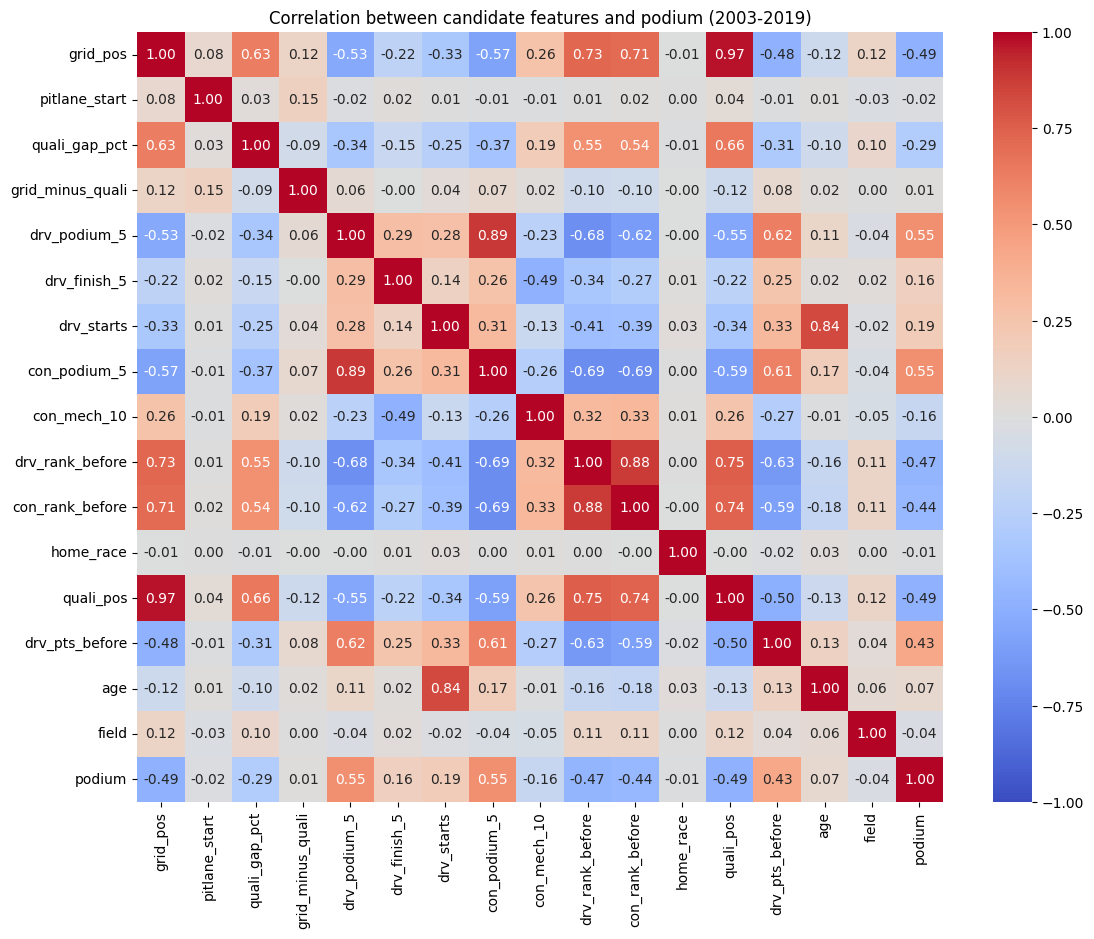

                  pearson  spearman
drv_podium_5         0.55      0.53
con_podium_5         0.55      0.51
quali_pos           -0.49     -0.50
grid_pos            -0.49     -0.49
drv_rank_before     -0.47     -0.48
con_rank_before     -0.44     -0.45
drv_pts_before       0.43      0.37
quali_gap_pct       -0.29     -0.48
drv_starts           0.19      0.23
con_mech_10         -0.16     -0.18
drv_finish_5         0.16      0.16
age                  0.07      0.09
field               -0.04     -0.03
pitlane_start       -0.02     -0.02
home_race           -0.01     -0.01
grid_minus_quali     0.01      0.09


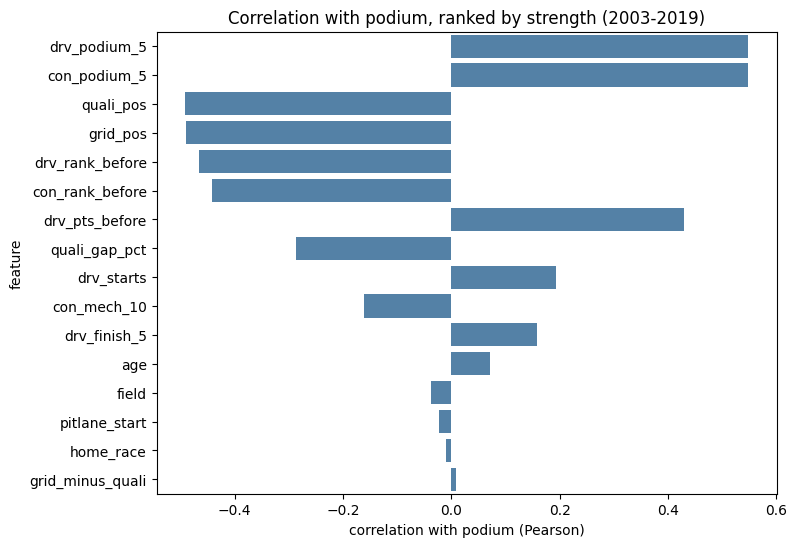


why the dropped features are dropped:
quali_pos vs grid_pos:            0.97
drv_pts_before vs drv_rank_before: -0.63 | Spearman: -0.86
age vs drv_starts:                 0.84 | age vs podium: 0.07
field vs podium:                   -0.04 | field min/max: 6 / 24


In [52]:
train_seasons = feat[feat['year'].between(2003, 2019)]
corr = train_seasons[features + dropped + ['podium']].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between candidate features and podium (2003-2019)')
plt.show()

ranking = corr['podium'].drop('podium').sort_values(key=abs, ascending=False)
# Spearman (rank) correlation as a check: it is not pulled down by a few extreme values
spearman = train_seasons[features + dropped + ['podium']].corr(method='spearman')['podium'].drop('podium')
print(pd.DataFrame({'pearson': ranking, 'spearman': spearman[ranking.index]}).round(2))
plt.figure(figsize=(8, 6))
sns.barplot(x=ranking.values, y=ranking.index, color='steelblue')
plt.title('Correlation with podium, ranked by strength (2003-2019)')
plt.xlabel('correlation with podium (Pearson)'); plt.ylabel('feature')
plt.show()

print('\nwhy the dropped features are dropped:')
print('quali_pos vs grid_pos:           ', round(corr.loc['quali_pos', 'grid_pos'], 2))
print('drv_pts_before vs drv_rank_before:', round(corr.loc['drv_pts_before', 'drv_rank_before'], 2),
      '| Spearman:', round(train_seasons['drv_pts_before'].corr(train_seasons['drv_rank_before'], method='spearman'), 2))
print('age vs drv_starts:                ', round(corr.loc['age', 'drv_starts'], 2), '| age vs podium:', round(corr.loc['age', 'podium'], 2))
print('field vs podium:                  ', round(corr.loc['field', 'podium'], 2), '| field min/max:',
      train_seasons['field'].min(), '/', train_seasons['field'].max())

**What we see:** form and grid carry the signal: `drv_podium_5` and `con_podium_5` (+0.55 each), `grid_pos` (−0.49),
`drv_rank_before` (−0.47) and `con_rank_before` (−0.44). `quali_gap_pct` looks weak with Pearson (−0.29) but is strong
with Spearman (−0.48): a few huge gaps (wet sessions, up to 45 %) flatten the linear correlation. `drv_starts` (+0.19),
`drv_finish_5` (+0.16) and `con_mech_10` (−0.16) are weaker; `home_race`, `pitlane_start` and `grid_minus_quali` are ≈ 0
linearly. Some kept pairs overlap strongly (driver vs team podium share 0.89, driver vs team rank 0.88); the ablation
will show whether both are needed.

### 8.2 Evidence: podium rate by feature value
For each feature we split its values into bins (or use the value itself when it has only a few) and plot the podium
rate per bin, on the training seasons.

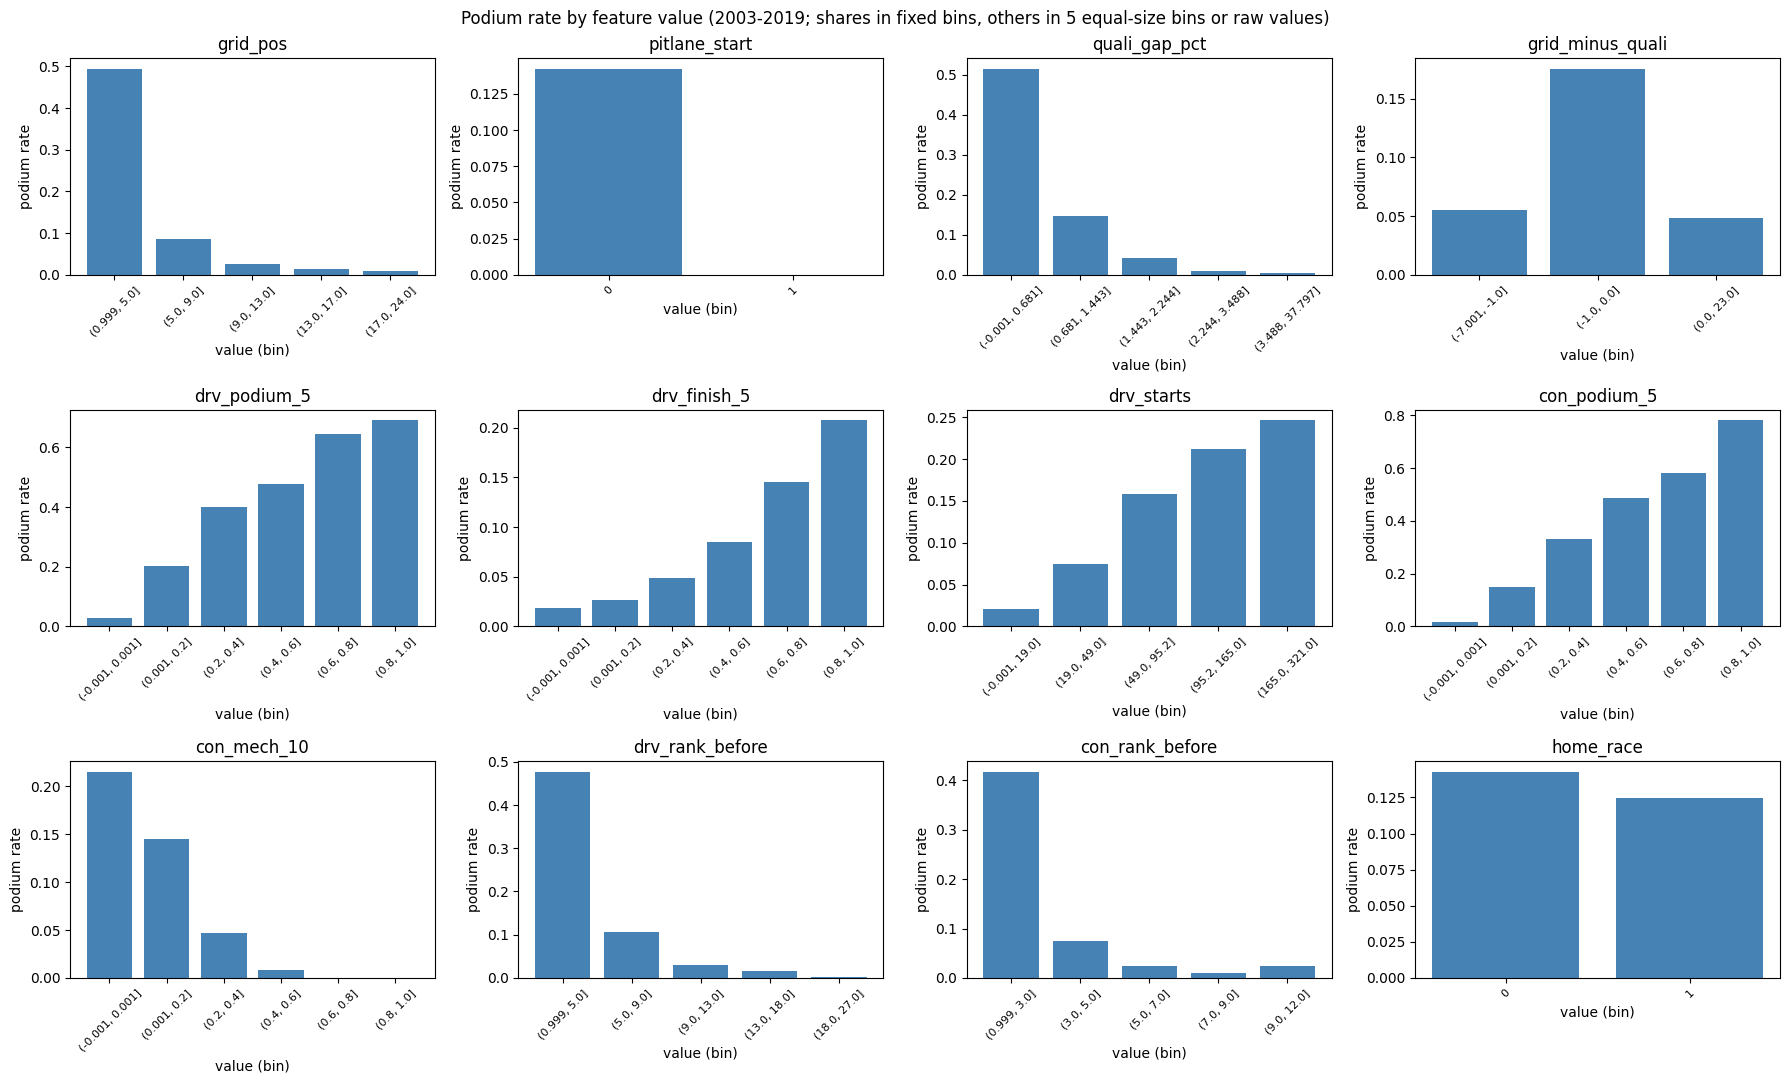

In [53]:
share_bins = [-0.001, 0.001, 0.2, 0.4, 0.6, 0.8, 1.0]      # for the 0-1 share features: 0, (0-0.2], ... (0.8-1]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.flatten(), features):
    x = train_seasons[col]
    if x.nunique() <= 6:
        bins = x
    elif col in ['drv_podium_5', 'drv_finish_5', 'con_podium_5', 'con_mech_10']:
        bins = pd.cut(x, share_bins)
    else:
        bins = pd.qcut(x, 5, duplicates='drop')
    rate_by_bin = train_seasons.groupby(bins, observed=True)['podium'].mean()
    ax.bar([str(b) for b in rate_by_bin.index], rate_by_bin.values, color='steelblue')
    ax.set_title(col)
    ax.set_xlabel('value (bin)'); ax.set_ylabel('podium rate')
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)
plt.suptitle('Podium rate by feature value (2003-2019; shares in fixed bins, others in 5 equal-size bins or raw values)')
plt.tight_layout()
plt.show()

**What we see:** the bins show clear, mostly monotonic effects: a driver with no podium in the last 5 starts reaches
the podium about 3 % of the time, one with 5 out of 5 about 70 %; the team podium share shows the same (≈ 2 % → ≈ 80 %).
Front grid slots, small qualifying gaps and top championship ranks convert far more often. `grid_minus_quali` is close to
zero linearly but not useless: drivers who start where they qualified (0) reach the podium ≈ 18 % of the time, drivers
moved back by penalties only ≈ 5 %. `con_mech_10` falls from ≈ 21 % (no recent failures) to ≈ 5 % (20–40 % failures).
`home_race` shows no advantage (Q2), but we keep it for the ablation.

**Dropped features:** `quali_pos` duplicates `grid_pos` (correlation 0.97). `drv_pts_before` says the same as
`drv_rank_before` (Spearman −0.86; Pearson only −0.63 because points grow during a season while ranks do not).
`age` mostly repeats experience (`drv_starts`, 0.84) and is barely related to the podium (0.07). `field` (number of starters,
6–24, almost always ~20) has no relation to the podium (−0.04).

## 9. Leakage check
Why: a form feature that included the current race would "know" the answer. We follow one driver (Lewis Hamilton)
over 8 consecutive races and recompute `drv_podium_5` by hand from the **5 previous** results only, and show that
`drv_rank_before` equals the championship rank stored **after the previous round**.

In [54]:
ham_id = drivers.loc[(drivers['forename'] == 'Lewis') & (drivers['surname'] == 'Hamilton'), 'driverId'].iloc[0]
ham = feat[feat['driverId'] == ham_id].reset_index(drop=True)

# recompute by hand: mean podium of the (up to) 5 starts BEFORE this one
by_hand = []
for k in range(len(ham)):
    if k == 0:
        by_hand.append(np.nan)                              # first start: no earlier races
    else:
        earlier = ham['podium'].iloc[max(0, k - 5):k]      # the up-to-5 starts before start k
        by_hand.append(earlier.mean())
ham['podium_prev5_by_hand'] = by_hand

# championship rank stored for this race (= after this race) -> the next round should use it
after = driver_standings[driver_standings['driverId'] == ham_id][['raceId', 'position']]
after = after.rename(columns={'position': 'rank_after_this_race'})
ham = ham.merge(after, on='raceId', how='left')

show = ham[(ham['year'] == 2016) & (ham['round'] <= 8)]
print(show[['year', 'round', 'name', 'positionOrder', 'podium', 'drv_podium_5', 'podium_prev5_by_hand',
            'rank_after_this_race', 'drv_rank_before']].to_string(index=False))

same_values = np.allclose(ham['drv_podium_5'], ham['podium_prev5_by_hand'], equal_nan=True)
print('\nall', len(ham), 'Hamilton starts: drv_podium_5 equals the by-hand value:', bool(same_values))

# the rank must come from the previous ROUND; compare only where his previous start was the previous round
prev_year = ham['year'].shift(1)
prev_round = ham['round'].shift(1)
same_season = ham['year'] == prev_year
consecutive = same_season & (ham['round'] == prev_round + 1)
prev_rank_after = ham['rank_after_this_race'].shift(1)
match = ham.loc[consecutive, 'drv_rank_before'] == prev_rank_after[consecutive]
print('starts right after his previous round:', int(consecutive.sum()),
      '| drv_rank_before = rank after the previous round:', int(match.sum()), 'of', len(match))
print('starts after a missed round (e.g. 2020 Sakhir GP), where the rank comes from the round he missed:',
      int((same_season & ~consecutive).sum()))

odd_rows = match.index[~match]
print('\nrows that do not match:')
odd = ham.loc[odd_rows, ['year', 'round', 'name', 'drv_rank_before']].copy()
odd['rank_after_previous_race'] = prev_rank_after[odd_rows]
print(odd)

 year  round                  name  positionOrder  podium  drv_podium_5  podium_prev5_by_hand  rank_after_this_race  drv_rank_before
 2016      1 Australian Grand Prix              2       1           1.0                   1.0                   2.0              NaN
 2016      2    Bahrain Grand Prix              3       1           1.0                   1.0                   2.0              2.0
 2016      3    Chinese Grand Prix              7       0           1.0                   1.0                   2.0              2.0
 2016      4    Russian Grand Prix              2       1           0.8                   0.8                   2.0              2.0
 2016      5    Spanish Grand Prix             21       0           0.8                   0.8                   3.0              2.0
 2016      6     Monaco Grand Prix              1       1           0.6                   0.6                   2.0              3.0
 2016      7   Canadian Grand Prix              1       1           0

**What we see:** in the 8 races, `drv_podium_5` always equals the by-hand mean of the 5 earlier results (e.g. round 5
uses rounds 1–4 of 2016 plus the 2015 finale, not round 5 itself), and `drv_rank_before` equals the rank stored after the
previous round (round 6 uses rank 3 from round 5). Over all 356 Hamilton starts the form value matches the by-hand
value, and the rank matches in 336 of 337 cases. The one exception is 2009 round 2: he was disqualified at the 2009 opener,
so no rank exists on either side (both missing). One start follows a missed round (2020 Sakhir GP); there the rank
correctly comes from the round he missed.

## 10. Split by season
Why: we predict *future* races from *past* races, so the split follows time: **train 2003–2019** (complete qualifying
data), **validation 2020–21** (to choose hyperparameters and the threshold) and **test 2022–24** (touched once, at the end).
A random split (as in the labs' `train_test_split`) would leak in two ways: races from the same weekend would sit in
train and test at the same time (a team-mate's result tells a lot about the other car), and the model would learn from
2023 to predict 2021, which is never possible in real use.

In [55]:
model_df = feat[feat['year'] >= 2003].reset_index(drop=True)
train = model_df[model_df['year'] <= 2019]
val = model_df[model_df['year'].between(2020, 2021)]
test = model_df[model_df['year'] >= 2022]

split_table = pd.DataFrame({
    'seasons': ['2003-2019', '2020-2021', '2022-2024'],
    'rows': [len(train), len(val), len(test)],
    'races': [train['raceId'].nunique(), val['raceId'].nunique(), test['raceId'].nunique()],
    'podium rate': [train['podium'].mean(), val['podium'].mean(), test['podium'].mean()]},
    index=['train', 'validation', 'test']).round(3)
print(split_table)
print('\ntotal rows:', len(model_df), '| overlap of races between splits:',
      len(set(train['raceId']) & set(val['raceId'])) + len(set(val['raceId']) & set(test['raceId'])))

X_train_raw, y_train = train[features], train['podium']
X_val_raw, y_val = val[features], val['podium']
X_test_raw, y_test = test[features], test['podium']

              seasons  rows  races  podium rate
train       2003-2019  6783    321        0.142
validation  2020-2021   775     39        0.151
test        2022-2024  1352     68        0.151

total rows: 8910 | overlap of races between splits: 0


**What we see:** train has 6,783 rows (321 races), validation 775 (39 races) and test 1,352 (68 races), exactly as
planned. No race appears in two splits. The podium rate is similar everywhere (14.2 % / 15.1 % / 15.1 %), so the
classes are balanced alike across splits, and about 1 in 7 rows is a podium. We will use class weights for that.

## 11. Preprocessing
Why: a few features are missing (e.g. the rank before round 1, no qualifying time). As in Lab 1 we fill numbers with
the **median**, which is robust to outliers, and as in Labs 2–3 we standardise with `StandardScaler`. Both are
**fitted on the training split only** and then applied to validation and test, so no information from later seasons
leaks into the preprocessing. The tree model does not need scaling, but the logistic regression and the neural network do.

First we **clip `quali_gap_pct` at the training 99th percentile**: a few wet or disrupted sessions produce gaps of up
to 45 %, which flatten its linear relation with the podium (Pearson −0.29 vs Spearman −0.48) and would dominate the
scaled values for the logistic regression and the neural network.

In [56]:
# clip the qualifying gap at the train 99th percentile (wet-session outliers)
gap_cap = X_train_raw['quali_gap_pct'].quantile(0.99)
print(f'quali_gap_pct clipped at {gap_cap:.2f} % (train 99th percentile)')
for split_name, x in [('train', X_train_raw), ('val', X_val_raw), ('test', X_test_raw)]:
    clipped = int((x['quali_gap_pct'] > gap_cap).sum())
    print(f'  {split_name}: max before {x["quali_gap_pct"].max():.2f} % | rows clipped: {clipped} of {len(x)}')
X_train_raw = X_train_raw.copy()
X_val_raw = X_val_raw.copy()
X_test_raw = X_test_raw.copy()
X_train_raw['quali_gap_pct'] = X_train_raw['quali_gap_pct'].clip(upper=gap_cap)
X_val_raw['quali_gap_pct'] = X_val_raw['quali_gap_pct'].clip(upper=gap_cap)
X_test_raw['quali_gap_pct'] = X_test_raw['quali_gap_pct'].clip(upper=gap_cap)
print(f'  after clipping: max train {X_train_raw["quali_gap_pct"].max():.2f} %, '
      f'median train {X_train_raw["quali_gap_pct"].median():.2f} % (median unchanged)')

print('\nmissing values before filling (train / val / test):')
missing_table = pd.DataFrame({'train': X_train_raw.isnull().sum(), 'val': X_val_raw.isnull().sum(),
                              'test': X_test_raw.isnull().sum()})
print(missing_table[missing_table.sum(axis=1) > 0])

train_medians = X_train_raw.median()
X_train_filled = X_train_raw.fillna(train_medians)
X_val_filled = X_val_raw.fillna(train_medians)
X_test_filled = X_test_raw.fillna(train_medians)
print('\ntrain medians used:\n', train_medians.round(3))

scaler = StandardScaler()
scaler.fit(X_train_filled)
X_train = pd.DataFrame(scaler.transform(X_train_filled), columns=features, index=X_train_filled.index)
X_val = pd.DataFrame(scaler.transform(X_val_filled), columns=features, index=X_val_filled.index)
X_test = pd.DataFrame(scaler.transform(X_test_filled), columns=features, index=X_test_filled.index)

print('\nafter scaling - mean / std per split (train should be 0 / 1):')
print(pd.DataFrame({'train mean': X_train.mean(), 'train std': X_train.std(),
                    'val mean': X_val.mean(), 'test mean': X_test.mean()}).round(2))
missing_left = X_train.isnull().sum().sum() + X_val.isnull().sum().sum() + X_test.isnull().sum().sum()
print('missing left:', int(missing_left))

quali_gap_pct clipped at 12.46 % (train 99th percentile)
  train: max before 37.80 % | rows clipped: 67 of 6783
  val: max before 31.41 % | rows clipped: 5 of 775
  test: max before 45.60 % | rows clipped: 25 of 1352
  after clipping: max train 12.46 %, median train 1.81 % (median unchanged)

missing values before filling (train / val / test):
                  train  val  test
quali_gap_pct       122    9    13
grid_minus_quali     20    1     0
drv_podium_5         75    6     8
drv_finish_5         75    6     8
con_podium_5         35    4     2
con_mech_10          35    4     2
drv_rank_before     483   43    68
con_rank_before     384   40    60

train medians used:
 grid_pos            11.000
pitlane_start        0.000
quali_gap_pct        1.806
grid_minus_quali     0.000
drv_podium_5         0.000
drv_finish_5         0.800
drv_starts          70.000
con_podium_5         0.000
con_mech_10          0.100
drv_rank_before     11.000
con_rank_before      6.000
home_race           

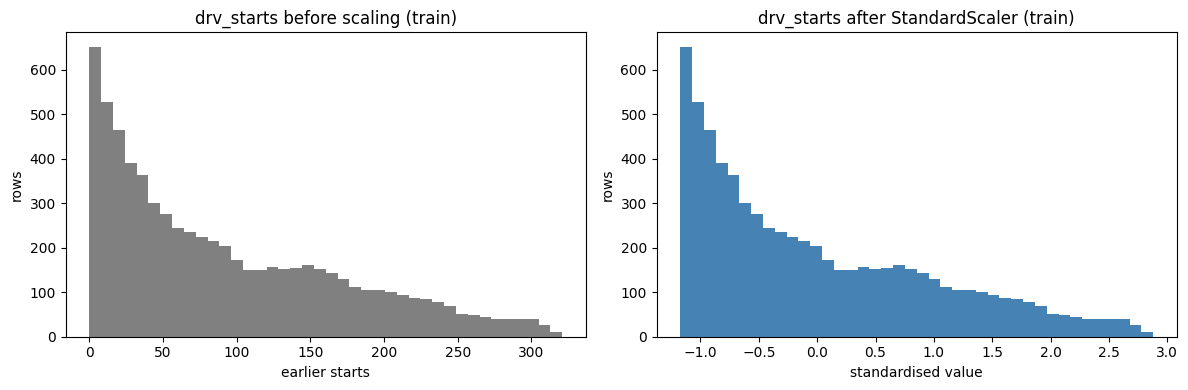

drv_starts: before  min 0, max 321, mean 92.9 | after  min -1.17, max 2.88, mean -0.00


In [57]:
col = 'drv_starts'
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_train_filled[col], bins=40, color='grey')
axes[0].set_title(f'{col} before scaling (train)')
axes[0].set_xlabel('earlier starts')
axes[0].set_ylabel('rows')
axes[1].hist(X_train[col], bins=40, color='steelblue')
axes[1].set_title(f'{col} after StandardScaler (train)')
axes[1].set_xlabel('standardised value')
axes[1].set_ylabel('rows')
plt.tight_layout()
plt.show()

before, after = X_train_filled[col], X_train[col]
print(f'{col}: before  min {before.min():.0f}, max {before.max():.0f}, mean {before.mean():.1f}'
      f' | after  min {after.min():.2f}, max {after.max():.2f}, mean {after.mean():.2f}')

**What we see:** scaling changes only the **range**, not the shape: `drv_starts` goes from 0–321 (mean 92.9) to
−1.17–2.88 (mean 0), and the histogram looks identical. Missing values were few (at most 7 % of rows, mostly the rank
before round 1) and none are left. On validation and test the scaled means are not exactly 0, which shows real drift.
Recent grids are more experienced (`drv_starts` +0.35 / +0.67 standard deviations) and more reliable (`con_mech_10`
−0.43 / −0.56). This is expected with a time-based split, and we keep it in mind when reading test scores.

`X_train`, `X_val`, `X_test` (filled + scaled), `X_*_filled` (filled, not scaled, for the Random Forest) and
`y_train`, `y_val`, `y_test` are ready for the models.

## 12. Model 1 — Logistic Regression (baseline)
**How it works:** it gives each (scaled) feature a weight, adds them up and turns the sum into a probability with the
sigmoid function. A positive weight raises the podium chance, a negative one lowers it. `class_weight='balanced'` makes a
missed podium count about 6× more than a false alarm, because only ~1 in 7 rows is a podium.
**Limits:** it can only draw a straight boundary (each feature adds a fixed amount), so it cannot learn interactions
like "pole matters more for a strong team", and correlated features share their weights in an unstable way.
It is our baseline: a more complex model must beat it to be worth it.

In [58]:
lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_train, y_train)

print('weights (scaled features), sorted:')
print(pd.Series(lr.coef_[0], index=features).sort_values().round(3))
p_val = lr.predict_proba(X_val)[:, 1]
print('\nvalidation  ROC-AUC:', round(roc_auc_score(y_val, p_val), 3), '| PR-AUC:', round(average_precision_score(y_val, p_val), 3))

weights (scaled features), sorted:
grid_pos           -1.411
drv_rank_before    -0.434
con_rank_before    -0.252
pitlane_start      -0.235
quali_gap_pct      -0.223
drv_finish_5       -0.127
home_race          -0.077
con_mech_10        -0.062
drv_starts          0.013
grid_minus_quali    0.177
con_podium_5        0.195
drv_podium_5        0.441
dtype: float64

validation  ROC-AUC: 0.924 | PR-AUC: 0.696


**What we see:** the logistic regression leans mostly on the grid (weight −1.41 per standard deviation of grid position), then on the driver's recent podiums (+0.44) and championship rank (−0.43). `grid_minus_quali` is positive (+0.18): for the same grid slot, a driver moved back by a penalty is *more* likely to reach the podium, because the car is faster than its slot suggests. Some weights have an unexpected sign (e.g. `drv_finish_5` −0.13) because correlated features share credit, which is the limit mentioned above. Validation: ROC-AUC 0.924, PR-AUC 0.696.

## 13. Model 2 — Random Forest
**How it works (Lab 4):** many decision trees, each trained on a random sample of rows and features; each tree asks
yes/no questions ("grid ≤ 3?", "team podium share > 0.4?") and the forest averages their votes. It can learn non-linear
effects and interactions, and it does not need scaled data, so it uses the filled but unscaled features.
**Limits:** deep trees can memorise the training seasons (overfitting), it is harder to explain than a weight per
feature, and its probabilities are less smooth. We first train the default forest (100 trees, as in Lab 4), then tune
two settings that control overfitting on the **validation** seasons, using PR-AUC.

In [59]:
# attempt 1: the default forest (100 trees, as in Lab 4)
rf_default = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_default.fit(X_train_filled, y_train)
train_score = average_precision_score(y_train, rf_default.predict_proba(X_train_filled)[:, 1])
val_score = average_precision_score(y_val, rf_default.predict_proba(X_val_filled)[:, 1])
print('default forest  train PR-AUC:', round(train_score, 3), '| validation PR-AUC:', round(val_score, 3))

default forest  train PR-AUC: 1.0 | validation PR-AUC: 0.665


### 13.1 Tuning the forest on the validation seasons
Why: the default forest has a large gap between train and validation. We try 12 settings of the two parameters that
control overfitting (`max_depth`, `min_samples_leaf`) and keep the one with the best **validation** PR-AUC.

In [60]:
# attempt 2: small grid, scored on the validation seasons
tried = []
best_score = -1
rf_tuned = None
for depth in [None, 5, 10, 15]:
    for leaf in [1, 5, 20]:
        rf = RandomForestClassifier(n_estimators=100, max_depth=depth, min_samples_leaf=leaf,
                                    random_state=42, class_weight='balanced')
        rf.fit(X_train_filled, y_train)
        score_train = average_precision_score(y_train, rf.predict_proba(X_train_filled)[:, 1])
        score_val = average_precision_score(y_val, rf.predict_proba(X_val_filled)[:, 1])
        tried.append({'max_depth': str(depth), 'min_samples_leaf': leaf,
                      'train PR-AUC': round(score_train, 3), 'validation PR-AUC': round(score_val, 3)})
        if score_val > best_score:          # keep the best forest so far
            best_score = score_val
            rf_tuned = rf
            best_params = (depth, leaf)

tried = pd.DataFrame(tried).sort_values('validation PR-AUC', ascending=False)
print(tried.to_string(index=False))
print('\nbest settings: max_depth =', best_params[0], '| min_samples_leaf =', best_params[1],
      '| validation PR-AUC =', round(best_score, 3))

max_depth  min_samples_leaf  train PR-AUC  validation PR-AUC
       10                20         0.755              0.719
       15                20         0.756              0.716
     None                20         0.756              0.715
        5                20         0.714              0.715
        5                 5         0.723              0.709
       15                 5         0.867              0.707
     None                 5         0.871              0.702
        5                 1         0.722              0.699
       10                 5         0.826              0.694
     None                 1         1.000              0.665
       10                 1         0.875              0.660
       15                 1         0.991              0.652

best settings: max_depth = 10 | min_samples_leaf = 20 | validation PR-AUC = 0.719


**What we see:** the default forest memorises the training seasons (train PR-AUC 1.000) and drops to 0.665 on validation. Requiring at least 20 rows per leaf helps most: every leaf-20 setting scores 0.715–0.719 on validation, every leaf-1 setting only 0.652–0.699. The best setting is `max_depth = 10, min_samples_leaf = 20` (validation PR-AUC 0.719, train 0.755), so the train–validation gap shrinks from 0.335 to 0.036.

## 14. Model 3 — Keras neural network (Lab 3)
**How it works:** a feed-forward network: each hidden layer computes many weighted sums of the previous layer and passes
them through ReLU, so it can learn curved boundaries and interactions; the last neuron uses a sigmoid to output a podium
probability, trained with `binary_crossentropy` and Adam. We train two versions: **NN-Lab** (64→32→16, the exact Lab 3
layers) and **NN-Shallow** (64→32, the brief asks for 1–2 hidden layers). Training stops when the validation loss
(2020–21) has not improved for 15 epochs, and the best weights are restored. Class weights handle the 1-in-7 imbalance.
**Limits:** more settings to choose, results vary slightly with the random seed, and it is the hardest model to explain.

In [61]:
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weight = {0: float(weights[0]), 1: float(weights[1])}
print('class weights from train:', {0: round(class_weight[0], 2), 1: round(class_weight[1], 2)})

def build_nn(hidden):
    tf.keras.utils.set_random_seed(42)          # same start for every run
    model = keras.Sequential()
    model.add(keras.Input(shape=(len(features),)))
    for n in hidden:                            # one Dense ReLU layer per number in "hidden"
        model.add(keras.layers.Dense(n, activation='relu'))
    model.add(keras.layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

nets = {}
histories = {}

def train_nn(name, hidden):
    model = build_nn(hidden)
    model.summary()                             # layers, output shapes and number of weights
    early = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    # verbose=1 (as in Lab 3): a progress bar for every epoch with loss, accuracy, val_loss and val_accuracy
    history = model.fit(X_train.values, y_train.values, validation_data=(X_val.values, y_val.values),
                        epochs=200, batch_size=32, class_weight=class_weight, callbacks=[early], verbose=1)
    nets[name] = model
    histories[name] = history.history

    epochs_run = len(history.history['loss'])
    best_epoch = int(np.argmin(history.history['val_loss'])) + 1
    best_val_loss = min(history.history['val_loss'])
    print(f'{name}: {model.count_params()} weights | stopped after {epochs_run} epochs, '
          f'best epoch {best_epoch} | best val_loss {best_val_loss:.4f}')

class weights from train: {0: 0.58, 1: 3.52}


**Attempt 3 — NN-Lab (64→32→16), the exact Lab 3 layers (reference):**

In [62]:
train_nn('NN-Lab (64-32-16)', [64, 32, 16])

2026-10-19 19:41:17.737378: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200


2026-10-19 19:41:18.040880: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8066 - loss: 0.3951 - val_accuracy: 0.8387 - val_loss: 0.3738
Epoch 2/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8271 - loss: 0.3377 - val_accuracy: 0.8323 - val_loss: 0.3604
Epoch 3/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8325 - loss: 0.3288 - val_accuracy: 0.8439 - val_loss: 0.3511
Epoch 4/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8359 - loss: 0.3239 - val_accuracy: 0.8439 - val_loss: 0.3536
Epoch 5/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8392 - loss: 0.3199 - val_accuracy: 0.8439 - val_loss: 0.3505
Epoch 6/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8408 - loss: 0.3169 - val_accuracy: 0.8439 - val_loss: 0.3442
Epoch 7/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8431 - loss: 0.3144 - val_accuracy: 0.8477 - val_loss: 0.3394
Epoch 8/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8440 - loss: 0.3122 - val_accuracy: 0.8490

**Attempt 4 — NN-Shallow (64→32), the submitted network (the brief asks for 1–2 hidden layers):**

In [63]:
train_nn('NN-Shallow (64-32)', [64, 32])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200


2026-10-19 19:41:53.577364: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8142 - loss: 0.3960 - val_accuracy: 0.8310 - val_loss: 0.3722
Epoch 2/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8240 - loss: 0.3420 - val_accuracy: 0.8348 - val_loss: 0.3598
Epoch 3/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8282 - loss: 0.3325 - val_accuracy: 0.8361 - val_loss: 0.3536
Epoch 4/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8327 - loss: 0.3267 - val_accuracy: 0.8374 - val_loss: 0.3489
Epoch 5/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8353 - loss: 0.3229 - val_accuracy: 0.8400 - val_loss: 0.3454
Epoch 6/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8387 - loss: 0.3201 - val_accuracy: 0.8413 - val_loss: 0.3435
Epoch 7/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8412 - loss: 0.3177 - val_accuracy: 0.8426 - val_loss: 0.3415
Epoch 8/200
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8431 - loss: 0.3156 - val_accuracy: 0.8477

### 14.1 Training details per epoch
The training output above shows every epoch (Keras progress bar, `verbose=1` as in Lab 3). Below, the same history as a table for each network, plus a one-row summary:
how many epochs ran, which epoch early stopping kept (lowest validation loss), and the loss and accuracy at that epoch.

In [64]:
summary_rows = []
for name, h in histories.items():
    epochs = pd.DataFrame({'epoch': range(1, len(h['loss']) + 1),
                           'train loss': h['loss'], 'val loss': h['val_loss'],
                           'train accuracy': h['accuracy'], 'val accuracy': h['val_accuracy']})
    best = epochs.loc[epochs['val loss'].idxmin()]
    epochs['kept'] = np.where(epochs['epoch'] == best['epoch'], '<- best (restored)', '')
    print(f'--- {name}: every epoch ---')
    print(epochs.round(4).to_string(index=False), '\n')

    summary_rows.append({'model': name, 'hidden layers': name.split('(')[1].rstrip(')'),
                         'weights': nets[name].count_params(), 'epochs run': len(epochs),
                         'best epoch': int(best['epoch']),
                         'train loss': best['train loss'], 'val loss': best['val loss'],
                         'train accuracy': best['train accuracy'], 'val accuracy': best['val accuracy']})

nn_summary = pd.DataFrame(summary_rows)
print('summary at the restored (best) epoch:')
print(nn_summary.round(4).to_string(index=False))

--- NN-Lab (64-32-16): every epoch ---
 epoch  train loss  val loss  train accuracy  val accuracy               kept
     1      0.3951    0.3738          0.8066        0.8387                   
     2      0.3377    0.3604          0.8271        0.8323                   
     3      0.3288    0.3511          0.8325        0.8439                   
     4      0.3239    0.3536          0.8359        0.8439                   
     5      0.3199    0.3505          0.8392        0.8439                   
     6      0.3169    0.3442          0.8408        0.8439                   
     7      0.3144    0.3394          0.8431        0.8477                   
     8      0.3122    0.3372          0.8440        0.8490                   
     9      0.3101    0.3422          0.8468        0.8477                   
    10      0.3081    0.3419          0.8483        0.8477                   
    11      0.3062    0.3355          0.8498        0.8516                   
    12      0.3040    0.3

**What we see:** NN-Lab ran 46 epochs and early stopping restored epoch 31 (train loss 0.272, val loss 0.303,
train accuracy 0.869, val accuracy 0.893). NN-Shallow ran 42 epochs and kept epoch 27 (train loss 0.289, val loss 0.326,
accuracy 0.864 / 0.865). In both, the training loss keeps falling after the best epoch while the validation loss stops
improving, which is the start of overfitting; the 15 extra epochs are the patience window before training stops.

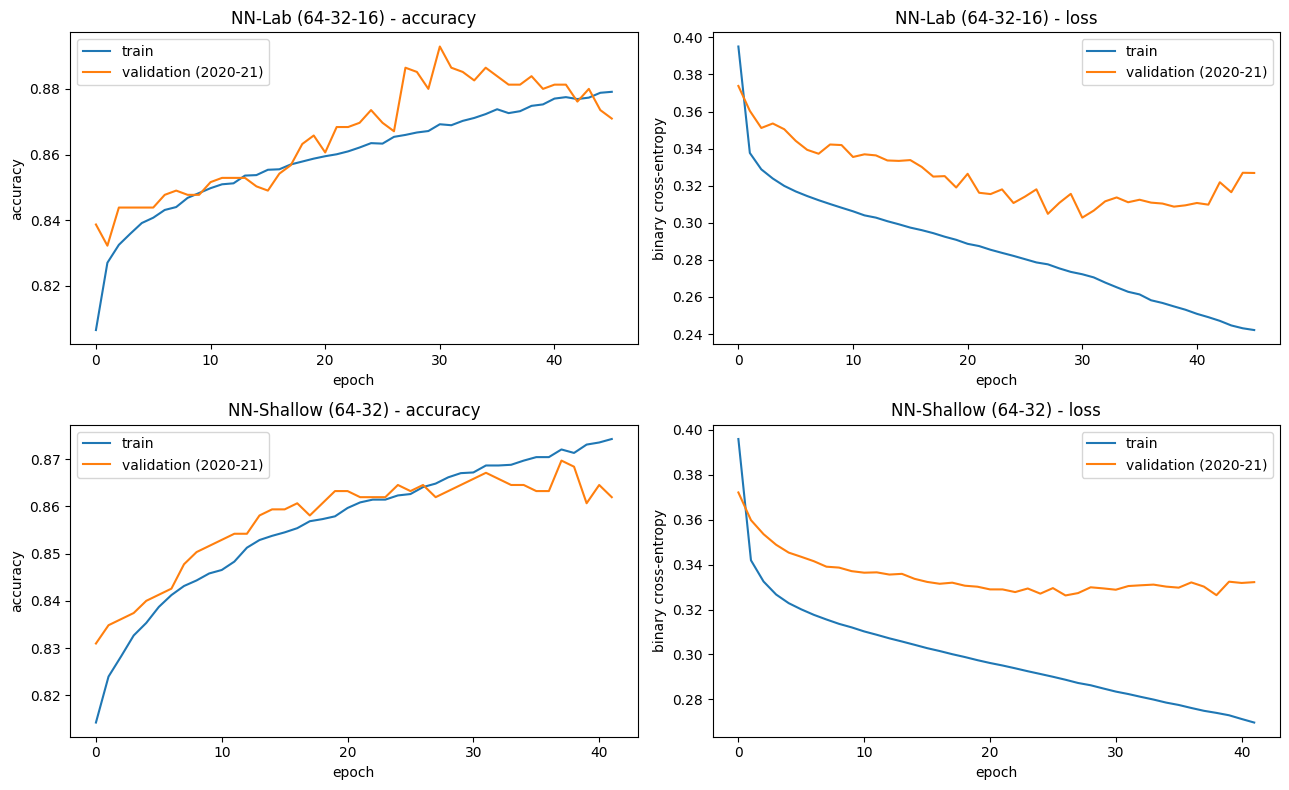

In [65]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, name in enumerate(histories):
    h = histories[name]
    ax_acc = axes[row, 0]
    ax_loss = axes[row, 1]

    ax_acc.plot(h['accuracy'], label='train')
    ax_acc.plot(h['val_accuracy'], label='validation (2020-21)')
    ax_acc.set_title(f'{name} - accuracy')
    ax_acc.set_xlabel('epoch')
    ax_acc.set_ylabel('accuracy')
    ax_acc.legend()

    ax_loss.plot(h['loss'], label='train')
    ax_loss.plot(h['val_loss'], label='validation (2020-21)')
    ax_loss.set_title(f'{name} - loss')
    ax_loss.set_xlabel('epoch')
    ax_loss.set_ylabel('binary cross-entropy')
    ax_loss.legend()
plt.tight_layout()
plt.show()

**What we see:** with class weights 0.58 / 3.52, a podium row counts about 6× as much as a non-podium row. NN-Lab (3,457 weights) stopped after 46 epochs, with its best validation loss at epoch 31 (0.303). NN-Shallow (2,945 weights) stopped after 42 epochs, best at epoch 27 (0.326). The curves show the usual pattern: training loss keeps falling, while validation loss flattens and then rises, so early stopping restores the weights from before overfitting starts. (The red CUDA line above the results only says that this Kaggle session has no GPU; training runs on the CPU.)

## 15. Evaluation
**Metrics:** PR-AUC is our **primary** metric: podiums are rare (~15 %), and PR-AUC measures how well a model ranks the
real podium finishers at the top, without being flattered by the many easy "no" rows (ROC-AUC can look high even for a
mediocre ranking when negatives dominate). F1 is the **secondary** metric, because it needs a yes/no decision.
**Threshold:** for each model we pick the probability threshold with the best F1 **on validation only**, then apply
that same threshold to train and test. The test set is used once, here, and nothing is changed afterwards.
**Reference:** the rule "grid ≤ 3 → podium" (no model) shows how much the models add on top of the grid.

In [66]:
def evaluate(y, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return {'ROC-AUC': roc_auc_score(y, prob), 'PR-AUC': average_precision_score(y, prob),
            'F1': f1_score(y, pred), 'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred), 'accuracy': accuracy_score(y, pred)}

def best_f1_threshold(y, prob):
    # try thresholds 0.05, 0.06, ..., 0.95 and keep the one with the highest F1
    thresholds = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(y, (prob >= t).astype(int)) for t in thresholds]
    return thresholds[int(np.argmax(f1s))]

# for every split: scaled X (LR and NNs), unscaled X (Random Forest and the rule), labels
splits = {'train': (X_train, X_train_filled, y_train),
          'validation': (X_val, X_val_filled, y_val),
          'test': (X_test, X_test_filled, y_test)}

# predicted podium probabilities, stored as probs[(model name, split)]
probs = {}
for split, (X_scaled, X_unscaled, y) in splits.items():
    probs[('Logistic Regression', split)] = lr.predict_proba(X_scaled)[:, 1]
    probs[('RF default', split)] = rf_default.predict_proba(X_unscaled)[:, 1]
    probs[('RF tuned', split)] = rf_tuned.predict_proba(X_unscaled)[:, 1]
    for name, net in nets.items():
        probs[(name, split)] = net.predict(X_scaled.values, verbose=0).ravel()
    probs[('Rule: grid <= 3', split)] = (X_unscaled['grid_pos'] <= 3).astype(float).values

model_names = ['Logistic Regression', 'RF default', 'RF tuned', 'NN-Lab (64-32-16)', 'NN-Shallow (64-32)', 'Rule: grid <= 3']

# one threshold per model, chosen on the validation seasons only
thresholds = {}
for m in model_names:
    if m.startswith('Rule'):
        thresholds[m] = 0.5          # the rule already outputs 0 or 1
    else:
        thresholds[m] = best_f1_threshold(y_val, probs[(m, 'validation')])

rows = []
for m in model_names:
    for split, (X_scaled, X_unscaled, y) in splits.items():
        row = {'model': m, 'split': split, 'threshold': thresholds[m]}
        row.update(evaluate(y, probs[(m, split)], thresholds[m]))
        rows.append(row)
results_table = pd.DataFrame(rows).round(3)
for split in ['validation', 'test', 'train']:
    print(f'--- {split} ---')
    print(results_table[results_table['split'] == split].drop(columns='split').to_string(index=False), '\n')

is_val = results_table['split'] == 'validation'
is_rule = results_table['model'].str.startswith('Rule')
val_table = results_table[is_val & ~is_rule]
best_model = val_table.sort_values('PR-AUC', ascending=False)['model'].iloc[0]
print('best model by validation PR-AUC:', best_model)

2026-10-19 19:42:27.408792: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


--- validation ---
              model  threshold  ROC-AUC  PR-AUC    F1  precision  recall  accuracy
Logistic Regression       0.72    0.924   0.696 0.699      0.659   0.744     0.903
         RF default       0.24    0.919   0.665 0.695      0.634   0.769     0.898
           RF tuned       0.80    0.933   0.719 0.706      0.750   0.667     0.916
  NN-Lab (64-32-16)       0.65    0.923   0.708 0.717      0.664   0.778     0.907
 NN-Shallow (64-32)       0.66    0.924   0.718 0.706      0.652   0.769     0.903
    Rule: grid <= 3       0.50    0.820   0.530 0.695      0.698   0.692     0.908 

--- test ---
              model  threshold  ROC-AUC  PR-AUC    F1  precision  recall  accuracy
Logistic Regression       0.72    0.932   0.690 0.657      0.578   0.760     0.880
         RF default       0.24    0.926   0.661 0.654      0.546   0.814     0.870
           RF tuned       0.80    0.934   0.684 0.642      0.681   0.608     0.898
  NN-Lab (64-32-16)       0.65    0.908   0.639 0.647

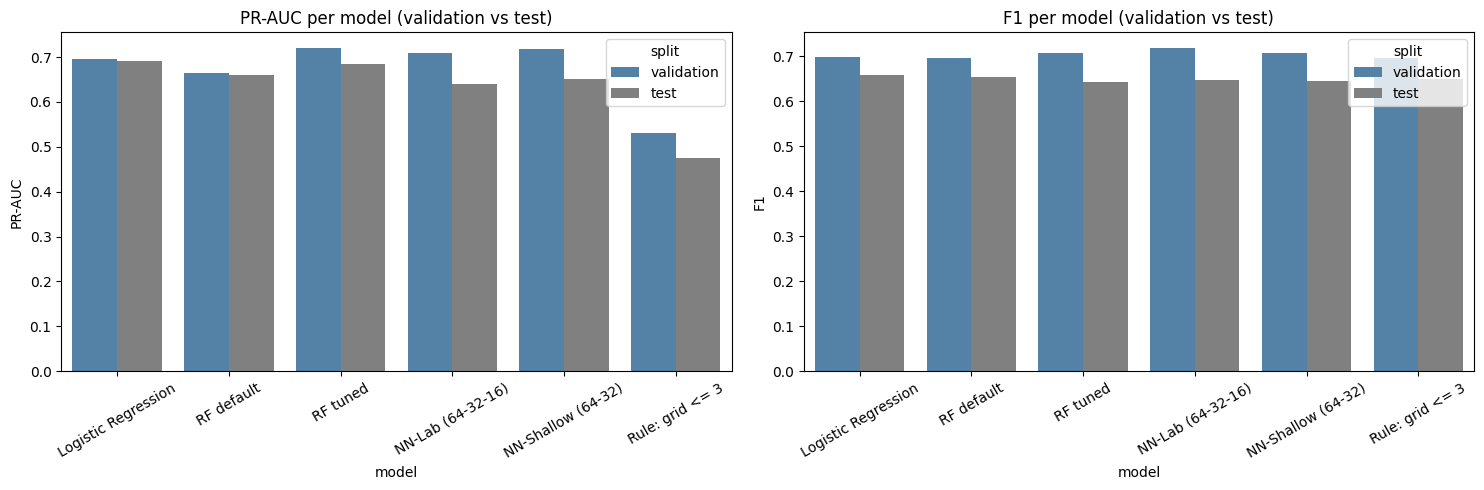

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ['PR-AUC', 'F1']):
    t = results_table[results_table['split'].isin(['validation', 'test'])]
    sns.barplot(data=t, x='model', y=metric, hue='split', ax=ax, palette=['steelblue', 'grey'])
    ax.set_title(f'{metric} per model (validation vs test)')
    ax.set_xlabel('model'); ax.set_ylabel(metric)
    ax.tick_params(axis='x', labelrotation=30)
plt.tight_layout()
plt.show()

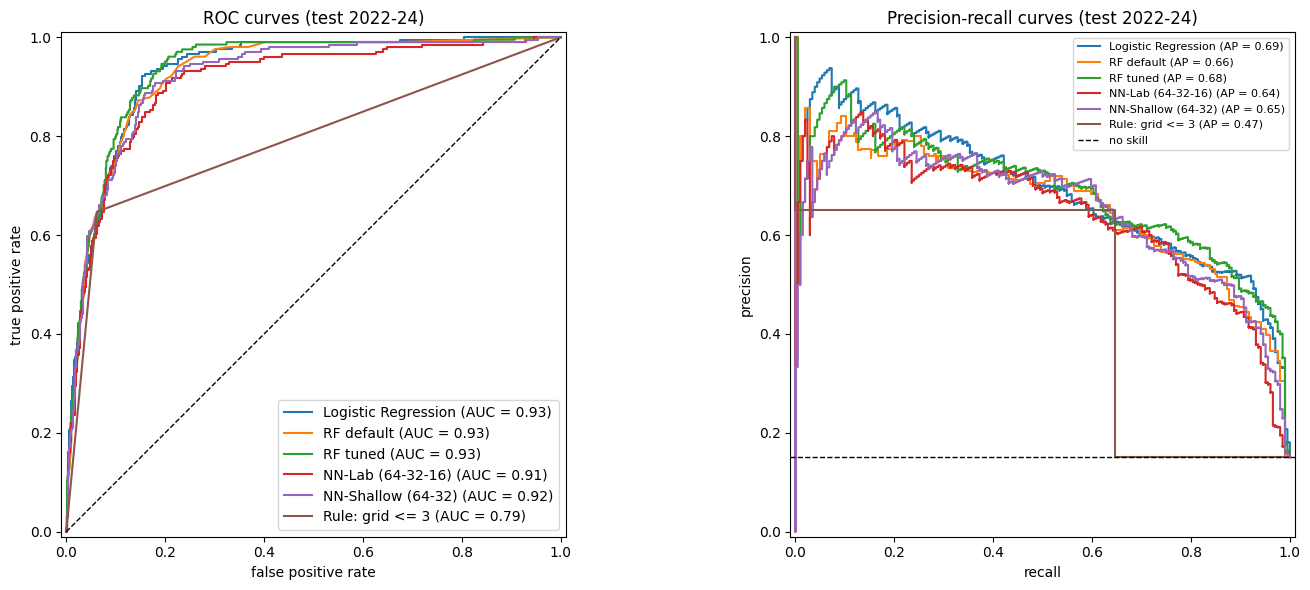

In [68]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for m in model_names:
    RocCurveDisplay.from_predictions(y_test, probs[(m, 'test')], name=m, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probs[(m, 'test')], name=m, ax=axes[1])
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0].set_title('ROC curves (test 2022-24)'); axes[0].set_xlabel('false positive rate'); axes[0].set_ylabel('true positive rate')
axes[1].axhline(y_test.mean(), color='k', linestyle='--', linewidth=1, label='no skill')
axes[1].set_title('Precision-recall curves (test 2022-24)'); axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**What we see:** 
- **Validation (used for every choice):** RF tuned has the best PR-AUC (0.719), just ahead of NN-Shallow (0.718) and NN-Lab (0.708); the logistic regression reaches 0.696, the default forest 0.665 and the grid rule 0.530.
- **Test (2022–24, used once):** every model stays well above the grid rule (PR-AUC 0.64–0.69 vs 0.47; ROC-AUC 0.91–0.93 vs 0.79), but the order changes. The baseline logistic regression is best on test (PR-AUC 0.690, F1 0.657), with RF tuned second (0.684, 0.642). The networks drop the most (NN-Shallow 0.718 → 0.652, NN-Lab 0.708 → 0.639), so they fitted the 2020–21 seasons more closely than the simpler models.
- **F1 vs ranking:** at a single threshold, the models barely beat the simple rule on test (F1 0.64–0.66 vs 0.649). Their real gain is in **ranking**: the precision-recall curves reach 75–90 % precision for the most confident podium calls, where the rule is stuck at about 65 %.
- The differences between the models are small (at most 0.05 PR-AUC), so most of the pre-race signal is already captured by a linear model. RF tuned is our chosen model because it was best on **validation**, the only fair way to choose; the test result does not change that choice.

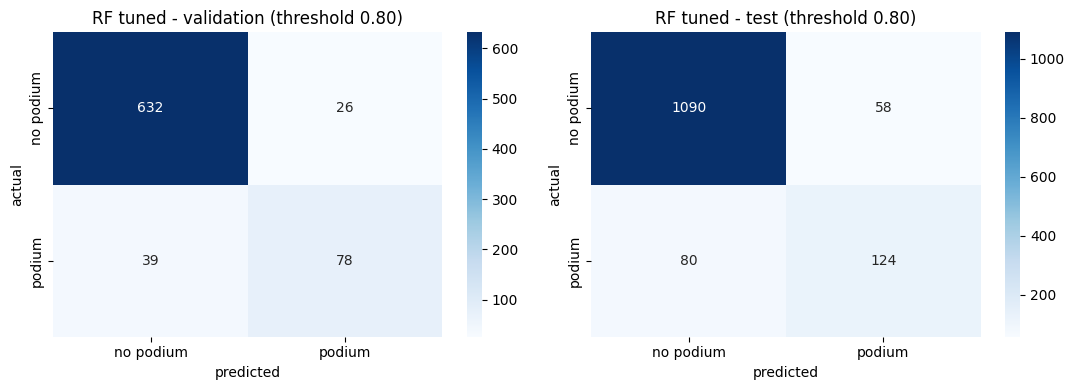

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, split, y in [(axes[0], 'validation', y_val), (axes[1], 'test', y_test)]:
    pred = (probs[(best_model, split)] >= thresholds[best_model]).astype(int)
    cm = confusion_matrix(y, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['no podium', 'podium'], yticklabels=['no podium', 'podium'])
    ax.set_title(f'{best_model} - {split} (threshold {thresholds[best_model]:.2f})')
    ax.set_xlabel('predicted'); ax.set_ylabel('actual')
plt.tight_layout()
plt.show()

**What we see:** with its validation threshold of 0.80, RF tuned finds 78 of the 117 validation podiums (recall 0.67) with only 26 false alarms (precision 0.75). On test it finds 124 of 204 podiums (recall 0.61) with 58 false alarms (precision 0.68). The strict threshold chosen on 2020–21 misses more podiums in 2022–24. That is the cost of choosing the threshold on validation only, which we accept so that the test seasons stay unseen.

## 16. Ablation — which feature groups matter?
Why: importance scores split the credit between correlated features (driver and team form are 0.89-correlated).
Dropping a **whole group** and retraining shows what the model really loses without it. We retrain the chosen model
(Random Forest with the tuned settings) once per group and compare PR-AUC with the full model. Two extra rows drop
two related groups together, to test the redundancy we saw in section 8.

In [70]:
groups = {'grid': ['grid_pos', 'pitlane_start'],
          'qualifying': ['quali_gap_pct', 'grid_minus_quali'],
          'driver form': ['drv_podium_5', 'drv_finish_5', 'drv_starts'],
          'constructor form': ['con_podium_5', 'con_mech_10'],
          'standings': ['drv_rank_before', 'con_rank_before'],
          'home race': ['home_race']}
groups['driver + constructor form'] = groups['driver form'] + groups['constructor form']
groups['grid + qualifying'] = groups['grid'] + groups['qualifying']

depth, leaf = best_params

def rf_scores(cols):
    rf = RandomForestClassifier(n_estimators=100, max_depth=depth, min_samples_leaf=leaf,
                                random_state=42, class_weight='balanced')
    rf.fit(X_train_filled[cols], y_train)
    return (average_precision_score(y_val, rf.predict_proba(X_val_filled[cols])[:, 1]),
            average_precision_score(y_test, rf.predict_proba(X_test_filled[cols])[:, 1]))

full_val, full_test = rf_scores(features)
rows = [{'dropped group': 'none (all 12)', 'features left': len(features),
         'validation PR-AUC': full_val, 'test PR-AUC': full_test}]
for group, cols in groups.items():
    keep = [f for f in features if f not in cols]
    v, t = rf_scores(keep)
    rows.append({'dropped group': group, 'features left': len(keep), 'validation PR-AUC': v, 'test PR-AUC': t})

ablation = pd.DataFrame(rows)
ablation['val drop'] = full_val - ablation['validation PR-AUC']
ablation['test drop'] = full_test - ablation['test PR-AUC']
print(ablation.round(3).to_string(index=False))

            dropped group  features left  validation PR-AUC  test PR-AUC  val drop  test drop
            none (all 12)             12              0.719        0.684     0.000      0.000
                     grid             10              0.703        0.651     0.017      0.034
               qualifying             10              0.708        0.705     0.012     -0.021
              driver form              9              0.724        0.698    -0.005     -0.013
         constructor form             10              0.729        0.687    -0.009     -0.002
                standings             10              0.703        0.662     0.017      0.023
                home race             11              0.721        0.687    -0.002     -0.003
driver + constructor form              7              0.723        0.690    -0.004     -0.006
        grid + qualifying              8              0.603        0.567     0.116      0.118


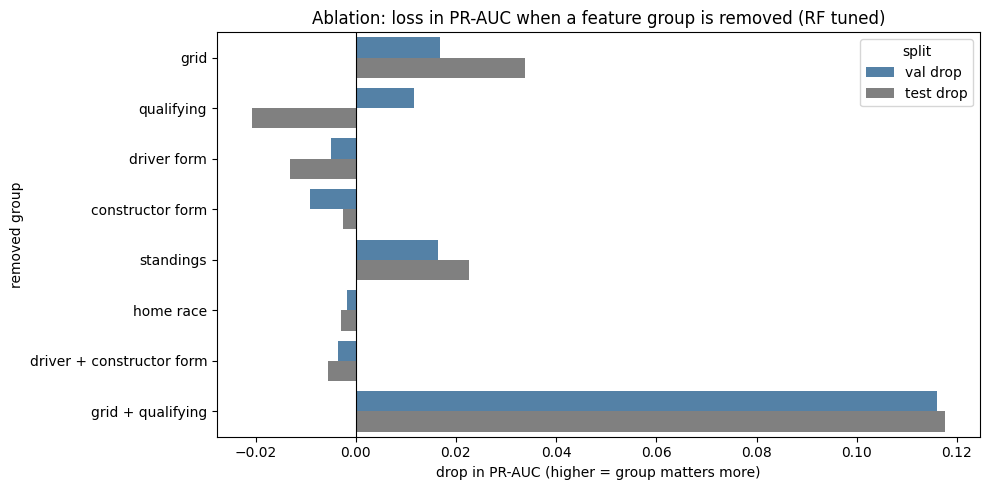

In [71]:
plot_abl = ablation.iloc[1:].melt(id_vars='dropped group', value_vars=['val drop', 'test drop'],
                                  var_name='split', value_name='PR-AUC drop')
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_abl, y='dropped group', x='PR-AUC drop', hue='split', palette=['steelblue', 'grey'])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Ablation: loss in PR-AUC when a feature group is removed (RF tuned)')
plt.xlabel('drop in PR-AUC (higher = group matters more)'); plt.ylabel('removed group')
plt.tight_layout()
plt.show()

**What we see:** the full model reaches PR-AUC 0.719 on validation and 0.684 on test.
- **Grid** (−0.017 / −0.034) and **standings** (−0.017 / −0.023) are the only single groups whose removal hurts on both validation and test.
- Removing **qualifying** hurts on validation (−0.012) but *helps* on test (+0.021), so its value is not stable across seasons.
- Removing **driver form**, **constructor form**, both form groups together, or **home race** changes PR-AUC by less than 0.015 and often slightly *improves* it: the form information is already carried by the standings and the grid.
- Removing **grid and qualifying together** costs 0.116 on validation and 0.118 on test, far more than either group alone (0.017 + 0.012). Both groups describe the same thing (how fast the car was on Saturday), so each one covers for the other when it is removed alone.
- `home_race` adds nothing (−0.002 / −0.003 when removed), which agrees with the Q2 answer.

## 17. Preprocessing-order experiments
Why: the brief asks whether the **order** of preprocessing steps changes the result. Random Forests do not care about
scaling, so we use the Logistic Regression (section 12), which does. Our pipeline is
**split → median fill (fit on train) → scale (fit on train)**. We compare it with two other orders:
- **A — scaler fitted before the split** (on all seasons 2003–2024): the scaler then "sees" validation and test data.
- **B — scale first, then fill:** the scaler is fitted on train with the gaps still in (`StandardScaler` skips NaN),
  and the gaps are filled afterwards with the median of the scaled train data.

In [72]:
def lr_scores(order, X_tr, X_v, X_te):
    model = LogisticRegression(max_iter=1000, class_weight='balanced')
    model.fit(X_tr, y_train)
    return {'order': order,
            'validation PR-AUC': average_precision_score(y_val, model.predict_proba(X_v)[:, 1]),
            'test PR-AUC': average_precision_score(y_test, model.predict_proba(X_te)[:, 1])}

order_rows = []

# ours: split -> fill -> scale (X_train, X_val, X_test from section 11)
order_rows.append(lr_scores('ours: split -> fill -> scale', X_train, X_val, X_test))

# A: scaler fitted on all seasons before the split
X_all_filled = pd.concat([X_train_filled, X_val_filled, X_test_filled])
scaler_all = StandardScaler()
scaler_all.fit(X_all_filled)
XA_train = pd.DataFrame(scaler_all.transform(X_train_filled), columns=features, index=X_train_filled.index)
XA_val = pd.DataFrame(scaler_all.transform(X_val_filled), columns=features, index=X_val_filled.index)
XA_test = pd.DataFrame(scaler_all.transform(X_test_filled), columns=features, index=X_test_filled.index)
order_rows.append(lr_scores('A: scaler fitted before split', XA_train, XA_val, XA_test))

# B: scale first (fit on train, NaN are skipped), then fill the gaps with the scaled train median
scaler_b = StandardScaler()
scaler_b.fit(X_train_raw)
SB_train = pd.DataFrame(scaler_b.transform(X_train_raw), columns=features, index=X_train_raw.index)
SB_val = pd.DataFrame(scaler_b.transform(X_val_raw), columns=features, index=X_val_raw.index)
SB_test = pd.DataFrame(scaler_b.transform(X_test_raw), columns=features, index=X_test_raw.index)
scaled_medians = SB_train.median()
XB_train = SB_train.fillna(scaled_medians)
XB_val = SB_val.fillna(scaled_medians)
XB_test = SB_test.fillna(scaled_medians)
order_rows.append(lr_scores('B: scale -> fill', XB_train, XB_val, XB_test))

order_table = pd.DataFrame(order_rows)
print(order_table.round(4).to_string(index=False))

                        order  validation PR-AUC  test PR-AUC
 ours: split -> fill -> scale             0.6961       0.6899
A: scaler fitted before split             0.6960       0.6899
             B: scale -> fill             0.6961       0.6898


In [73]:
# what each order changes in the data itself
cols = ['drv_starts', 'con_mech_10', 'drv_rank_before']
print('scaler mean used (fit on train vs fit on all seasons):')
print(pd.DataFrame({'train only': scaler.mean_, 'all seasons (A)': scaler_all.mean_}, index=features).loc[cols].round(2))
print('\nmean of the scaled test data (ours vs A) - the drift A hides:')
print(pd.DataFrame({'ours': X_test[cols].mean(), 'A': XA_test[cols].mean()}).round(2))
print('\ntrain mean / std after preprocessing (ours vs B) for the feature with most gaps:')
print(pd.DataFrame({'ours': [X_train['drv_rank_before'].mean(), X_train['drv_rank_before'].std()],
                    'B': [XB_train['drv_rank_before'].mean(), XB_train['drv_rank_before'].std()]},
                   index=['mean', 'std']).round(3))

scaler mean used (fit on train vs fit on all seasons):
                 train only  all seasons (A)
drv_starts            92.94           103.39
con_mech_10            0.12             0.10
drv_rank_before       11.25            11.11

mean of the scaled test data (ours vs A) - the drift A hides:
                 ours     A
drv_starts       0.67  0.49
con_mech_10     -0.56 -0.46
drv_rank_before -0.10 -0.08

train mean / std after preprocessing (ours vs B) for the feature with most gaps:
      ours      B
mean   0.0 -0.003
std    1.0  0.964


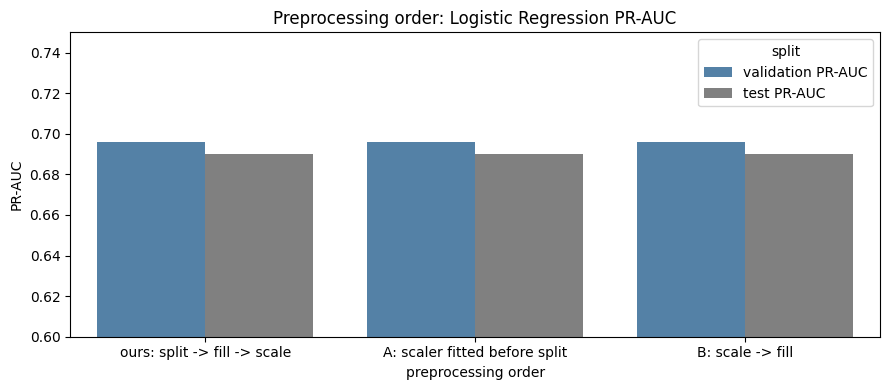

In [74]:
plot_order = order_table.melt(id_vars='order', var_name='split', value_name='PR-AUC')
plt.figure(figsize=(9, 4))
sns.barplot(data=plot_order, x='order', y='PR-AUC', hue='split', palette=['steelblue', 'grey'])
plt.ylim(0.6, 0.75)
plt.title('Preprocessing order: Logistic Regression PR-AUC')
plt.xlabel('preprocessing order'); plt.ylabel('PR-AUC')
plt.tight_layout()
plt.show()

**What we see:** the order makes almost no difference to the result here: validation PR-AUC is 0.6961 / 0.6960 / 0.6961 and test 0.6899 / 0.6899 / 0.6898.
- **A (scaler fitted before the split)** changes the scaling numbers (mean of `drv_starts` 92.9 → 103.4, because later seasons have more experienced drivers) and hides part of the drift: the scaled test mean of `drv_starts` falls from +0.67 to +0.49. The score barely moves because the logistic regression just rescales its weights, but it is still a leak: information from the test seasons enters the preprocessing, so we keep fitting on train only.
- **B (scale → fill)** leaves the filled feature slightly off-centre (`drv_rank_before` train mean −0.003, std 0.964 instead of 0 / 1), because the gaps are filled after the mean and std were computed. With at most 7.1 % missing this has no visible effect on PR-AUC.
- **Conclusion:** with median filling, standard scaling and few gaps, the order hardly changes the scores, but fit-on-train-only is the correct choice because it keeps the validation and test seasons unseen.

## 18. Explainable AI (XAI)
Why: we want to know **which features drive the predictions** of the chosen model (RF tuned), globally (over many
races) and locally (for one driver in one race). We use three methods, as in Lab 4:
- **Permutation importance** (global): shuffle one feature on the validation seasons and measure how much PR-AUC falls.
- **SHAP** (global + local): splits each prediction into a contribution per feature (`TreeExplainer`, Lab 4).
- **LIME** (local): fits a small linear model around one prediction (`LimeTabularExplainer`, Lab 4).

### 18.1 Permutation importance (validation seasons)

         feature  importance    std
        grid_pos      0.1109 0.0353
   quali_gap_pct      0.0191 0.0289
    con_podium_5      0.0058 0.0180
    drv_podium_5      0.0037 0.0091
 drv_rank_before      0.0014 0.0107
   pitlane_start      0.0000 0.0000
       home_race     -0.0008 0.0007
grid_minus_quali     -0.0011 0.0046
     con_mech_10     -0.0015 0.0043
    drv_finish_5     -0.0021 0.0028
 con_rank_before     -0.0025 0.0072
      drv_starts     -0.0057 0.0079


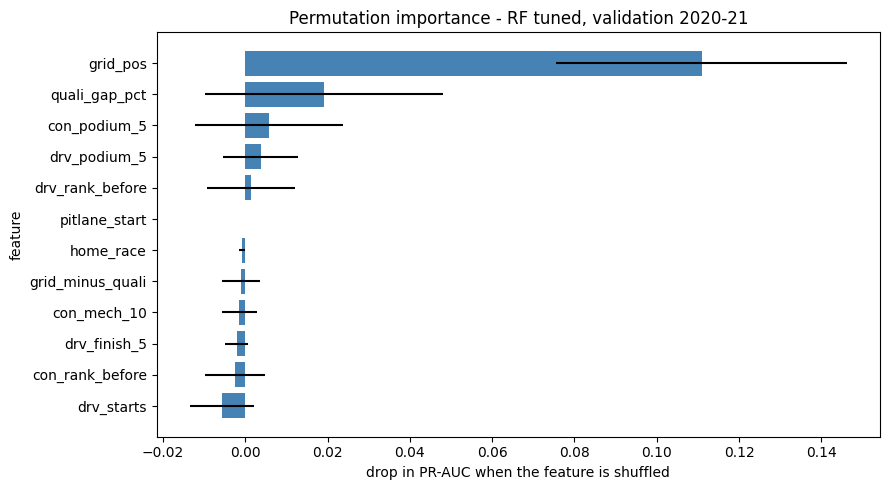

In [75]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf_tuned, X_val_filled, y_val, scoring='average_precision',
                              n_repeats=10, random_state=42)
perm_df = pd.DataFrame({'feature': features, 'importance': perm.importances_mean,
                        'std': perm.importances_std}).sort_values('importance', ascending=False)
print(perm_df.round(4).to_string(index=False))

plt.figure(figsize=(9, 5))
plt.barh(perm_df['feature'], perm_df['importance'], xerr=perm_df['std'], color='steelblue')
plt.gca().invert_yaxis()
plt.title('Permutation importance - RF tuned, validation 2020-21')
plt.xlabel('drop in PR-AUC when the feature is shuffled'); plt.ylabel('feature')
plt.tight_layout()
plt.show()

**What we see:** on the 2020–21 seasons, shuffling `grid_pos` lowers PR-AUC by 0.111, far more than any other feature. Next come `quali_gap_pct` (0.019), `con_podium_5` (0.006) and `drv_podium_5` (0.004); all others are about 0 or slightly negative (within their standard deviation). The small values for the form and standings features do **not** mean they are useless: they are strongly correlated with each other (0.88–0.89), so when one is shuffled the forest uses its partner instead. That is why the group ablation in section 16 is the better test for them.

### 18.2 SHAP — global view (test seasons 2022–24)

SHAP values: (1352, 12) | base value (average prediction): 0.5


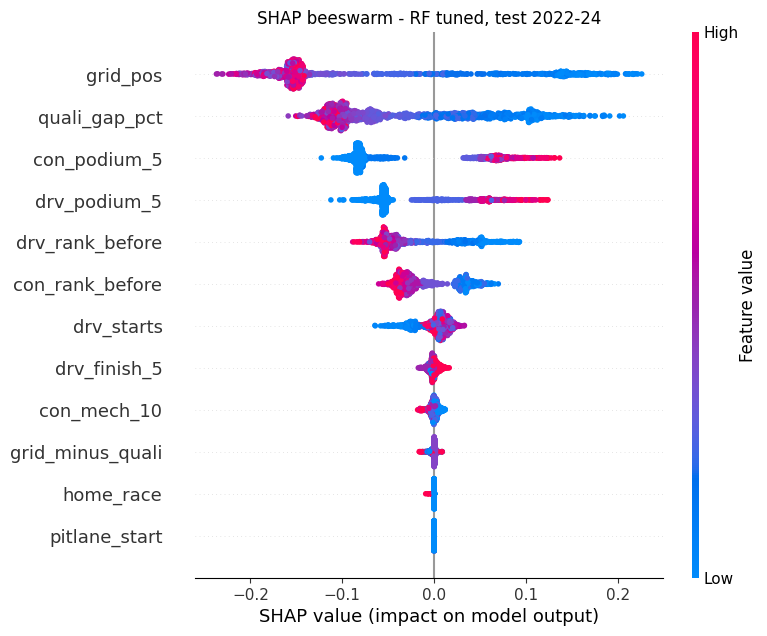

In [76]:
import shap

explainer = shap.TreeExplainer(rf_tuned)
shap_values = explainer(X_test_filled)            # shape: rows x features x classes
shap_podium = shap_values[:, :, 1]                # contributions to the "podium" class
print('SHAP values:', shap_podium.values.shape, '| base value (average prediction):',
      round(float(explainer.expected_value[1]), 3))

shap.summary_plot(shap_podium.values, X_test_filled, show=False)
plt.title('SHAP beeswarm - RF tuned, test 2022-24')
plt.show()

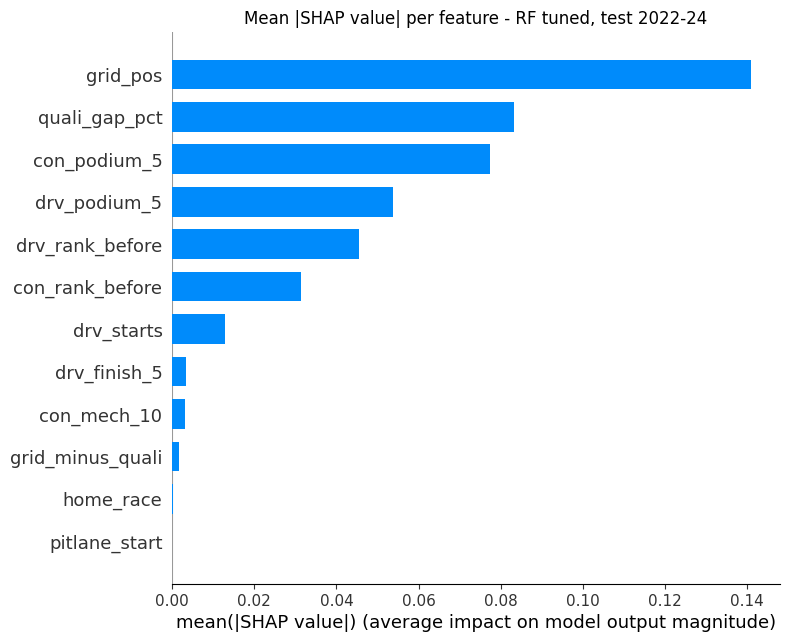

In [77]:
shap.summary_plot(shap_podium.values, X_test_filled, plot_type='bar', show=False)
plt.title('Mean |SHAP value| per feature - RF tuned, test 2022-24')
plt.show()

**What we see:** SHAP gives the same order at the top, but spreads the credit more evenly than permutation importance: `grid_pos` (mean |SHAP| ≈ 0.14), `quali_gap_pct` (≈ 0.08), `con_podium_5` (≈ 0.08), `drv_podium_5` (≈ 0.05), then the two ranks. The beeswarm shows the expected directions: a **low** grid slot, a **small** gap to pole, a **high** recent podium share and a **good** (low) championship rank all push the prediction towards a podium. `home_race` and `pitlane_start` have almost no effect.

### 18.3 SHAP and LIME — local view for one driver
We explain Lando Norris at the 2024 Miami Grand Prix (his first win).

In [78]:
norris_id = drivers.loc[(drivers['forename'] == 'Lando') & (drivers['surname'] == 'Norris'), 'driverId'].iloc[0]
idx = test.index[(test['driverId'] == norris_id) & (test['year'] == 2024) & (test['name'] == 'Miami Grand Prix')][0]
pos = X_test_filled.index.get_loc(idx)
print(test.loc[idx, ['year', 'name', 'grid_pos', 'positionOrder', 'podium']])
print('\nfeatures:\n', X_test_filled.loc[idx])
print('\npredicted podium probability:', round(rf_tuned.predict_proba(X_test_filled.loc[[idx]])[0, 1], 3),
      '| threshold:', round(thresholds['RF tuned'], 2))

year                         2024
name             Miami Grand Prix
grid_pos                        5
positionOrder                   1
podium                          1
Name: 8537, dtype: object

features:
 grid_pos              5.000000
pitlane_start         0.000000
quali_gap_pct         0.404626
grid_minus_quali      0.000000
drv_podium_5          0.400000
drv_finish_5          1.000000
drv_starts          109.000000
con_podium_5          0.200000
con_mech_10           0.050000
drv_rank_before       5.000000
con_rank_before       3.000000
home_race             0.000000
Name: 8537, dtype: float64

predicted podium probability: 0.723 | threshold: 0.8


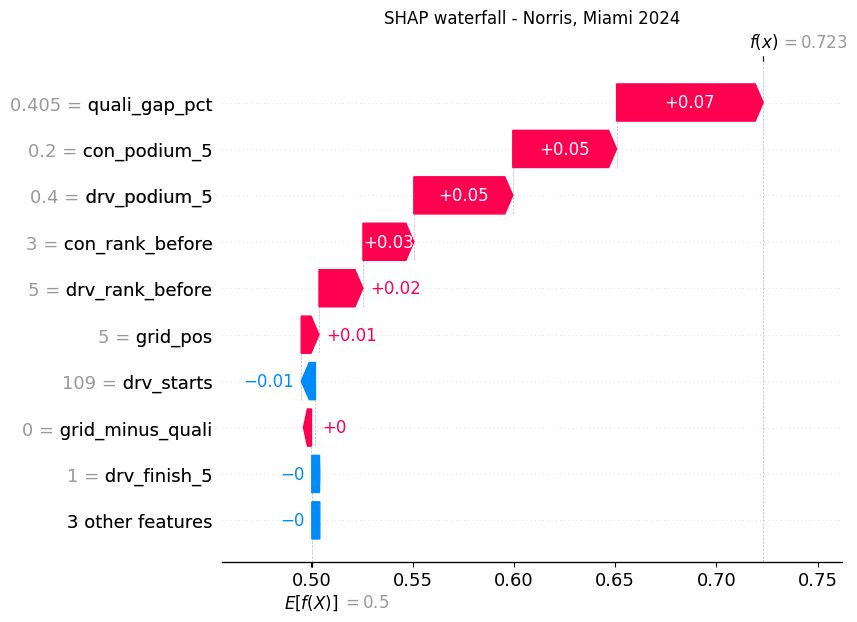

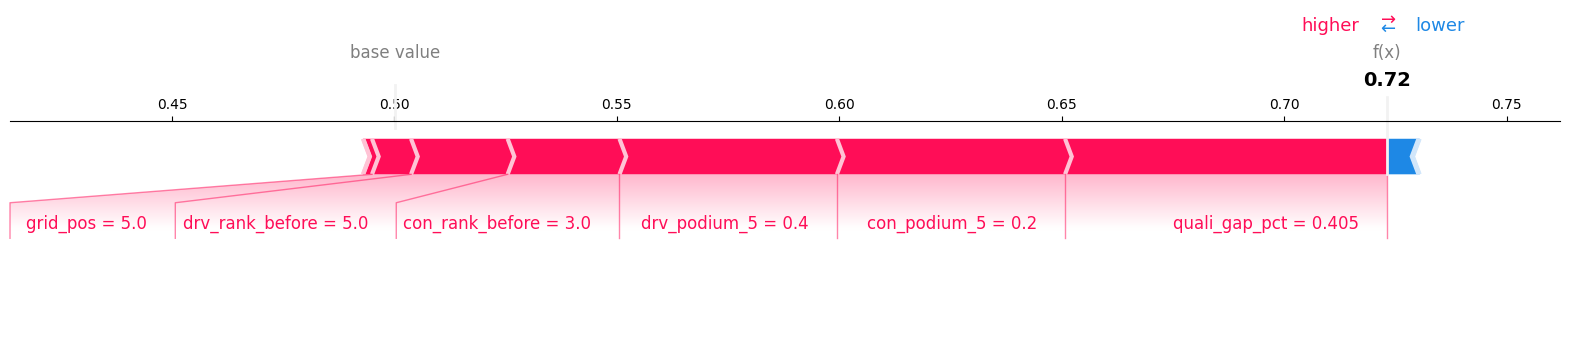

In [79]:
shap.plots.waterfall(shap_podium[pos], show=False)
plt.title('SHAP waterfall - Norris, Miami 2024')
plt.show()

shap.force_plot(explainer.expected_value[1], shap_podium.values[pos], X_test_filled.loc[idx].round(3),
                matplotlib=True)

In [80]:
import lime.lime_tabular

lime_explainer = lime.lime_tabular.LimeTabularExplainer(X_train_filled.values, feature_names=features,
                                                        class_names=['no podium', 'podium'],
                                                        discretize_continuous=True, random_state=42)
lime_exp = lime_explainer.explain_instance(X_test_filled.loc[idx].values, rf_tuned.predict_proba, num_features=8)
lime_exp.show_in_notebook()

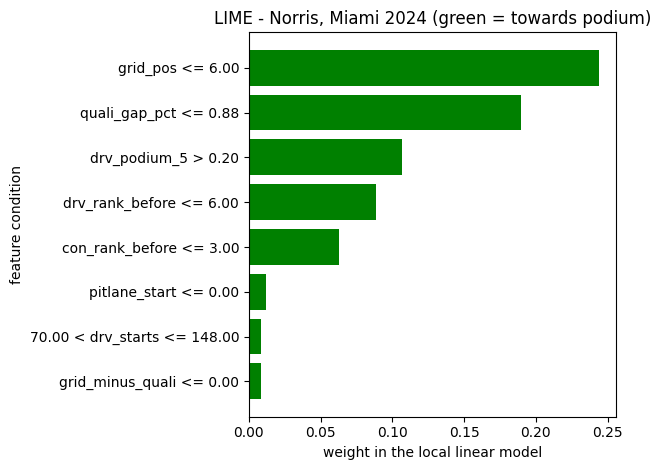

In [81]:
lime_exp.as_pyplot_figure()
plt.title('LIME - Norris, Miami 2024 (green = towards podium)')
plt.xlabel('weight in the local linear model'); plt.ylabel('feature condition')
plt.tight_layout()
plt.show()

**What we see:** Norris started 5th in Miami 2024 and won. The model gives him a podium probability of 0.72 (base value 0.50), which is high, but just below the 0.80 threshold chosen on validation, so the yes/no answer is "no podium". SHAP shows what pushed him up: a small qualifying gap (0.40 % to pole, +0.07), McLaren's recent podiums (+0.05), his own recent podiums (+0.05) and the team's 3rd place in the standings (+0.03). The grid slot itself adds only +0.01, because P5 is a borderline slot. LIME agrees on the direction for the same driver (podium 0.72): grid ≤ 6 (+0.24), quali gap ≤ 0.88 % (+0.19), driver podium share > 0.2 (+0.11), driver rank ≤ 6 (+0.09). LIME gives the grid more weight than SHAP because it explains with simple rules ("grid ≤ 6") fitted around this one driver, while SHAP shares the credit between the correlated grid and qualifying features.

### Importance is not causation
All three methods describe **what the model uses**, not what causes a podium in the real world. A high SHAP value for
`con_podium_5` means the model relies on recent team results; it does not mean that recent podiums *make* a car fast.
Both are driven by things we do not measure (car performance, budget, driver skill). Correlated features also share
credit: if one of them is removed, the other one takes over (see the ablation in section 16). So these plots tell us
how the model reasons and whether that reasoning is sensible, not how to win a race.

## 19. Inference function
Why: the model must be usable on a new race entry. `predict_podium(record)` takes a dictionary with any of the 12
features, applies **the same preprocessing as training** (clip the qualifying gap at the train cap, fill missing
features with the **train medians**) and returns the podium probability and the yes/no decision at the validation
threshold of the chosen model.

In [82]:
def predict_podium(record, model=rf_tuned, threshold=thresholds['RF tuned']):
    row = pd.DataFrame([record]).reindex(columns=features)        # unknown keys dropped, missing features -> NaN
    missing = [f for f in features if pd.isnull(row.loc[0, f])]
    row['quali_gap_pct'] = row['quali_gap_pct'].clip(upper=gap_cap)
    row = row.fillna(train_medians)
    prob = model.predict_proba(row)[0, 1]
    return {'podium probability': round(float(prob), 3), 'podium': bool(prob >= threshold),
            'filled with train median': missing}

# 1) complete record: Norris, Miami 2024 (from the test set)
complete = test.loc[idx, features].to_dict()
print('complete record:', predict_podium(complete))

# 2) same driver, qualifying information missing
partial = {k: v for k, v in complete.items() if k not in ['quali_gap_pct', 'grid_minus_quali']}
print('qualifying missing:', predict_podium(partial))

# 3) a hand-made record: a midfield driver starting 12th, no recent podiums
print('hand-made midfield record:', predict_podium({'grid_pos': 12, 'drv_podium_5': 0, 'con_podium_5': 0,
                                                     'drv_rank_before': 11, 'con_rank_before': 6}))

complete record: {'podium probability': 0.723, 'podium': False, 'filled with train median': []}
qualifying missing: {'podium probability': 0.582, 'podium': False, 'filled with train median': ['quali_gap_pct', 'grid_minus_quali']}
hand-made midfield record: {'podium probability': 0.038, 'podium': False, 'filled with train median': ['pitlane_start', 'quali_gap_pct', 'grid_minus_quali', 'drv_finish_5', 'drv_starts', 'con_mech_10', 'home_race']}


**What we see:** for the complete Norris record the function returns the same probability as the model itself (0.723), which shows that the preprocessing inside the function matches training. When the qualifying information is missing, the two qualifying features are filled with the train medians (a typical midfield qualifying gap and no grid change) and the probability drops to 0.58, so missing data makes the model more cautious, not wrong in direction. The hand-made midfield driver (P12, no recent podiums) gets 0.04. The function also lists which features it had to fill, so the user can see how much of a prediction is based on real data.

## 20. Conclusions and limitations
**Data and questions**
- Cleaning to one row per (race, driver) changed the data mainly before 1996 (non-qualifiers, shared drives); the podium share in 2003–2024 is 14.4 %.
- **Q1:** front-row starts convert to a podium more often since 2014 (64.6 % → 76.2 %), and the circuit ranking changed completely (Spearman −0.04): Suzuka, Hungaroring, Bahrain and Barcelona led in 1994–2013; Monaco, Suzuka and Yas Marina lead in 2014–24.
- **Q2:** there is no home advantage once the starting position is controlled for (odds ratio 0.90, 95 % interval 0.76–1.07).
- **Q3:** mechanical retirements fell from 8.9 % (2014–21) to 5.5 % (2022–24); Caterham, Lotus F1 and Toro Rosso were the least reliable in 2014–21, Alfa Romeo and Alpine in 2022–24.

**Model**
- All models beat the "grid ≤ 3" rule clearly in ranking (test PR-AUC 0.64–0.69 vs 0.47). The differences between Logistic Regression, Random Forest and the neural networks are small (≤ 0.05 PR-AUC).
- We chose **RF tuned** because it had the best validation PR-AUC (0.719). On the unseen 2022–24 seasons it reaches PR-AUC 0.684 and F1 0.642, finding 124 of 204 podiums.
- The grid position and the qualifying gap carry most of the signal (ablation: −0.12 PR-AUC without both), followed by the championship standings and recent form. Home race adds nothing.

**Limitations**
- **Qualifying coverage:** qualifying data is complete only from 2003, so the model is trained on 2003–2019 and cannot use earlier seasons.
- **Era and regulation changes:** the grid became more decisive over time and reliability improved a lot, so patterns learned on 2003–2019 drift in 2020–24 (visible in the scaled feature means and in the drop from validation to test).
- **Threshold:** the 0.80 threshold chosen on 2020–21 is strict for 2022–24 (e.g. the Miami 2024 winner gets 0.72 → "no podium"); probabilities are more useful than the yes/no label.
- **Shared drives and renamed teams:** shared drives (1950–1964) were reduced to one row per driver, and renamed teams (Toro Rosso → AlphaTauri → RB) are kept as separate constructors, which breaks the form history at each rename.
- **Missing context:** we do not use weather, safety cars, tyre strategy, car upgrades or penalties announced after qualifying; these explain many surprise podiums.
- **Importance is not causation:** the XAI results show what the model uses, not what makes a driver finish on the podium.

**Bonus (section 21):** 13 variants of the cleaning and split were tested. The best one on validation (V13: missing values filled with their F1 meaning, the two redundant constructor features dropped, validation 2019–21) raises the test PR-AUC of RF tuned from 0.684 to 0.692 and F1 from 0.642 to 0.686. The gain is small; leakage and random splits change the numbers far more.

## 21. Bonus — a better cleaning and split (V13)
Why: sections 3–15 make one choice for each cleaning and split step. For the bonus we tested whether other choices
give a better model. We ran **13 copies of this notebook (V01–V13)**; each copy changes one thing and trains the same
three models (Logistic Regression, the tuned Random Forest, NN-Shallow 64→32). As in section 15, the threshold is
chosen on validation and each copy keeps the model with the best **validation** PR-AUC.
All 13 runs: https://www.kaggle.com/code/amreladawy2/f1-ms1-bonus-cleaning-and-split

| copy | what changes | chosen model | val PR-AUC | test PR-AUC | test F1 |
|---|---|---|---|---|---|
| V01 | nothing (sections 3–15 above) | RF | 0.719 | 0.684 | 0.642 |
| V02 | missing values filled with their F1 meaning | RF | 0.719 | 0.688 | 0.678 |
| V03 | training rows with a missing value dropped | RF | 0.716 | 0.694 | 0.652 |
| V04 | no clipping of the qualifying gap | RF | 0.722 | 0.685 | 0.624 |
| V05 | 3 weakest features dropped (\|ρ\| ≤ 0.02) | RF | 0.718 | 0.687 | 0.670 |
| V06 | 2 redundant constructor features dropped | RF | 0.724 | 0.687 | 0.662 |
| V07 | **leak demo:** standings *after* the race | RF | 0.760 | 0.736 | 0.671 |
| V08 | random 70/15/15 split of rows (as in the labs) | RF | 0.713 | 0.702* | 0.678* |
| V09 | random 70/15/15 split of whole races | RF | 0.784 | 0.683* | 0.680* |
| V10 | train on 2010–2019 only | RF | 0.727 | 0.689 | 0.619 |
| V11 | validation 2019–21 (train 2003–18) | RF | 0.741** | 0.698 | 0.662 |
| V12 | V06 + V11 | RF | 0.748** | 0.695 | 0.679 |
| **V13** | **V12 + V02** | **RF** | **0.750**\*\* | **0.692** | **0.686** |

\* own random test set, not comparable. \*\* validation 2019–21, comparable only with V11–V13.

What the grid shows: the leak (V07) is by far the biggest effect, and random splits give an over-optimistic validation
score (V09: 0.784 on validation, 0.683 on test). The honest cleaning choices move PR-AUC by about 0.01.
**V13** combines the best change of each kind and has the best validation score of V11–V13, so it is the setup we
recommend. It has three changes, which the cells below apply to the same `feat` table as before:
1. **Missing values filled with their F1 meaning** instead of the train median (V02).
2. **Drop `con_podium_5` and `con_rank_before`**: they copy `drv_podium_5` and `drv_rank_before` (ρ 0.89 / 0.88, section 8.1) (V06).
3. **One more validation season**: train 2003–2018, validation 2019–2021 (60 races instead of 39), test 2022–2024 unchanged (V11).

In [83]:
# V13 features: the 12 features without the two constructor copies of driver features
bonus_features = [f for f in features if f not in ['con_podium_5', 'con_rank_before']]
print(len(bonus_features), 'features:', bonus_features)

# V13 split: train 2003-2018, validation 2019-2021, test 2022-2024 (same test seasons as section 10)
b_train = model_df[model_df['year'] <= 2018]
b_val = model_df[model_df['year'].between(2019, 2021)]
b_test = model_df[model_df['year'] >= 2022]

b_split_table = pd.DataFrame({
    'seasons': ['2003-2018', '2019-2021', '2022-2024'],
    'rows': [len(b_train), len(b_val), len(b_test)],
    'races': [b_train['raceId'].nunique(), b_val['raceId'].nunique(), b_test['raceId'].nunique()],
    'podium rate': [b_train['podium'].mean(), b_val['podium'].mean(), b_test['podium'].mean()]},
    index=['train', 'validation', 'test']).round(3)
print(b_split_table)
print('overlap of races between splits:',
      len(set(b_train['raceId']) & set(b_val['raceId'])) + len(set(b_val['raceId']) & set(b_test['raceId'])))

10 features: ['grid_pos', 'pitlane_start', 'quali_gap_pct', 'grid_minus_quali', 'drv_podium_5', 'drv_finish_5', 'drv_starts', 'con_mech_10', 'drv_rank_before', 'home_race']
              seasons  rows  races  podium rate
train       2003-2018  6363    300        0.141
validation  2019-2021  1195     60        0.151
test        2022-2024  1352     68        0.151
overlap of races between splits: 0


### 21.1 Filling the gaps with their F1 meaning
Why: the median says "an average driver", but most gaps have a clear meaning. A missing rank before round 1 means the
driver has **no standing yet**, not a midfield rank (the train median rank is 11). A missing podium history means a
**debut**, so 0 podiums. The fill values come from the race itself or from the training seasons only:

| feature | why it is missing | filled with |
|---|---|---|
| `drv_rank_before` | first round of the season, no standings yet | the field size of that race (back of the field) |
| `drv_podium_5` | first start of the driver | 0 (no podium history) |
| `quali_gap_pct` | no qualifying time set | the clip value (train 99th percentile, a very slow lap) |
| `grid_minus_quali` | no qualifying row | 0 (no known penalty) |
| `drv_finish_5`, others | debut or first races of a team | train median, as in section 11 |

In [84]:
Xb_train_raw, yb_train = b_train[bonus_features].copy(), b_train['podium']
Xb_val_raw, yb_val = b_val[bonus_features].copy(), b_val['podium']
Xb_test_raw, yb_test = b_test[bonus_features].copy(), b_test['podium']

# clip the qualifying gap at the train 99th percentile, as in section 11
b_gap_cap = Xb_train_raw['quali_gap_pct'].quantile(0.99)
for x in [Xb_train_raw, Xb_val_raw, Xb_test_raw]:
    x['quali_gap_pct'] = x['quali_gap_pct'].clip(upper=b_gap_cap)
print(f'quali_gap_pct clipped at {b_gap_cap:.2f} %')

print('\nmissing values before filling (train / val / test):')
b_missing = pd.DataFrame({'train': Xb_train_raw.isnull().sum(), 'val': Xb_val_raw.isnull().sum(),
                          'test': Xb_test_raw.isnull().sum()})
print(b_missing[b_missing.sum(axis=1) > 0])

b_train_medians = Xb_train_raw.median()

def domain_fill(x, data):
    # fill each gap with what it means in F1 (fixed values or values from the training seasons)
    x = x.copy()
    x['drv_rank_before'] = x['drv_rank_before'].fillna(data['field'])     # no standing yet = back of the field
    x['drv_podium_5'] = x['drv_podium_5'].fillna(0)                       # debut = no podium history
    x['quali_gap_pct'] = x['quali_gap_pct'].fillna(Xb_train_raw['quali_gap_pct'].quantile(0.99))  # no time = very slow
    x['grid_minus_quali'] = x['grid_minus_quali'].fillna(0)               # no qualifying row = no known penalty
    return x.fillna(b_train_medians)                                      # anything else: train median

Xb_train_filled = domain_fill(Xb_train_raw, b_train)
Xb_val_filled = domain_fill(Xb_val_raw, b_val)
Xb_test_filled = domain_fill(Xb_test_raw, b_test)

# the effect on the rank before round 1: median fill vs domain fill
gap_rows = Xb_train_raw['drv_rank_before'].isnull()
print('\ntrain rows without a rank:', int(gap_rows.sum()),
      '| median fill would give', b_train_medians['drv_rank_before'],
      '| domain fill gives', Xb_train_filled.loc[gap_rows, 'drv_rank_before'].mean().round(1), 'on average')

b_scaler = StandardScaler()
b_scaler.fit(Xb_train_filled)
Xb_train = pd.DataFrame(b_scaler.transform(Xb_train_filled), columns=bonus_features, index=Xb_train_filled.index)
Xb_val = pd.DataFrame(b_scaler.transform(Xb_val_filled), columns=bonus_features, index=Xb_val_filled.index)
Xb_test = pd.DataFrame(b_scaler.transform(Xb_test_filled), columns=bonus_features, index=Xb_test_filled.index)
b_missing_left = Xb_train.isnull().sum().sum() + Xb_val.isnull().sum().sum() + Xb_test.isnull().sum().sum()
print('missing left:', int(b_missing_left))

quali_gap_pct clipped at 12.95 %

missing values before filling (train / val / test):
                  train  val  test
quali_gap_pct       111   20    13
grid_minus_quali     18    3     0
drv_podium_5         72    9     8
drv_finish_5         72    9     8
con_mech_10          33    6     2
drv_rank_before     463   63    68

train rows without a rank: 463 | median fill would give 11.0 | domain fill gives 21.0 on average
missing left: 0


### 21.2 The three models on the V13 data
Same models and settings as sections 12–14, each fitted with `verbose=1` so the training log is visible.

In [85]:
b_lr = LogisticRegression(max_iter=1000, class_weight='balanced', verbose=1)
b_lr.fit(Xb_train, yb_train)
print('Logistic Regression validation PR-AUC:', round(average_precision_score(yb_val, b_lr.predict_proba(Xb_val)[:, 1]), 3))

Logistic Regression validation PR-AUC: 0.712


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


In [86]:
# same 12-setting grid as section 13.1, scored on the 2019-2021 validation seasons
b_tried = []
b_best_score = -1
for depth in [None, 5, 10, 15]:
    for leaf in [1, 5, 20]:
        rf = RandomForestClassifier(n_estimators=100, max_depth=depth, min_samples_leaf=leaf,
                                    random_state=42, class_weight='balanced', verbose=1)
        rf.fit(Xb_train_filled, yb_train)
        score_val = average_precision_score(yb_val, rf.predict_proba(Xb_val_filled)[:, 1])
        b_tried.append({'max_depth': str(depth), 'min_samples_leaf': leaf, 'validation PR-AUC': round(score_val, 3)})
        if score_val > b_best_score:          # keep the best forest so far
            b_best_score = score_val
            b_rf = rf
            b_best_params = (depth, leaf)

b_rf.verbose = 0          # keep the training log only, not one log line per prediction
print(pd.DataFrame(b_tried).sort_values('validation PR-AUC', ascending=False).to_string(index=False))
print('\nbest settings: max_depth =', b_best_params[0], '| min_samples_leaf =', b_best_params[1],
      '| validation PR-AUC =', round(b_best_score, 3))

[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.5s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.9s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.4s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.8s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.3s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.7s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.3s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.5s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: 

max_depth  min_samples_leaf  validation PR-AUC
     None                20              0.750
       15                20              0.750
       10                20              0.748
       10                 5              0.742
     None                 5              0.740
       15                 5              0.736
        5                20              0.734
        5                 1              0.734
        5                 5              0.733
     None                 1              0.702
       15                 1              0.702
       10                 1              0.698

best settings: max_depth = 15 | min_samples_leaf = 20 | validation PR-AUC = 0.75


[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.7s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished


In [87]:
# NN-Shallow (64 -> 32), as in section 14, with class weights from the V13 training seasons
b_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=yb_train)
b_class_weight = {0: float(b_weights[0]), 1: float(b_weights[1])}

tf.keras.utils.set_random_seed(42)
b_nn = keras.Sequential()
b_nn.add(keras.Input(shape=(len(bonus_features),)))
b_nn.add(keras.layers.Dense(64, activation='relu'))
b_nn.add(keras.layers.Dense(32, activation='relu'))
b_nn.add(keras.layers.Dense(1, activation='sigmoid'))
b_nn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
b_early = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
b_history = b_nn.fit(Xb_train.values, yb_train.values, validation_data=(Xb_val.values, yb_val.values),
                     epochs=200, batch_size=32, class_weight=b_class_weight, callbacks=[b_early], verbose=1)
print('NN-Shallow: stopped after', len(b_history.history['loss']), 'epochs | best epoch',
      int(np.argmin(b_history.history['val_loss'])) + 1, '| best val_loss', round(min(b_history.history['val_loss']), 4))

Epoch 1/200


2026-10-19 19:43:05.996509: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


199/199 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7981 - loss: 0.4230 - val_accuracy: 0.8644 - val_loss: 0.3575
Epoch 2/200
199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8315 - loss: 0.3527 - val_accuracy: 0.8703 - val_loss: 0.3325
Epoch 3/200
199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8347 - loss: 0.3418 - val_accuracy: 0.8695 - val_loss: 0.3220
Epoch 4/200
199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8377 - loss: 0.3359 - val_accuracy: 0.8695 - val_loss: 0.3156
Epoch 5/200
199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8388 - loss: 0.3317 - val_accuracy: 0.8711 - val_loss: 0.3121
Epoch 6/200
199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8406 - loss: 0.3285 - val_accuracy: 0.8728 - val_loss: 0.3074
Epoch 7/200
199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8417 - loss: 0.3258 - val_accuracy: 0.8728 - val_loss: 0.3057
Epoch 8/200
199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8430 - loss: 0.3233 - val_accuracy: 0.8720

### 21.3 Results: V13 vs the submitted setup
The threshold of each model is chosen on the V13 validation seasons (2019–21) with `best_f1_threshold` from section 15.

In [88]:
b_probs = {}
for split, X_scaled, X_unscaled in [('validation', Xb_val, Xb_val_filled), ('test', Xb_test, Xb_test_filled)]:
    b_probs[('Logistic Regression', split)] = b_lr.predict_proba(X_scaled)[:, 1]
    b_probs[('RF tuned', split)] = b_rf.predict_proba(X_unscaled)[:, 1]
    b_probs[('NN-Shallow (64-32)', split)] = b_nn.predict(X_scaled.values, verbose=0).ravel()

b_rows = []
for m in ['Logistic Regression', 'RF tuned', 'NN-Shallow (64-32)']:
    threshold = best_f1_threshold(yb_val, b_probs[(m, 'validation')])     # chosen on validation only
    for split, y in [('validation', yb_val), ('test', yb_test)]:
        row = {'model': m, 'split': split, 'threshold': round(threshold, 2)}
        row.update(evaluate(y, b_probs[(m, split)], threshold))
        b_rows.append(row)
bonus_table = pd.DataFrame(b_rows).round(3)
for split in ['validation', 'test']:
    print(f'--- V13 {split} ---')
    print(bonus_table[bonus_table['split'] == split].drop(columns='split').to_string(index=False), '\n')

b_val_table = bonus_table[bonus_table['split'] == 'validation']
print('best V13 model by validation PR-AUC:', b_val_table.sort_values('PR-AUC', ascending=False)['model'].iloc[0])

# same test seasons (2022-24), so the test scores can be compared with section 15
compare_models = ['Logistic Regression', 'RF tuned', 'NN-Shallow (64-32)']
old_test = results_table[(results_table['split'] == 'test') & results_table['model'].isin(compare_models)]
new_test = bonus_table[bonus_table['split'] == 'test']
test_compare = pd.DataFrame({'submitted PR-AUC': old_test.set_index('model')['PR-AUC'],
                             'V13 PR-AUC': new_test.set_index('model')['PR-AUC'],
                             'submitted F1': old_test.set_index('model')['F1'],
                             'V13 F1': new_test.set_index('model')['F1']}).loc[compare_models]
print('\n--- test 2022-2024: submitted (section 15) vs V13 ---')
print(test_compare)

2026-10-19 19:43:54.843324: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


--- V13 validation ---
              model  threshold  ROC-AUC  PR-AUC    F1  precision  recall  accuracy
Logistic Regression       0.72    0.928   0.712 0.721      0.653   0.806     0.906
           RF tuned       0.68    0.939   0.750 0.726      0.668   0.794     0.910
 NN-Shallow (64-32)       0.54    0.928   0.700 0.715      0.632   0.822     0.901 

--- V13 test ---
              model  threshold  ROC-AUC  PR-AUC    F1  precision  recall  accuracy
Logistic Regression       0.72    0.931   0.688 0.657      0.587   0.745     0.882
           RF tuned       0.68    0.936   0.692 0.686      0.601   0.799     0.890
 NN-Shallow (64-32)       0.54    0.917   0.672 0.651      0.567   0.765     0.876 

best V13 model by validation PR-AUC: RF tuned

--- test 2022-2024: submitted (section 15) vs V13 ---
                     submitted PR-AUC  V13 PR-AUC  submitted F1  V13 F1
model                                                                  
Logistic Regression             0.690       0.6

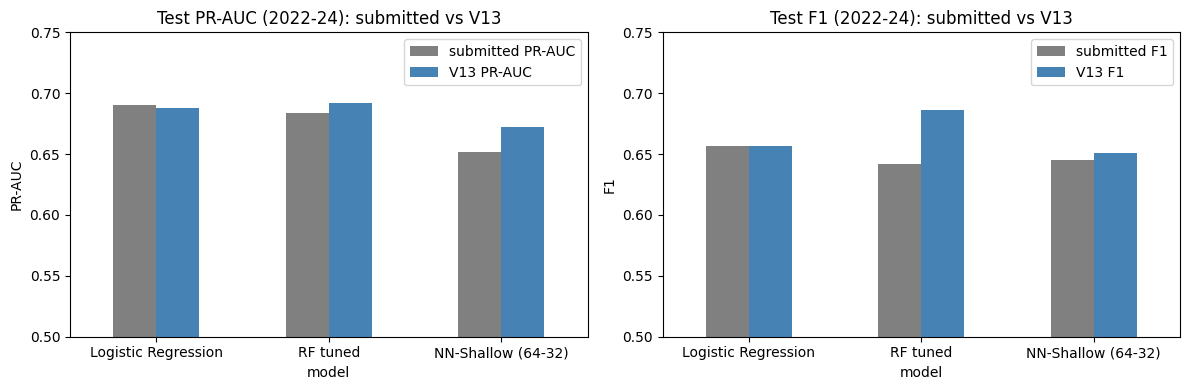

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
test_compare[['submitted PR-AUC', 'V13 PR-AUC']].plot(kind='bar', ax=axes[0], color=['grey', 'steelblue'], rot=0)
axes[0].set_title('Test PR-AUC (2022-24): submitted vs V13')
axes[0].set_ylabel('PR-AUC')
axes[0].set_ylim(0.5, 0.75)
test_compare[['submitted F1', 'V13 F1']].plot(kind='bar', ax=axes[1], color=['grey', 'steelblue'], rot=0)
axes[1].set_title('Test F1 (2022-24): submitted vs V13')
axes[1].set_ylabel('F1')
axes[1].set_ylim(0.5, 0.75)
for ax in axes:
    ax.set_xlabel('model')
plt.tight_layout()
plt.show()

**What we see:** the cells reproduce the bonus run of V13 exactly. On the 2019–21 validation seasons RF tuned
(max_depth 15, min_samples_leaf 20) is again the best model (PR-AUC 0.750), ahead of the logistic regression (0.712) and
NN-Shallow (0.700, stopped after 68 epochs, best epoch 53). On the same unseen 2022–24 seasons as section 15:
- **RF tuned** improves from PR-AUC 0.684 to **0.692** and F1 0.642 to **0.686**. It now finds 163 of the 204 test podiums
  instead of 124 (recall 0.608 → 0.799); precision falls from 0.681 to 0.601 because the threshold chosen on validation is
  lower (0.68 instead of 0.80).
- **NN-Shallow** gains the most PR-AUC (0.652 → 0.672); the logistic regression barely moves (0.690 → 0.688, F1 0.657 in both).

**Why V13 won**
- **Chosen without the test set:** V11, V12 and V13 share the 2019–21 validation seasons, and V13 has the best
  validation PR-AUC of the three (RF 0.750 vs 0.748 and 0.741).
- **Honest split:** it still splits by season with no shared races, and its 60-race validation makes the threshold
  and the forest settings less noisy than the 39 races of 2020–21.
- **Cleaning that follows the data's meaning:** a missing rank before round 1 means "no standing yet" and a debut
  means "no podium history", which the median got wrong.
- **Simpler:** 10 features instead of 12, with no loss.
- **Better on the unseen 2022–24 seasons than the submitted setup.**

**Caveat:** the gains are small (about 0.01 PR-AUC). V11 alone has a slightly higher RF test PR-AUC (0.698), but it would
not have been picked on validation. The main lesson of the bonus is that the submitted pipeline is already close to what
these features allow; the two choices that really change the numbers are leakage and the kind of split.